# All Figures for Fingerprint Ranking Paper

In [1]:
#Import everything
import statsmodels.api as sm
import scipy.stats as st
import openpyxl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
import cftime
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
from sklearn.metrics import mean_absolute_error, mean_squared_error
from scipy.stats import pearsonr
from scipy import stats
from numpy import mean
from numpy import std
from numpy import absolute
import pickle
from pandas import read_csv
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import RepeatedKFold
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split
import cartopy.crs as ccrs
import string
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import RobustScaler
import cartopy.feature as cfeature
from sklearn.decomposition import PCA
from sklearn import preprocessing

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib as mpl
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D as mlines
from matplotlib.colors import BoundaryNorm, ListedColormap
import matplotlib.cm as cm
from matplotlib.colors import TwoSlopeNorm
import joblib
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.lines import Line2D
from matplotlib.gridspec import GridSpec
import matplotlib.path as mpath
from matplotlib.path import Path
from matplotlib.lines import Line2D
from scipy.stats import percentileofscore
import pymannkendall as mk

In [2]:
# Normalise and then merge
def normalise(df):
    #df=df_og.drop("Model", axis=1)
    mean=df.mean()
    std=df.std()
    normalised_df=(df-mean)/std
    #normalised_df["Model"]=df["Model"]
    return normalised_df

In [3]:
def create_corr_plot(data, levels=None, title='', cmap_custom=None, 
                     colorbar_label="", title_fontsize=15,
                     vmin=None, vmax=None, ax=None):
    # Define custom colormap
    colors = [
        (0.0, 'darkblue'),
        (0.125, 'mediumblue'),
        (0.25, 'lightblue'),
        (0.375, 'skyblue'),
        (0.5, 'white'),
        (0.625, 'gold'),
        (0.75, 'orangered'),
        (0.875, 'red'),
        (1.0, 'firebrick')
    ]
    cmap_custom = mcolors.LinearSegmentedColormap.from_list('custom_RdYlBu_r', colors)

    extent = [-100, 40, -90, 90]

    if ax is None:
        raise ValueError("You must provide an axis (ax=...) when calling create_corr_plot.")

    ax.coastlines()

    if vmin is None or vmax is None:
        raise ValueError("Specify both vmin and vmax for consistent color scale.")

    # Extract data
    lons = data['lon'].values
    lats = data['lat'].values
    corr_values = data["Correlation"].values

    # Force-limit values
    corr_values = np.clip(corr_values, vmin, vmax)

    # Symmetric normalization
    norm = TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax)

    # Contourf
    contour = ax.tricontourf(
        lons, lats, corr_values,
        levels=levels,
        cmap=cmap_custom,
        norm=norm,
        transform=ccrs.PlateCarree()
    )

    ax.set_extent(extent, crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND, edgecolor='black', facecolor='k', zorder=10)

    gl = ax.gridlines(draw_labels=True, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 12}
    gl.ylabel_style = {'size': 12}

    ax.set_title(title, fontsize=title_fontsize)

    # IMPORTANT: return contour but DO NOT show and DO NOT add colorbar
    return contour


In [4]:
HadGEM3_moc=joblib.load(r"/p/tmp/baharem/August_25/processing/processed_dfs/moc_HadGem3_pi").iloc[:1000]
MPIESM_moc=joblib.load(r"/p/tmp/baharem/August_25/processing/processed_dfs/moc_MPI_pi")
CESM2_moc=joblib.load(r"/p/tmp/baharem/August_25/processing/processed_dfs/moc_CESM2_pi")
CanESM5_moc=joblib.load(r"/p/tmp/baharem/August_25/processing/processed_dfs/moc_CanESM5_pi")
MRI_moc=joblib.load(r"/p/tmp/baharem/August_25/processing/processed_dfs/moc_MRI_pi")

In [5]:
HadGEM3_msftbarot=joblib.load(r"/p/tmp/baharem/August_25/processing/processed_dfs/msftbarot_HadGem3_pi_df").iloc[:1000]
MPIESM_msftbarot=joblib.load(r"/p/tmp/baharem/August_25/processing/processed_dfs/msftbarot_MPI_pi_df")
CESM2_msftbarot=joblib.load(r"/p/tmp/baharem/August_25/processing/processed_dfs/msftbarot_CESM2_pi_df")
CanESM5_msftbarot=joblib.load(r"/p/tmp/baharem/August_25/processing/processed_dfs/msftbarot_CanESM5_pi_df")
MRI_msftbarot=joblib.load(r"/p/tmp/baharem/August_25/processing/processed_dfs/msftbarot_MRI_pi_df")

In [6]:
HadGEM3_sos=joblib.load(r"/p/tmp/baharem/August_25/processing/processed_dfs/sos_HadGem3_pi_df.joblib").iloc[:1000]
MPIESM_sos=joblib.load(r"/p/tmp/baharem/August_25/processing/processed_dfs/sos_MPI_pi_df.joblib")
CESM2_sos=joblib.load(r"/p/tmp/baharem/August_25/processing/processed_dfs/sos_CESM2_pi_df.joblib")
CanESM5_sos=joblib.load(r"/p/tmp/baharem/August_25/processing/processed_dfs/sos_CanESM5_pi_df.joblib")
MRI_sos=joblib.load(r"/p/tmp/baharem/August_25/processing/processed_dfs/sos_MRI_pi_df.joblib")

In [7]:
HadGEM3_tos=joblib.load(r"/p/tmp/baharem/August_25/processing/processed_dfs/tos_HadGem3_pi_df.joblib").iloc[:1000]
MPIESM_tos=joblib.load(r"/p/tmp/baharem/August_25/processing/processed_dfs/tos_MPI_pi_df.joblib")
CESM2_tos=joblib.load(r"/p/tmp/baharem/August_25/processing/processed_dfs/tos_CESM2_pi_df.joblib")
CanESM5_tos=joblib.load(r"/p/tmp/baharem/August_25/processing/processed_dfs/tos_CanESM5_pi_df.joblib")
MRI_tos=joblib.load(r"/p/tmp/baharem/August_25/processing/processed_dfs/tos_MRI_pi_df.joblib")

In [8]:
CESM2_tos_historical= joblib.load(r"/p/tmp/baharem/August_25/processing/processed_dfs/tos_CESM2_hist_df.joblib")
CanESM5_tos_historical=joblib.load( r"/p/tmp/baharem/August_25/processing/processed_dfs/tos_CanESM5_hist_df.joblib")
HadGEM3_tos_historical=joblib.load( r"/p/tmp/baharem/August_25/processing/processed_dfs/tos_HadGem3_hist_df.joblib")
MRI_tos_historical=joblib.load( r"/p/tmp/baharem/August_25/processing/processed_dfs/tos_MRI_hist_df.joblib")
MPIESM_tos_historical=joblib.load( r"/p/tmp/baharem/August_25/processing/processed_dfs/tos_MPI_hist_df.joblib")

In [9]:
CESM2_sos_historical= joblib.load(r"/p/tmp/baharem/August_25/processing/processed_dfs/sos_CESM2_hist_df.joblib")
CanESM5_sos_historical=joblib.load(  r"/p/tmp/baharem/August_25/processing/processed_dfs/sos_CanESM5_hist_df.joblib")
HadGEM3_sos_historical=joblib.load( r"/p/tmp/baharem/August_25/processing/processed_dfs/sos_HadGem3_hist_df.joblib")
MRI_sos_historical=joblib.load( r"/p/tmp/baharem/August_25/processing/processed_dfs/sos_MRI_hist_df.joblib")
MPIESM_sos_historical=joblib.load( r"/p/tmp/baharem/August_25/processing/processed_dfs/sos_MPI_hist_df.joblib")

In [10]:
CESM2_msftbarot_historical= joblib.load(r"/p/tmp/baharem/August_25/processing/processed_dfs/msftbarot_CESM2_hist_df")
CanESM5_msftbarot_historical=joblib.load( r"/p/tmp/baharem/August_25/processing/processed_dfs/msftbarot_CanESM5_hist_df")
HadGEM3_msftbarot_historical=joblib.load( r"/p/tmp/baharem/August_25/processing/processed_dfs/msftbarot_HadGem3_hist_df")
MRI_msftbarot_historical=joblib.load( r"/p/tmp/baharem/August_25/processing/processed_dfs/msftbarot_MRI_hist_df")
MPIESM_msftbarot_historical=joblib.load( r"/p/tmp/baharem/August_25/processing/processed_dfs/msftbarot_MPI_hist_df")

In [11]:
CESM2_moc_historical= joblib.load(r"/p/tmp/baharem/August_25/processing/processed_dfs/moc_CESM2_hist")
CanESM5_moc_historical=joblib.load( r"/p/tmp/baharem/August_25/processing/processed_dfs/moc_CanESM5_hist")
HadGEM3_moc_historical=joblib.load( r"/p/tmp/baharem/August_25/processing/processed_dfs/moc_HadGem3_hist")
MRI_moc_historical=joblib.load( r"/p/tmp/baharem/August_25/processing/processed_dfs/moc_MRI_hist")
MPIESM_moc_historical=joblib.load( r"/p/tmp/baharem/August_25/processing/processed_dfs/moc_MPI_hist")

In [12]:
HadISST_SST = xr.open_dataset(
    "/p/tmp/baharem/August_25/HadISST_trimmed.nc"
)
# this is monthly

In [13]:
# Open the dataset
ds=HadISST_SST
sst = ds["sst"]
sst = sst.where(sst > -900) # 1000 is missing data in HadISST


In [14]:
# Extract Nov-May months
nov_to_may = sst.sel(time=ds['time'].dt.month.isin([11, 12, 1, 2, 3, 4, 5]))

# Create a season year index (starting with Nov)
def custom_season_year(time):
    year = time.dt.year
    season_year = xr.where(time.dt.month >= 11, year + 1, year)
    return season_year

# Compute the season year for the dataset
season_years = custom_season_year(nov_to_may['time'])

# Group by this season-year and average
nov_may_avg = nov_to_may.groupby(season_years).mean(dim="time")

# Extract the Atlantic region
atlantic = nov_may_avg.sel(longitude=slice(-100, 40))


In [15]:
global_timemean=nov_may_avg.mean(dim=["group", "latitude", "longitude"])


In [16]:
normalised=(nov_may_avg- global_timemean)


In [17]:
# Stack spatial dimensions
sst_stack = normalised.stack(z=("latitude", "longitude"))

# Extract years from time
years = sst_stack["group"].values



In [18]:
def linear_trend(y, time):
    mask = np.isfinite(y)
    if mask.sum() < 2:
        return np.nan
    slope, _ = np.polyfit(time[mask], y[mask], 1)
    return slope * 100  # °C/century 

In [19]:
trend = xr.apply_ufunc(
    linear_trend,
    normalised,
    years,
    input_core_dims=[['group'], ['group']],
    vectorize=True,
    dask='parallelized',  # optional, if using dask
    output_dtypes=[float]
)


In [20]:
def linear_trend_forESM(y, time):
    slopes = np.polyfit(time, y.values, 1)[0]
    return slopes * 100  # °C / century

In [21]:
all_models=["CESM2", "HadGEM3", "MPIESM", "MRI", "CanESM5"]

In [22]:
trend_dfs = {}

for model in all_models:
    tos = globals()[f"{model}_tos_historical"]

    years = np.array([t.year for t in tos.index])

    tos_trend = tos.apply(
        lambda col: linear_trend_forESM(col, years),
        axis=0
    )

    tos_trend.name = "SST_trend"

    trend_df = tos_trend.reset_index()

    trend_df[["var", "lat", "lon"]] = (
        trend_df["index"].str.split("_", expand=True)
    )

    trend_df["lat"] = trend_df["lat"].astype(float)
    trend_df["lon"] = trend_df["lon"].astype(float)

    trend_df = trend_df.drop(columns="var")

    trend_map = (
        trend_df
        .pivot(index="lat", columns="lon", values="SST_trend")
        .sort_index()
    )

    trend_dfs[model] = trend_map


In [23]:
colors = [
    (0.0,   "#2166ac"),
    (0.125, "#4393c3"),
    (0.25,  "#92c5de"),
    (0.375, "#d1e5f0"),
    (0.5,   "#f7f7f7"),
    (0.625, "#fddbc7"),
    (0.75,  "#f4a582"),
    (0.875, "#d6604d"),
    (1.0,   "#b2182b"),
]

cmap_custom = mcolors.LinearSegmentedColormap.from_list(
    "custom_cmap",
    colors
)


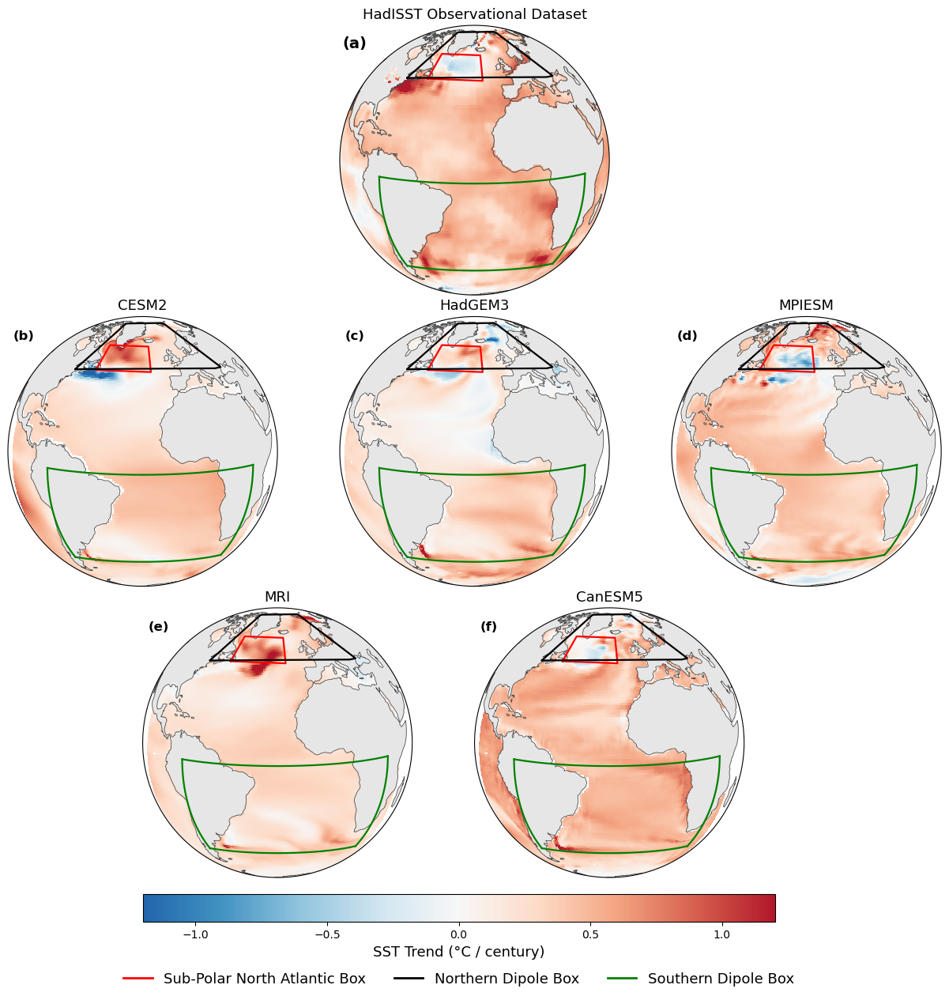

In [24]:
def make_globe(ax):
    theta = np.linspace(0, 2 * np.pi, 200)
    center = np.array([0.5, 0.5])
    radius = 0.5

    verts = np.vstack([
        np.sin(theta) * radius + center[0],
        np.cos(theta) * radius + center[1]
    ]).T

    ax.set_boundary(Path(verts), transform=ax.transAxes)

def plot_smooth_box(ax, lon_min, lon_max, lat_min, lat_max, **kwargs):
    n = 200

    ax.plot(
        np.linspace(lon_min, lon_max, n),
        np.full(n, lat_min),
        transform=ccrs.PlateCarree(),
        **kwargs
    )
    ax.plot(
        np.full(n, lon_max),
        np.linspace(lat_min, lat_max, n),
        transform=ccrs.PlateCarree(),
        **kwargs
    )
    ax.plot(
        np.linspace(lon_max, lon_min, n),
        np.full(n, lat_max),
        transform=ccrs.PlateCarree(),
        **kwargs
    )
    ax.plot(
        np.full(n, lon_min),
        np.linspace(lat_max, lat_min, n),
        transform=ccrs.PlateCarree(),
        **kwargs
    )

def draw_fingerprint_boxes(ax):
    # Subpolar North Atlantic (red)
    ax.plot(
        [-55, -20, -20, -55, -55],
        [46, 46, 61, 61, 46],
        color="red",
        linewidth=1.6,
        transform=ccrs.PlateCarree()
    )

    # Northern dipole (black)
    ax.plot(
        [-70, 30, 30, -70, -70],
        [45, 45, 80, 80, 45],
        color="black",
        linewidth=1.6,
        transform=ccrs.PlateCarree()
    )

    # Southern dipole (green, smooth)
    plot_smooth_box(
        ax,
        lon_min=-70,
        lon_max=30,
        lat_min=-45,
        lat_max=0,
        color="green",
        linewidth=1.6
    )


# =========================
# Projection
# =========================
proj_globe = ccrs.Orthographic(
    central_longitude=-25,
    central_latitude=10
)

# =========================
# Figure + layout
# =========================
fig = plt.figure(figsize=(16, 14))

gs = GridSpec(
    nrows=3,
    ncols=3,
    height_ratios=[1, 1, 1],
    hspace=0.08,
    wspace=0.05
)

# =========================
# Top panel (a)
# =========================
ax_top = fig.add_subplot(gs[0, :], projection=proj_globe)
ax_top.set_global()

pcm = ax_top.pcolormesh(
    trend.longitude,
    trend.latitude,
    trend,
    transform=ccrs.PlateCarree(),
    cmap=cmap_custom,
    vmin=-1.5,
    vmax=1.5
)

ax_top.coastlines(linewidth=0.7, color="0.3")
ax_top.add_feature(cfeature.LAND, facecolor="0.9", edgecolor="none")

draw_fingerprint_boxes(ax_top)

ax_top.text(
    0.01, 0.96, "(a)",
    transform=ax_top.transAxes,
    fontsize=14,
    fontweight="bold",
    va="top"
)

ax_top.set_title("HadISST Observational Dataset", fontsize=13)
make_globe(ax_top)

# =========================
# Sub-panels (b–f)
# =========================
ax_b = fig.add_subplot(gs[1, 0], projection=proj_globe)
ax_c = fig.add_subplot(gs[1, 1], projection=proj_globe)
ax_d = fig.add_subplot(gs[1, 2], projection=proj_globe)
ax_e = fig.add_subplot(gs[2, 0], projection=proj_globe)
ax_f = fig.add_subplot(gs[2, 1], projection=proj_globe)

axes = [ax_b, ax_c, ax_d, ax_e, ax_f]
models_to_plot = list(trend_dfs.keys())[:5]

# Center bottom row (e, f)
pos_e = ax_e.get_position()
pos_f = ax_f.get_position()
shift = pos_e.width / 2

ax_e.set_position([pos_e.x0 + shift, pos_e.y0, pos_e.width, pos_e.height])
ax_f.set_position([pos_f.x0 + shift, pos_f.y0, pos_f.width, pos_f.height])

for i, (ax, model) in enumerate(zip(axes, models_to_plot)):
    ax.set_global()

    trend_map = trend_dfs[model]

    pcm = ax.pcolormesh(
        trend_map.columns.values,
        trend_map.index.values,
        trend_map.values,
        transform=ccrs.PlateCarree(),
        cmap=cmap_custom,
        vmin=-1.2,
        vmax=1.2
    )

    ax.coastlines(linewidth=0.6, color="0.3")
    ax.add_feature(cfeature.LAND, facecolor="0.9", edgecolor="none")

    draw_fingerprint_boxes(ax)

    ax.set_title(model, fontsize=13)
    ax.text(
        0.02, 0.95,
        f"({chr(98 + i)})",
        transform=ax.transAxes,
        fontsize=12,
        fontweight="bold",
        va="top"
    )

    make_globe(ax)

# =========================
# Colorbar
# =========================
cax = fig.add_axes([0.25, 0.07, 0.5, 0.025])
cbar = fig.colorbar(pcm, cax=cax, orientation="horizontal")
cbar.set_label("SST Trend (°C / century)", fontsize=13)

# =========================
# Legend
# =========================
legend_handles = [
    Line2D([], [], color="red", linewidth=2,
           label="Sub-Polar North Atlantic Box"),
    Line2D([], [], color="black", linewidth=2,
           label="Northern Dipole Box"),
    Line2D([], [], color="green", linewidth=2,
           label="Southern Dipole Box"),
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0),
    ncol=3,
    frameon=False,
    fontsize=13
)

# =========================
# Save + show
# =========================
plt.savefig("SST_trends_single_page_globes.pdf", bbox_inches="tight")
plt.show()


In [25]:
def get_coords(df):
    split_index=df.index.str.split('_', expand=True)
    df['lat'] = split_index.get_level_values(1).astype(float)
    df['lon'] = split_index.get_level_values(2).astype(float)
    df['lon']=pd.to_numeric(df['lon'])
    df['lat']=pd.to_numeric(df['lat'])
    df["Correlation"]=pd.to_numeric(df[1000.0])
    df=pd.DataFrame(df)
    
    return df

    Ensuring the sos dfs are aligned and only the intersection of columns remain

In [26]:
windows    = [1, 5, 15, 20, 30]
all_models = ["CESM2", "HadGEM3", "MPIESM", "CanESM5", "MRI"]
piControl_sos_dict = {
    "HadGEM3": HadGEM3_sos,
    "MPIESM": MPIESM_sos,
    "CESM2": CESM2_sos,
    "CanESM5": CanESM5_sos,
    "MRI": MRI_sos,
}

historical_sos_dict = {
    "HadGEM3": HadGEM3_sos_historical,
    "MPIESM": MPIESM_sos_historical,
    "CESM2": CESM2_sos_historical,
    "CanESM5": CanESM5_sos_historical,
    "MRI": MRI_sos_historical,
}

# Dictionary to map models to their datasets
piControl_tos_dict = {
    "HadGEM3": HadGEM3_tos,
    "MPIESM": MPIESM_tos,
    "CESM2": CESM2_tos,
    "CanESM5": CanESM5_tos,
    "MRI": MRI_tos,
}

historical_tos_dict = {
    "HadGEM3": HadGEM3_tos_historical,
    "MPIESM": MPIESM_tos_historical,
    "CESM2": CESM2_tos_historical,
    "CanESM5": CanESM5_tos_historical,
    "MRI": MRI_tos_historical,
}

# Source data: raw_data[feature][run][model] → DataFrame
raw_data = {
    "sos": {
        "pi":   piControl_sos_dict,
        "hist": historical_sos_dict,
    },
    "tos": {
        "pi":   piControl_tos_dict,
        "hist": historical_tos_dict,
    },
}

# Output: processed_features_dict[feature][run][window][model] → DataFrame
processed_features_dict = {
    feature: {
        run: {w: {} for w in windows}
        for run in ("pi", "hist")
    }
    for feature in ("sos", "tos")
}

for feature in ("sos", "tos"):
    for model in all_models:

        pi_df   = raw_data[feature]["pi"][model].dropna()
        hist_df = raw_data[feature]["hist"][model].dropna()

        # Align columns once per (feature, model) pair
        common_cols = pi_df.columns.intersection(hist_df.columns)
        pi_df   = pi_df[common_cols]
        hist_df = hist_df[common_cols]

        for window in windows:
            processed_features_dict[feature]["pi"][window][model] = normalise(
                pi_df
                .rolling(window, center=True)
                .mean()
                .dropna()
            )
            processed_features_dict[feature]["hist"][window][model] = normalise(
                hist_df
                .rolling(window, center=True)
                .mean()
                .dropna()
            )


In [27]:
# # Dictionary to map models to their datasets
# piControl_sos_dict = {
#     "HadGEM3": HadGEM3_sos,
#     "MPIESM": MPIESM_sos,
#     "CESM2": CESM2_sos,
#     "CanESM5": CanESM5_sos,
#     "MRI": MRI_sos,
# }

# historical_sos_dict = {
#     "HadGEM3": HadGEM3_sos_historical,
#     "MPIESM": MPIESM_sos_historical,
#     "CESM2": CESM2_sos_historical,
#     "CanESM5": CanESM5_sos_historical,
#     "MRI": MRI_sos_historical,
# }

# processed_data_sos = {}

# for model in piControl_sos_dict:

#     if model not in historical_sos_dict:
#         continue

#     piControl_df = piControl_sos_dict[model]
#     historical_df = historical_sos_dict[model]

#     common_columns = piControl_df.columns.intersection(
#         historical_df.columns
#     )

#     piControl_df = (
#         piControl_df[common_columns]
#         .dropna(axis=0)
#     )

#     historical_df = (
#         historical_df[common_columns]
#         .dropna(axis=0)
#     )

#     processed_data_sos[model] = {

#         "piControl": {
#             "1": piControl_df,
#             "5": piControl_df.rolling(5, center=True).mean(),
#             "10": piControl_df.rolling(10, center=True).mean(),
#             "15": piControl_df.rolling(15, center=True).mean(),
#             "20": piControl_df.rolling(20, center=True).mean(),
#             "30": piControl_df.rolling(30, center=True).mean(),
#         },

#         "historical": {
#             "_1yr": historical_df,
#             "_5yr": historical_df.rolling(5, center=True).mean(),
#             "_10yr": historical_df.rolling(10, center=True).mean(),
#             "_15yr": historical_df.rolling(15, center=True).mean(),
#             "_20yr": historical_df.rolling(20, center=True).mean(),
#             "_30yr": historical_df.rolling(30, center=True).mean(),
#         },
#     }

In [28]:
# # Dictionary to map models to their datasets
# piControl_tos_dict = {
#     "HadGEM3": HadGEM3_tos,
#     "MPIESM": MPIESM_tos,
#     "CESM2": CESM2_tos,
#     "CanESM5": CanESM5_tos,
#     "MRI": MRI_tos,
# }

# historical_tos_dict = {
#     "HadGEM3": HadGEM3_tos_historical,
#     "MPIESM": MPIESM_tos_historical,
#     "CESM2": CESM2_tos_historical,
#     "CanESM5": CanESM5_tos_historical,
#     "MRI": MRI_tos_historical,
# }

# processed_data_tos = {}

# for model in piControl_tos_dict:

#     if model not in historical_tos_dict:
#         continue

#     piControl_df = piControl_tos_dict[model]
#     historical_df = historical_tos_dict[model]

#     common_columns = piControl_df.columns.intersection(
#         historical_df.columns
#     )

#     piControl_df = (
#         piControl_df[common_columns]
#         .dropna(axis=0)
#     )

#     historical_df = (
#         historical_df[common_columns]
#         .dropna(axis=0)
#     )

#     processed_data_tos[model] = {

#         "piControl": {
#             "_1yr": piControl_df,
#             "_5yr": piControl_df.rolling(5, center=True).mean(),
#             "_10yr": piControl_df.rolling(10, center=True).mean(),
#             "_15yr": piControl_df.rolling(15, center=True).mean(),
#             "_20yr": piControl_df.rolling(20, center=True).mean(),
#             "_30yr": piControl_df.rolling(30, center=True).mean(),
#         },

#         "historical": {
#             "_1yr": historical_df,
#             "_5yr": historical_df.rolling(5, center=True).mean(),
#             "_10yr": historical_df.rolling(10, center=True).mean(),
#             "_15yr": historical_df.rolling(15, center=True).mean(),
#             "_20yr": historical_df.rolling(20, center=True).mean(),
#             "_30yr": historical_df.rolling(30, center=True).mean(),
#         },
#     }

In [29]:
# windows = ["_1yr", "_5yr","_10yr", "_15yr", "_20yr", "_30yr"]

# processed_features_pi = {
#     "_1yr": {},
#     "_5yr": {},
#     "_10yr": {},
#     "_15yr": {},
#     "_20yr": {},
#     "_30yr": {},
# }

# processed_features_hist = {
#     "_1yr": {},
#     "_5yr": {},
#     "_10yr": {},
#     "_15yr": {},
#     "_20yr": {},
#     "_30yr": {},
# }

# for model in all_models:

#     for window in windows:

#         # ======================
#         # piControl
#         # ======================

#         tos = normalise(
#             processed_data_tos[model]["piControl"][window].dropna()
#         )

#         sos = normalise(
#             processed_data_sos[model]["piControl"][window].dropna()
#         )

#         tos["Model"] = model
#         sos["Model"] = model

#         tos = tos.reset_index()
#         sos = sos.reset_index()

#         processed_features_pi[window][model] = tos.merge(
#             sos,
#             on=["time", "Model"],
#             suffixes=("_tos", "_sos"),
#             how="inner",
#         )

#         # ======================
#         # historical
#         # ======================

#         tos = normalise(
#             processed_data_tos[model]["historical"][window].dropna()
#         )

#         sos = normalise(
#             processed_data_sos[model]["historical"][window].dropna()
#         )

#         tos["Model"] = model
#         sos["Model"] = model

#         tos = tos.reset_index()
#         sos = sos.reset_index()

#         processed_features_hist[window][model] = tos.merge(
#             sos,
#             on=["time", "Model"],
#             suffixes=("_tos", "_sos"),
#             how="inner",
#         )

In [30]:
piControl_moc_dict = {
    "HadGEM3": HadGEM3_moc,
    "MPIESM": MPIESM_moc,
    "CESM2": CESM2_moc,
    "CanESM5": CanESM5_moc,
    "MRI": MRI_moc,
}
historical_moc_dict = {
    "HadGEM3": HadGEM3_moc_historical,
    "MPIESM": MPIESM_moc_historical,
    "CESM2": CESM2_moc_historical,
    "CanESM5": CanESM5_moc_historical,
    "MRI": MRI_moc_historical,
}

piControl_msftbarot_dict = {
    "HadGEM3": HadGEM3_msftbarot,
    "MPIESM": MPIESM_msftbarot,
    "CESM2": CESM2_msftbarot,
    "CanESM5": CanESM5_msftbarot,
    "MRI": MRI_msftbarot,
}
historical_msftbarot_dict = {
    "HadGEM3": HadGEM3_msftbarot_historical,
    "MPIESM": MPIESM_msftbarot_historical,
    "CESM2": CESM2_msftbarot_historical,
    "CanESM5": CanESM5_msftbarot_historical,
    "MRI": MRI_msftbarot_historical,
}

In [31]:
piControl_moc_cleandict = {}
historical_moc_cleandict = {}
piControl_msftbarot_cleandict = {}
historical_msftbarot_cleandict = {}

for model in all_models:
    moc_df_pi = pd.DataFrame(piControl_moc_dict[model], columns=["MOC"])
    moc_df_pi.index.name = "time"                                    # = not ()

    moc_df_hist = pd.DataFrame(historical_moc_dict[model], columns=["MOC"])
    moc_df_hist.index.name = "time"

    msftbarot_pi   = piControl_msftbarot_dict[model].set_index("time")

    msftbarot_hist = historical_msftbarot_dict[model].set_index("time")
    moc_df_hist.index = msftbarot_hist.index                         # align index

    piControl_moc_cleandict[model]        = moc_df_pi
    historical_moc_cleandict[model]       = moc_df_hist
    piControl_msftbarot_cleandict[model]  = msftbarot_pi
    historical_msftbarot_cleandict[model] = msftbarot_hist
    


In [32]:
targets   = ("moc", "msftbarot")
runs      = ("pi", "hist")

processed_targets_dict = {
    target: {
        run: {
            window: {} for window in windows
        }
        for run in runs
    }
    for target in targets
}

for model in all_models:
    for window in windows:
        processed_targets_dict["moc"]["pi"][window][model] = normalise(
            piControl_moc_cleandict[model]
            .rolling(window, center=True).mean().dropna()
        )
        processed_targets_dict["moc"]["hist"][window][model] = normalise(
            historical_moc_cleandict[model]
            .rolling(window, center=True).mean().dropna()
        )
        processed_targets_dict["msftbarot"]["pi"][window][model] = normalise(
            piControl_msftbarot_cleandict[model]
            .rolling(window, center=True).mean().dropna()
        )
        processed_targets_dict["msftbarot"]["hist"][window][model] = normalise(
            historical_msftbarot_cleandict[model]
            .rolling(window, center=True).mean().dropna()
        )

# Access like:
# processed_targets_dict["msftbarot"]["pi"][5]["CESM2"]

    

In [33]:
# processed_targets_1yr_pi   = {}
# processed_targets_5yr_pi   = {}
# processed_targets_5yr_pi   = {}
# processed_targets_10yr_pi  = {}
# processed_targets_15yr_pi  = {}
# processed_targets_20yr_pi  = {}
# processed_targets_30yr_pi  = {}
# processed_targets_1yr_hist  = {}
# processed_targets_5yr_hist  = {}
# processed_targets_10yr_hist = {}
# processed_targets_15yr_hist = {}
# processed_targets_20yr_hist = {}
# processed_targets_30yr_hist = {}


# moc_1_pi = normalise(
#     moc_pi.dropna()
# ).to_frame(name="MOC")

# moc_5_pi = normalise(
#     moc_pi.rolling(5, center=True).mean().dropna()
# ).to_frame(name="MOC")

# moc_30_pi = normalise(
#     moc_pi.rolling(30, center=True).mean().dropna()
# ).to_frame(name="MOC")

# msftbarot_1_pi = normalise(
#     msftbarot_pi
#     .drop(columns="time")
#     .dropna()
#     .iloc[:, 0]
# ).to_frame(name="msftbarot")

# msftbarot_5_pi = normalise(
#     msftbarot_pi
#     .drop(columns="time")
#     .rolling(5, center=True)
#     .mean()
#     .dropna()
#     .iloc[:, 0]
# ).to_frame(name="msftbarot")

# msftbarot_30_pi = normalise(
#     msftbarot_pi
#     .drop(columns="time")
#     .rolling(30, center=True)
#     .mean()
#     .dropna()
#     .iloc[:, 0]
# ).to_frame(name="msftbarot")

# # --- enforce time index name ---
# for df in [moc_1_pi, moc_5_pi, moc_30_pi, msftbarot_1_pi, msftbarot_5_pi, msftbarot_30_pi]:
#     df.index.name = "time"
#     df["Model"] = model
#     df.reset_index(inplace=True)

# # --- merge ---
# processed_targets_1yr_pi[model] = moc_1_pi.merge(
#     msftbarot_1_pi,
#     on=["time", "Model"],
#     how="inner",
# )

# processed_targets_5yr_pi[model] = moc_5_pi.merge(
#     msftbarot_5_pi,
#     on=["time", "Model"],
#     how="inner",
# )

# processed_targets_30yr_pi[model] = moc_30_pi.merge(
#     msftbarot_30_pi,
#     on=["time", "Model"],
#     how="inner",
# )

# # ==========================================================
# # historical
# # ==========================================================
# moc_hist = historical_moc_dict[model].dropna()
# msftbarot_hist = historical_msftbarot_dict[model].dropna()

# moc_1_h = normalise(
#     moc_hist.dropna()
# ).to_frame(name="MOC")

# moc_5_h = normalise(
#     moc_hist.rolling(5, center=True).mean().dropna()
# ).to_frame(name="MOC")

# moc_30_h = normalise(
#     moc_hist.rolling(30, center=True).mean().dropna()
# ).to_frame(name="MOC")

# msftbarot_1_h = normalise(
#     msftbarot_hist
#     .drop(columns="time")
#     .dropna()
#     .iloc[:, 0]
# ).to_frame(name="msftbarot")

# msftbarot_5_h = normalise(
#     msftbarot_hist
#     .drop(columns="time")
#     .rolling(5, center=True)
#     .mean()
#     .dropna()
#     .iloc[:, 0]
# ).to_frame(name="msftbarot")

# msftbarot_30_h = normalise(
#     msftbarot_hist
#     .drop(columns="time")
#     .rolling(30, center=True)
#     .mean()
#     .dropna()
#     .iloc[:, 0]
# ).to_frame(name="msftbarot")

# for df in [moc_1_h, moc_5_h, moc_30_h, msftbarot_1_h, msftbarot_5_h, msftbarot_30_h]:
#     df.index.name = "time"
#     df["Model"] = model
#     df.reset_index(inplace=True)
# processed_targets_1yr_hist[model] = moc_1_h.merge(
#     msftbarot_1_h,
#     on=["time", "Model"],
#     how="inner",
# )
# processed_targets_5yr_hist[model] = moc_5_h.merge(
#     msftbarot_5_h,
#     on=["time", "Model"],
#     how="inner",
# )

# processed_targets_30yr_hist[model] = moc_30_h.merge(
#     msftbarot_30_h,
#     on=["time", "Model"],
#     how="inner",
# )


## Optimal Ridge Model for The Models

    HadGem3
    MPI
    CESM2
    CanESM5
    MRI

# MOC Fingerprints

In [34]:
# ------------------
# Setup
# ------------------
alpha_values = np.logspace(3, 7, num=5)

# Containers
MOC_pi_model_results = {w: {} for w in windows}
MOC_pi_model_coefs   = {w: {} for w in windows}
MOC_pi_ridge_models  = {w: {} for w in windows}

# ------------------
# Loop
# ------------------
for window in windows:
    print(f"\nRunning Ridge Regression for window = {window}")
    for model in all_models:
        print(f"  Processing model: {model}")
        # ------------------
        # Load features & target
        # ------------------
        features_sos = processed_features_dict["sos"]["pi"][window][model]
        features_tos = processed_features_dict["tos"]["pi"][window][model] 
        features=pd.concat([features_sos, features_tos], axis=1)
        moc      = processed_targets_dict["moc"]["pi"][window][model][["MOC"]] 

        # ------------------
        # Train / test split
        # ------------------
        X_train, X_test, y_train, y_test = train_test_split(
            features,
            moc,
            test_size=0.2,
            shuffle=False
        )

        # ------------------
        # Storage
        # ------------------
        results = {
            "Alpha": [],
            "Correlation": [],
            "MSE": [],
            "Test_Predictions": [],
            "True_Values": [],
            "Training_timeseries": []
        }

        coef_df = pd.DataFrame(
            index=alpha_values,
            columns=X_train.columns,
            dtype=float
        )

        # ------------------
        # Ridge loop
        # ------------------
        for i, alpha in enumerate(alpha_values):
            ridge = Ridge(alpha=alpha)
            ridge.fit(X_train, y_train.values.ravel())

            preds = ridge.predict(X_test)

            mse = mean_squared_error(y_test, preds)
            corr, _ = pearsonr(
                y_test.values.ravel(),
                preds.ravel()
            )

            results["Alpha"].append(alpha)
            results["Correlation"].append(corr)
            results["MSE"].append(mse)
            results["Test_Predictions"].append(preds)
            results["True_Values"].append(y_test.values.ravel())
            results["Training_timeseries"].append(y_train.values.ravel())

            coef_df.loc[alpha] = ridge.coef_

            if i == 0:
                MOC_pi_ridge_models[window][model] = ridge

        # ------------------
        # Save per model
        # ------------------
        MOC_pi_model_results[window][model] = pd.DataFrame(results)
        MOC_pi_model_coefs[window][model] = coef_df



Running Ridge Regression for window = 1
  Processing model: CESM2
  Processing model: HadGEM3
  Processing model: MPIESM
  Processing model: CanESM5
  Processing model: MRI

Running Ridge Regression for window = 5
  Processing model: CESM2
  Processing model: HadGEM3
  Processing model: MPIESM
  Processing model: CanESM5
  Processing model: MRI

Running Ridge Regression for window = 15
  Processing model: CESM2
  Processing model: HadGEM3
  Processing model: MPIESM
  Processing model: CanESM5
  Processing model: MRI

Running Ridge Regression for window = 20
  Processing model: CESM2
  Processing model: HadGEM3
  Processing model: MPIESM
  Processing model: CanESM5
  Processing model: MRI

Running Ridge Regression for window = 30
  Processing model: CESM2
  Processing model: HadGEM3
  Processing model: MPIESM
  Processing model: CanESM5
  Processing model: MRI


In [35]:
with PdfPages("5yr_MOC_RR_coefs.pdf") as pdf:
    fig, axes = plt.subplots(nrows=len(all_models), ncols=2, 
                             subplot_kw={'projection': ccrs.PlateCarree()},
                             figsize=(14, 5 * len(all_models)))

    if len(all_models) == 1:
        axes = axes.reshape(1, 2)  # Ensure 2D structure

    label_idx = 0

    for i, model in enumerate(all_models):
        result_coefs = MOC_pi_model_coefs[5][model].iloc[0]
        alpha = MOC_pi_model_results[5][model]["Alpha"].iloc[0]

        result_coefs_T = pd.DataFrame(result_coefs.T)
        result_coefs_T = get_coords(result_coefs_T)

        # SST plot
        sst_proj = result_coefs_T[result_coefs_T.index.str.startswith("SST")]
        ax_sst = axes[i, 0]
        contour_sst = create_corr_plot(sst_proj, title=f"{model} SST (α={alpha:.2e})", levels=11,
                                    colorbar_label="Ridge Weights", vmin=-0.003, vmax=0.003, ax=ax_sst)
        cb_sst = fig.colorbar(contour_sst, ax=ax_sst, orientation='vertical', pad=0.02, aspect=40)
        cb_sst.set_label("Ridge Weights")
        ax_sst.text(-0.08, 1.05, f"({string.ascii_lowercase[label_idx]})", transform=ax_sst.transAxes,
                    fontsize=14, fontweight='bold', va='top')
        label_idx += 1

        # SSS plot
        sss_proj = result_coefs_T[result_coefs_T.index.str.startswith("SSS")]
        ax_sss = axes[i, 1]
        contour_sss = create_corr_plot(sss_proj, title=f"{model} SSS", levels=11,
                                    colorbar_label="Ridge Weights", vmin=-0.0035, vmax=0.0035, ax=ax_sss)
        cb_sss = fig.colorbar(contour_sss, ax=ax_sss, orientation='vertical', pad=0.02, aspect=40)
        cb_sss.set_label("Ridge Weights")
        ax_sss.text(-0.08, 1.05, f"({string.ascii_lowercase[label_idx]})", transform=ax_sss.transAxes,
                    fontsize=14, fontweight='bold', va='top')
        label_idx += 1


    fig.tight_layout()
    pdf.savefig(fig)
    plt.close()

In [36]:
with PdfPages("30yr_MOC_RR_coefs.pdf") as pdf:
    fig, axes = plt.subplots(nrows=len(all_models), ncols=2, 
                             subplot_kw={'projection': ccrs.PlateCarree()},
                             figsize=(14, 5 * len(all_models)))

    if len(all_models) == 1:
        axes = axes.reshape(1, 2)  # Ensure 2D structure

    label_idx = 0

    for i, model in enumerate(all_models):
        result_coefs = MOC_pi_model_coefs[30][model].iloc[0]
        alpha = MOC_pi_model_results[30][model]["Alpha"].iloc[0]

        result_coefs_T = pd.DataFrame(result_coefs.T)
        result_coefs_T = get_coords(result_coefs_T)

        # SST plot
        sst_proj = result_coefs_T[result_coefs_T.index.str.startswith("SST")]
        ax_sst = axes[i, 0]
        contour_sst = create_corr_plot(sst_proj, title=f"{model} SST (α={alpha:.2e})", levels=11,
                                    colorbar_label="Ridge Weights", vmin=-0.003, vmax=0.003, ax=ax_sst)
        cb_sst = fig.colorbar(contour_sst, ax=ax_sst, orientation='vertical', pad=0.02, aspect=40)
        cb_sst.set_label("Ridge Weights")
        ax_sst.text(-0.08, 1.05, f"({string.ascii_lowercase[label_idx]})", transform=ax_sst.transAxes,
                    fontsize=14, fontweight='bold', va='top')
        label_idx += 1

        # SSS plot
        sss_proj = result_coefs_T[result_coefs_T.index.str.startswith("SSS")]
        ax_sss = axes[i, 1]
        contour_sss = create_corr_plot(sss_proj, title=f"{model} SSS", levels=11,
                                    colorbar_label="Ridge Weights", vmin=-0.0035, vmax=0.0035, ax=ax_sss)
        cb_sss = fig.colorbar(contour_sss, ax=ax_sss, orientation='vertical', pad=0.02, aspect=40)
        cb_sss.set_label("Ridge Weights")
        ax_sss.text(-0.08, 1.05, f"({string.ascii_lowercase[label_idx]})", transform=ax_sss.transAxes,
                    fontsize=14, fontweight='bold', va='top')
        label_idx += 1


    fig.tight_layout()
    pdf.savefig(fig)
    plt.close()

# SPG

In [37]:
# ------------------
# Setup
# ------------------
alpha_values = np.logspace(3, 7, num=5)

# Containers
SPG_pi_model_results = {w: {} for w in windows}
SPG_pi_model_coefs   = {w: {} for w in windows}
SPG_pi_ridge_models  = {w: {} for w in windows}

# ------------------
# Loop
# ------------------
for window in windows:
    print(f"\nRunning Ridge Regression for window = {window}")
    for model in all_models:
        print(f"  Processing model: {model}")
        # ------------------
        # Load features & target
        # ------------------
        features_sos = processed_features_dict["sos"]["pi"][window][model]
        features_tos = processed_features_dict["tos"]["pi"][window][model] 
        features=pd.concat([features_sos, features_tos], axis=1)
        spg      = processed_targets_dict["msftbarot"]["pi"][window][model][["min_value"]] 

        # ------------------
        # Train / test split
        # ------------------
        X_train, X_test, y_train, y_test = train_test_split(
            features,
            spg,
            test_size=0.2,
            shuffle=False
        )

        # ------------------
        # Storage
        # ------------------
        results = {
            "Alpha": [],
            "Correlation": [],
            "MSE": [],
            "Test_Predictions": [],
            "True_Values": [],
            "Training_timeseries": []
        }

        coef_df = pd.DataFrame(
            index=alpha_values,
            columns=X_train.columns,
            dtype=float
        )

        # ------------------
        # Ridge loop
        # ------------------
        for i, alpha in enumerate(alpha_values):
            ridge = Ridge(alpha=alpha)
            ridge.fit(X_train, y_train.values.ravel())

            preds = ridge.predict(X_test)

            mse = mean_squared_error(y_test, preds)
            corr, _ = pearsonr(
                y_test.values.ravel(),
                preds.ravel()
            )

            results["Alpha"].append(alpha)
            results["Correlation"].append(corr)
            results["MSE"].append(mse)
            results["Test_Predictions"].append(preds)
            results["True_Values"].append(y_test.values.ravel())
            results["Training_timeseries"].append(y_train.values.ravel())

            coef_df.loc[alpha] = ridge.coef_

            if i == 0:
                SPG_pi_ridge_models[window][model] = ridge

        # ------------------
        # Save per model
        # ------------------
        SPG_pi_model_results[window][model] = pd.DataFrame(results)
        SPG_pi_model_coefs[window][model] = coef_df

print("\nAll models processed for 1yr, 5yr, and 30yr windows.")


Running Ridge Regression for window = 1
  Processing model: CESM2
  Processing model: HadGEM3
  Processing model: MPIESM


  Processing model: CanESM5
  Processing model: MRI

Running Ridge Regression for window = 5
  Processing model: CESM2
  Processing model: HadGEM3
  Processing model: MPIESM
  Processing model: CanESM5
  Processing model: MRI

Running Ridge Regression for window = 15
  Processing model: CESM2
  Processing model: HadGEM3
  Processing model: MPIESM
  Processing model: CanESM5
  Processing model: MRI

Running Ridge Regression for window = 20
  Processing model: CESM2
  Processing model: HadGEM3
  Processing model: MPIESM
  Processing model: CanESM5
  Processing model: MRI

Running Ridge Regression for window = 30
  Processing model: CESM2
  Processing model: HadGEM3
  Processing model: MPIESM
  Processing model: CanESM5
  Processing model: MRI

All models processed for 1yr, 5yr, and 30yr windows.


In [38]:
with PdfPages("5yr_SPG_RR_coefs.pdf") as pdf:
    fig, axes = plt.subplots(nrows=len(all_models), ncols=2, 
                             subplot_kw={'projection': ccrs.PlateCarree()},
                             figsize=(14, 5 * len(all_models)))

    if len(all_models) == 1:
        axes = axes.reshape(1, 2)  # Ensure 2D structure

    label_idx = 0

    for i, model in enumerate(all_models):
        result_coefs = SPG_pi_model_coefs[5][model].iloc[0]
        alpha = SPG_pi_model_results[5][model]["Alpha"].iloc[0]

        result_coefs_T = pd.DataFrame(result_coefs.T)
        result_coefs_T = get_coords(result_coefs_T)

        # SST plot
        sst_proj = result_coefs_T[result_coefs_T.index.str.startswith("SST")]
        ax_sst = axes[i, 0]
        contour_sst = create_corr_plot(sst_proj, title=f"{model} SST (α={alpha:.2e})", levels=11,
                                    colorbar_label="Ridge Weights", vmin=-0.008, vmax=0.008, ax=ax_sst)
        cb_sst = fig.colorbar(contour_sst, ax=ax_sst, orientation='vertical', pad=0.02, aspect=40)
        cb_sst.set_label("Ridge Weights")
        ax_sst.text(-0.08, 1.05, f"({string.ascii_lowercase[label_idx]})", transform=ax_sst.transAxes,
                    fontsize=14, fontweight='bold', va='top')
        label_idx += 1

        # SSS plot
        sss_proj = result_coefs_T[result_coefs_T.index.str.startswith("SSS")]
        ax_sss = axes[i, 1]
        contour_sss = create_corr_plot(sss_proj, title=f"{model} SSS", levels=11,
                                    colorbar_label="Ridge Weights", vmin=-0.008, vmax=0.008, ax=ax_sss)
        cb_sss = fig.colorbar(contour_sss, ax=ax_sss, orientation='vertical', pad=0.02, aspect=40)
        cb_sss.set_label("Ridge Weights")
        ax_sss.text(-0.08, 1.05, f"({string.ascii_lowercase[label_idx]})", transform=ax_sss.transAxes,
                    fontsize=14, fontweight='bold', va='top')
        label_idx += 1


    fig.tight_layout()
    pdf.savefig(fig)
    plt.close()

In [39]:
with PdfPages("30yr_SPG_RR_coefs.pdf") as pdf:
    fig, axes = plt.subplots(nrows=len(all_models), ncols=2, 
                             subplot_kw={'projection': ccrs.PlateCarree()},
                             figsize=(14, 5 * len(all_models)))

    if len(all_models) == 1:
        axes = axes.reshape(1, 2)  # Ensure 2D structure

    label_idx = 0

    for i, model in enumerate(all_models):
        result_coefs = SPG_pi_model_coefs[30][model].iloc[0]
        alpha = SPG_pi_model_results[30][model]["Alpha"].iloc[0]

        result_coefs_T = pd.DataFrame(result_coefs.T)
        result_coefs_T = get_coords(result_coefs_T)

        # SST plot
        sst_proj = result_coefs_T[result_coefs_T.index.str.startswith("SST")]
        ax_sst = axes[i, 0]
        contour_sst = create_corr_plot(sst_proj, title=f"{model} SST (α={alpha:.2e})", levels=11,
                                    colorbar_label="Ridge Weights", vmin=-0.003, vmax=0.003, ax=ax_sst)
        cb_sst = fig.colorbar(contour_sst, ax=ax_sst, orientation='vertical', pad=0.02, aspect=40)
        cb_sst.set_label("Ridge Weights")
        ax_sst.text(-0.08, 1.05, f"({string.ascii_lowercase[label_idx]})", transform=ax_sst.transAxes,
                    fontsize=14, fontweight='bold', va='top')
        label_idx += 1

        # SSS plot
        sss_proj = result_coefs_T[result_coefs_T.index.str.startswith("SSS")]
        ax_sss = axes[i, 1]
        contour_sss = create_corr_plot(sss_proj, title=f"{model} SSS", levels=11,
                                    colorbar_label="Ridge Weights", vmin=-0.0035, vmax=0.0035, ax=ax_sss)
        cb_sss = fig.colorbar(contour_sss, ax=ax_sss, orientation='vertical', pad=0.02, aspect=40)
        cb_sss.set_label("Ridge Weights")
        ax_sss.text(-0.08, 1.05, f"({string.ascii_lowercase[label_idx]})", transform=ax_sss.transAxes,
                    fontsize=14, fontweight='bold', va='top')
        label_idx += 1


    fig.tight_layout()
    pdf.savefig(fig)
    plt.close()

# Investigating why RR can separate SPG and AMOC (physical insight)

In [40]:
def get_coords(df):
    # Extract lat/lon from index
    split_index = df.index.str.split('_', expand=True)
    df['lat'] = pd.to_numeric(split_index.get_level_values(1))
    df['lon'] = pd.to_numeric(split_index.get_level_values(2))

    # Identify the coefficient column automatically
    # The coefficient column is whatever column existed originally.
    coef_col = df.columns[0]     # works because df comes from result_coefs.T

    # Rename it to a consistent name
    df['Correlation'] = pd.to_numeric(df[coef_col])

    # Return only the useful columns (optional but tidy)
    # df = df[['Correlation', 'lat', 'lon']]  # uncomment if you like clean
    return df


In [41]:
coef_diff = {}

for model in all_models:
    # Extract the coefficient rows you want (iloc[2] in your version)
    spg = SPG_pi_model_coefs[5][model].iloc[2]
    moc = MOC_pi_model_coefs[5][model].iloc[0]

    # Align indices before subtracting
    spg_aligned = spg.reindex(moc.index)

    # Store difference
    coef_diff[model] = spg_aligned - moc

result_coefs_T = pd.DataFrame(coef_diff[model].T)
result_coefs_T = get_coords(result_coefs_T)


In [42]:
models_per_page = int(np.ceil(len(all_models) / 2))

with PdfPages("ridge_coefficients_diff.pdf") as pdf:
    for page in range(2):
        start_idx = page * models_per_page
        end_idx = min((page + 1) * models_per_page, len(all_models))
        current_models = all_models[start_idx:end_idx]

        fig, axes = plt.subplots(
            nrows=len(current_models),
            ncols=2,
            subplot_kw={'projection': ccrs.PlateCarree()},
            figsize=(14, 5 * len(current_models))
        )

        # Handle 1-row case
        if len(current_models) == 1:
            axes = axes.reshape(1, 2)

        label_idx = 2 * start_idx  # letter labels continue across pages

        for i, model in enumerate(current_models):

            # Convert diff into map-ready format
            diff_T = pd.DataFrame(coef_diff[model].T)
            diff_T = get_coords(diff_T)

            # SST diff
            sst_diff = diff_T[diff_T.index.str.startswith("SST")]
            ax_sst = axes[i, 0]

            contour_sst = create_corr_plot(
                sst_diff,
                title=f"{model} SPG − AMOC SST",
                levels=11,
                colorbar_label="Coefficient Difference",
                vmin=-0.015,
                vmax=0.015,
                ax=ax_sst
            )

            cb_sst = fig.colorbar(contour_sst, ax=ax_sst,
                                  orientation='vertical', pad=0.02, aspect=40)
            cb_sst.set_label("Coefficient Difference")

            ax_sst.text(
                -0.08, 1.05,
                f"({string.ascii_lowercase[label_idx]})",
                transform=ax_sst.transAxes,
                fontsize=14, fontweight='bold', va='top'
            )
            label_idx += 1

            # SSS diff
            sss_diff = diff_T[diff_T.index.str.startswith("SSS")]
            ax_sss = axes[i, 1]

            contour_sss = create_corr_plot(
                sss_diff,
                title=f"{model} SPG − AMOC SSS",
                levels=11,
                colorbar_label="Coefficient Difference",
                vmin=-0.015,
                vmax=0.015,
                ax=ax_sss
            )

            cb_sss = fig.colorbar(contour_sss, ax=ax_sss,
                                  orientation='vertical', pad=0.02, aspect=40)
            cb_sss.set_label("Coefficient Difference")

            ax_sss.text(
                -0.08, 1.05,
                f"({string.ascii_lowercase[label_idx]})",
                transform=ax_sss.transAxes,
                fontsize=14, fontweight='bold', va='top'
            )
            label_idx += 1

        fig.tight_layout()
        pdf.savefig(fig)
        plt.close()


In [43]:
avg_MOC_coefs = {}
avg_SPG_coefs = {}

# Collect series for averaging
MOC_list = []
SPG_list = []

for model in all_models:
    MOC_list.append(MOC_pi_model_coefs[5][model].iloc[0])
    SPG_list.append(SPG_pi_model_coefs[5][model].iloc[2])

# Convert to DataFrames and average
MOC_multi = pd.concat(MOC_list, axis=1).astype(float).mean(axis=1)
SPG_multi = pd.concat(SPG_list, axis=1).astype(float).mean(axis=1)



In [44]:
MOC_multi = pd.DataFrame(MOC_multi.T)
SPG_multi = pd.DataFrame(SPG_multi.T)


In [45]:
SPG_multi_df=get_coords(SPG_multi)
MOC_multi_df=get_coords(MOC_multi)

In [46]:
# Split SST / SSS
MOC_SST = MOC_multi_df[MOC_multi_df.index.str.startswith("SST")]
MOC_SSS = MOC_multi_df[MOC_multi_df.index.str.startswith("SSS")]

SPG_SST = SPG_multi_df[SPG_multi_df.index.str.startswith("SST")]
SPG_SSS = SPG_multi_df[SPG_multi_df.index.str.startswith("SSS")]

In [47]:
# Also the differences between the multimodel averages 
SST_diff=get_coords(pd.DataFrame(SPG_SST["Correlation"]-MOC_SST["Correlation"]))

SSS_diff=get_coords(pd.DataFrame(SPG_SSS["Correlation"]-MOC_SSS["Correlation"]))


In [48]:
with PdfPages("AVG_RR_coefficients_new.pdf") as pdf:

    # -------------------------------
    # PAGE 1: MOC/SPG SST + SSS
    # -------------------------------

    fig, axes = plt.subplots(
        nrows=2, ncols=2,
        subplot_kw={'projection': ccrs.PlateCarree()},
        figsize=(14, 10)
    )

    # Figure-level title + subtitle
    fig.suptitle(r"Multi Model Mean $RR5$ Coefficients", fontsize=16, y=0.98)
    #fig.text(0.5, 0.945, r"Coefficients for RR5_{MOC} and RR5_{SPG}",
    #          ha='center', fontsize=14)

    # MOC SST
    cs1 = create_corr_plot(
        MOC_SST,
        title=r"$RR5_{MOC}$ SST",
        levels=11,
        colorbar_label="Ridge Coefficients",
        vmin=-0.005,
        vmax=0.005,
        ax=axes[0, 0]
    )
    fig.colorbar(cs1, ax=axes[0, 0], orientation='vertical', pad=0.02, aspect=40)

    # MOC SSS
    cs2 = create_corr_plot(
        MOC_SSS,
        title=r"$RR5_{MOC}$ SSS",
        levels=11,
        colorbar_label="Ridge Coefficients",
        vmin=-0.005,
        vmax=0.005,
        ax=axes[0, 1]
    )
    fig.colorbar(cs2, ax=axes[0, 1], orientation='vertical', pad=0.02, aspect=40)

    # SPG SST
    cs3 = create_corr_plot(
        SPG_SST,
        title=r"$RR5_{SPG}$ SST",
        levels=11,
        colorbar_label="Ridge Coefficients",
        vmin=-0.005,
        vmax=0.005,
        ax=axes[1, 0]
    )
    fig.colorbar(cs3, ax=axes[1, 0], orientation='vertical', pad=0.02, aspect=40)

    # SPG SSS
    cs4 = create_corr_plot(
        SPG_SSS,
        title=r"$RR5_{SPG}$ SSS",
        levels=11,
        colorbar_label="Ridge Coefficients",
        vmin=-0.005,
        vmax=0.005,
        ax=axes[1, 1]
    )
    fig.colorbar(cs4, ax=axes[1, 1], orientation='vertical', pad=0.02, aspect=40)

    # Row labels to distinguish MOC vs SPG, placed just left of the leftmost column
    axes[0, 0].text(-0.2, 0.5, r"$RR5_{MOC}$", transform=axes[0, 0].transAxes,
                     rotation=90, va='center', ha='center', fontsize=13, fontweight='bold')
    axes[1, 0].text(-0.2, 0.5, r"$RR5_{SPG}$", transform=axes[1, 0].transAxes,
                     rotation=90, va='center', ha='center', fontsize=13, fontweight='bold')

    fig.tight_layout(rect=[0.02, 0, 1, 0.93])
    pdf.savefig(fig)
    plt.close()

    # -------------------------------
    # PAGE 2: SST_diff + SSS_diff
    # -------------------------------

    fig, axes = plt.subplots(
        nrows=1, ncols=2,
        subplot_kw={'projection': ccrs.PlateCarree()},
        figsize=(14, 5)
    )

    fig.suptitle(r"Multi Model Mean Difference of Coefficients: $RR5_{MOC}$ $-$ $RR5_{SPG}$",
                 fontsize=16,  y=0.9)
    #fig.text(0.5, 0.94, "Coefficient Differences Between MOC and SPG Regimes",
    #          ha='center', fontsize=11, style='italic', color='dimgray')

    cs5 = create_corr_plot(
        SST_diff,
        title="SST",
        levels=11,
        colorbar_label="Coefficient Difference",
        vmin=-0.005,
        vmax=0.005,
        ax=axes[0]
    )
    fig.colorbar(cs5, ax=axes[0], orientation='vertical', pad=0.02, aspect=40)

    cs6 = create_corr_plot(
        SSS_diff,
        title="SSS",
        levels=11,
        colorbar_label="Coefficient Difference",
        vmin=-0.005,
        vmax=0.005,
        ax=axes[1]
    )
    fig.colorbar(cs6, ax=axes[1], orientation='vertical', pad=0.02, aspect=40)

    fig.tight_layout(rect=[0, 0, 1, 0.9])
    pdf.savefig(fig)
    plt.close()

# Testing piControl trained SPG Ridge Fingerprint on Historical

Features are normalised in Historical period within themselves

In [49]:
# Containers
SPG_hist_model_results = {w: {} for w in windows}

# ------------------
# Loop
# ------------------
for window in windows:
    print(f"\nRunning Ridge Regression for window = {window}")
    for model in all_models:
        print(f"  Processing model: {model}")
        # ------------------
        # Load features & target
        # ------------------
        features_sos = processed_features_dict["sos"]["hist"][window][model]
        features_tos = processed_features_dict["tos"]["hist"][window][model] 
        features=pd.concat([features_sos, features_tos], axis=1)
        y_true      = processed_targets_dict["msftbarot"]["hist"][window][model][["min_value"]] 


        ridge_model = SPG_pi_ridge_models[window][model]

        # Prediction
        y_pred = ridge_model.predict(features)

        # Metrics
        mse = mean_squared_error(y_true.values.ravel() , y_pred)
        corr, _ = pearsonr(y_true.values.ravel() , y_pred)

        # Store
        SPG_hist_model_results[window][model] = {
            "Alpha": ridge_model.alpha,
            "Correlation": corr,
            "MSE": mse,
            "Historical_Predictions": y_pred,
            "True_Values": y_true,
        }





Running Ridge Regression for window = 1
  Processing model: CESM2
  Processing model: HadGEM3
  Processing model: MPIESM
  Processing model: CanESM5
  Processing model: MRI

Running Ridge Regression for window = 5
  Processing model: CESM2
  Processing model: HadGEM3
  Processing model: MPIESM
  Processing model: CanESM5
  Processing model: MRI

Running Ridge Regression for window = 15
  Processing model: CESM2
  Processing model: HadGEM3
  Processing model: MPIESM
  Processing model: CanESM5
  Processing model: MRI

Running Ridge Regression for window = 20
  Processing model: CESM2
  Processing model: HadGEM3
  Processing model: MPIESM
  Processing model: CanESM5
  Processing model: MRI

Running Ridge Regression for window = 30
  Processing model: CESM2
  Processing model: HadGEM3
  Processing model: MPIESM
  Processing model: CanESM5
  Processing model: MRI


# Testing piControl Trained MOC fingerprint on Historical MOC

In [50]:
# Containers
MOC_hist_model_results = {w: {} for w in windows}

# ------------------
# Loop
# ------------------
for window in windows:
    print(f"\nRunning Ridge Regression for window = {window}")
    for model in all_models:
        print(f"  Processing model: {model}")
        # ------------------
        # Load features & target
        # ------------------
        features_sos = processed_features_dict["sos"]["hist"][window][model]
        features_tos = processed_features_dict["tos"]["hist"][window][model] 
        features=pd.concat([features_sos, features_tos], axis=1)
        y_true      = processed_targets_dict["moc"]["hist"][window][model][["MOC"]] 


        ridge_model = MOC_pi_ridge_models[window][model]

        # Prediction
        y_pred = ridge_model.predict(features)

        # Metrics
        mse = mean_squared_error(y_true.values.ravel(), y_pred)
        corr, _ = pearsonr(y_true.values.ravel(), y_pred)

        # Store
        MOC_hist_model_results[window][model] = {
            "Alpha": ridge_model.alpha,
            "Correlation": corr,
            "MSE": mse,
            "Historical_Predictions": y_pred,
            "True_Values": y_true,
        }




Running Ridge Regression for window = 1
  Processing model: CESM2
  Processing model: HadGEM3
  Processing model: MPIESM
  Processing model: CanESM5
  Processing model: MRI

Running Ridge Regression for window = 5
  Processing model: CESM2
  Processing model: HadGEM3
  Processing model: MPIESM
  Processing model: CanESM5
  Processing model: MRI

Running Ridge Regression for window = 15
  Processing model: CESM2
  Processing model: HadGEM3
  Processing model: MPIESM
  Processing model: CanESM5
  Processing model: MRI

Running Ridge Regression for window = 20
  Processing model: CESM2
  Processing model: HadGEM3
  Processing model: MPIESM
  Processing model: CanESM5
  Processing model: MRI

Running Ridge Regression for window = 30
  Processing model: CESM2
  Processing model: HadGEM3
  Processing model: MPIESM
  Processing model: CanESM5
  Processing model: MRI


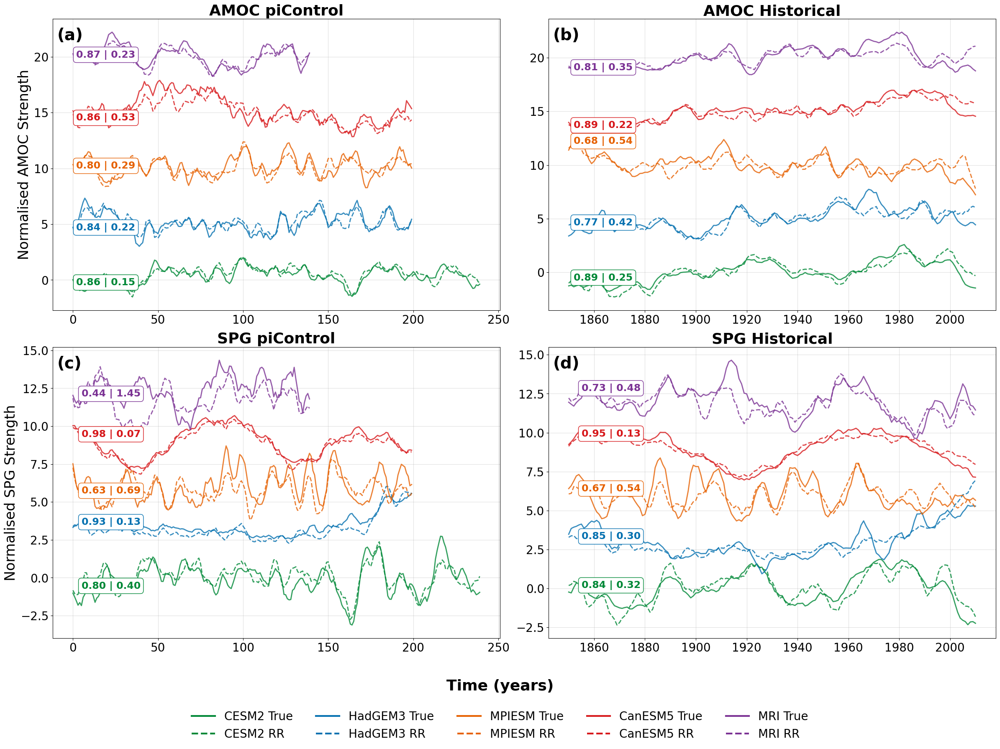

In [51]:
# =========================
# --- MODEL COLOR FUNC ----
# =========================
def get_model_color(model_name):
    name = str(model_name).upper()
    if 'HADGEM' in name: return '#0571b0'
    if 'MPI' in name: return '#e66101'
    if 'CESM' in name: return '#008837'
    if 'CANESM' in name: return '#d7191c'
    if 'MRI' in name: return '#7b3294'
    return 'gray'

# =========================
# --- FIGURE SETUP --------
# =========================
fig, axes = plt.subplots(2, 2, figsize=(24, 18), sharey=False)
(ax_a, ax_b), (ax_c, ax_d) = axes

panel_labels = ['(a)', '(b)', '(c)', '(d)']
for ax, label in zip(axes.flatten(), panel_labels):
    ax.text(0.01, 0.97, label, transform=ax.transAxes,
            fontsize=28, fontweight='bold', va='top', ha='left')

title_size = 26
label_size = 24
tick_size = 20
annot_size = 17

# =========================
# --- AMOC PLOTTING -------
# =========================
offset = 0

for model in all_models:
    color = get_model_color(model)

    results_pi = MOC_pi_model_results[5][model]
    results_hist = MOC_hist_model_results[5][model]

    pi_preds = results_pi.iloc[0]["Test_Predictions"]
    hist_preds = results_hist["Historical_Predictions"]
    pi_val = results_pi.iloc[0]["True_Values"]
    hist_val = results_hist["True_Values"]

    corr_pi = results_pi.iloc[0]["Correlation"]
    corr_hist = results_hist["Correlation"]
    mse_pi = results_pi.iloc[0]["MSE"]
    mse_hist = results_hist["MSE"]

    time_pi = np.arange(len(pi_preds))
    time_hist = np.arange(1850, 1850 + len(hist_preds))

    # Offset
    pi_val_off = pi_val + offset
    pi_preds_off = pi_preds + offset
    hist_val_off = hist_val + offset
    hist_preds_off = hist_preds + offset

    # --- piControl
    ax_a.plot(time_pi, pi_val_off, color=color, lw=2, alpha=0.8)
    ax_a.plot(time_pi, pi_preds_off, '--', color=color, lw=2, alpha=0.8)

    ax_a.text(time_pi[2], pi_preds_off[2],
              f"{corr_pi:.2f} | {mse_pi:.2f}",
              color=color, fontsize=annot_size, fontweight='bold',
              bbox=dict(facecolor="white", edgecolor=color, boxstyle="round,pad=0.3"))

    # --- Historical
    ax_b.plot(time_hist, hist_val_off, color=color, lw=2, alpha=0.8)
    ax_b.plot(time_hist, hist_preds_off, '--', color=color, lw=2, alpha=0.8)

    ax_b.text(time_hist[2], hist_preds_off[2],
              f"{corr_hist:.2f} | {mse_hist:.2f}",
              color=color, fontsize=annot_size, fontweight='bold',
              bbox=dict(facecolor="white", edgecolor=color, boxstyle="round,pad=0.3"))

    offset += 5


ax_a.set_title("AMOC piControl", fontsize=title_size, fontweight="bold")
ax_b.set_title("AMOC Historical", fontsize=title_size, fontweight="bold")
ax_a.set_ylabel("Normalised AMOC Strength", fontsize=label_size)


# =========================
# --- SPG PLOTTING --------
# =========================
offset = 0

for model in all_models:
    color = get_model_color(model)

    results_pi = SPG_pi_model_results[5][model]
    results_hist = SPG_hist_model_results[5][model]

    pi_preds = results_pi.iloc[0]["Test_Predictions"]
    hist_preds = results_hist["Historical_Predictions"]
    pi_val = results_pi.iloc[0]["True_Values"]
    hist_val = results_hist["True_Values"]

    corr_pi = results_pi.iloc[0]["Correlation"]
    corr_hist = results_hist["Correlation"]
    mse_pi = results_pi.iloc[0]["MSE"]
    mse_hist = results_hist["MSE"]

    time_pi = np.arange(len(pi_preds))
    time_hist = np.arange(1850, 1850 + len(hist_preds))

    # Offset
    pi_val_off = pi_val + offset
    pi_preds_off = pi_preds + offset
    hist_val_off = hist_val + offset
    hist_preds_off = hist_preds + offset

    # --- piControl
    ax_c.plot(time_pi, pi_val_off, color=color, lw=2, alpha=0.8)
    ax_c.plot(time_pi, pi_preds_off, '--', color=color, lw=2, alpha=0.8)

    ax_c.text(time_pi[5], pi_preds_off[5],
              f"{corr_pi:.2f} | {mse_pi:.2f}",
              color=color, fontsize=annot_size, fontweight='bold',
              bbox=dict(facecolor="white", edgecolor=color, boxstyle="round,pad=0.3"))

    # --- Historical
    ax_d.plot(time_hist, hist_val_off, color=color, lw=2, alpha=0.8)
    ax_d.plot(time_hist, hist_preds_off, '--', color=color, lw=2, alpha=0.8)

    ax_d.text(time_hist[5], hist_preds_off[5],
              f"{corr_hist:.2f} | {mse_hist:.2f}",
              color=color, fontsize=annot_size, fontweight='bold',
              bbox=dict(facecolor="white", edgecolor=color, boxstyle="round,pad=0.3"))

    offset += 3


ax_c.set_title("SPG piControl", fontsize=title_size, fontweight="bold")
ax_d.set_title("SPG Historical", fontsize=title_size, fontweight="bold")
ax_c.set_ylabel("Normalised SPG Strength", fontsize=label_size)


# =========================
# --- AXIS FORMATTING -----
# =========================
for ax in axes.flatten():
    ax.tick_params(axis='both', labelsize=tick_size)
# Faded gridlines
    ax.grid(True,
            linestyle='-',
            linewidth=0.8,
            alpha=0.4)

fig.text(0.5, 0.04, "Time (years)", ha='center',
         fontsize=26, fontweight="bold")



# =========================
# --- LEGEND --------------
# =========================
legend_handles = []

for model in all_models:
    color = get_model_color(model)

    # True line
    legend_handles.append(
        Line2D([], [], color=color, lw=3,
               linestyle='-',
               label=f'{model} True')
    )

    # RR prediction
    legend_handles.append(
        Line2D([], [], color=color, lw=3,
               linestyle='--',
               label=f'{model} RR')
    )

fig.legend(handles=legend_handles,
           loc='lower center',
           ncol=5,
           fontsize=20,
           frameon=False,
           bbox_to_anchor=(0.5, -0.04))



# =========================
# --- SAVE FIGURE ---------
# =========================
plt.tight_layout(rect=[0, 0.08, 1, 0.96])

plt.savefig("Timeseries.pdf", dpi=300, bbox_inches='tight')

plt.show()

    The timeseries plots belong to a 5 year rolling mean

# Calculating whether the trend is well captured by the fingerprint

In [52]:
trend_results = []
for model in all_models:

    # --- extract data ---
    test_preds = np.asarray(
        MOC_hist_model_results[30][model]["Historical_Predictions"]
    )
    true_values = np.asarray(
        MOC_hist_model_results[30][model]["True_Values"]).ravel()
    

    # --- time axis ---
    n = min(len(test_preds), len(true_values))
    time = np.arange(n)

    test_preds = test_preds[:n]
    true_values = true_values[:n]

    # --- linear fits ---
    slope_preds, intercept_preds = np.polyfit(time, test_preds, 1)
    slope_true, intercept_true   = np.polyfit(time, true_values, 1)

    # --- store ---
    trend_results.append({
        "Model": model,
        "Slope_Predictions": slope_preds*100,
        "Slope_True": slope_true*100
    })
trend_df = pd.DataFrame(trend_results)


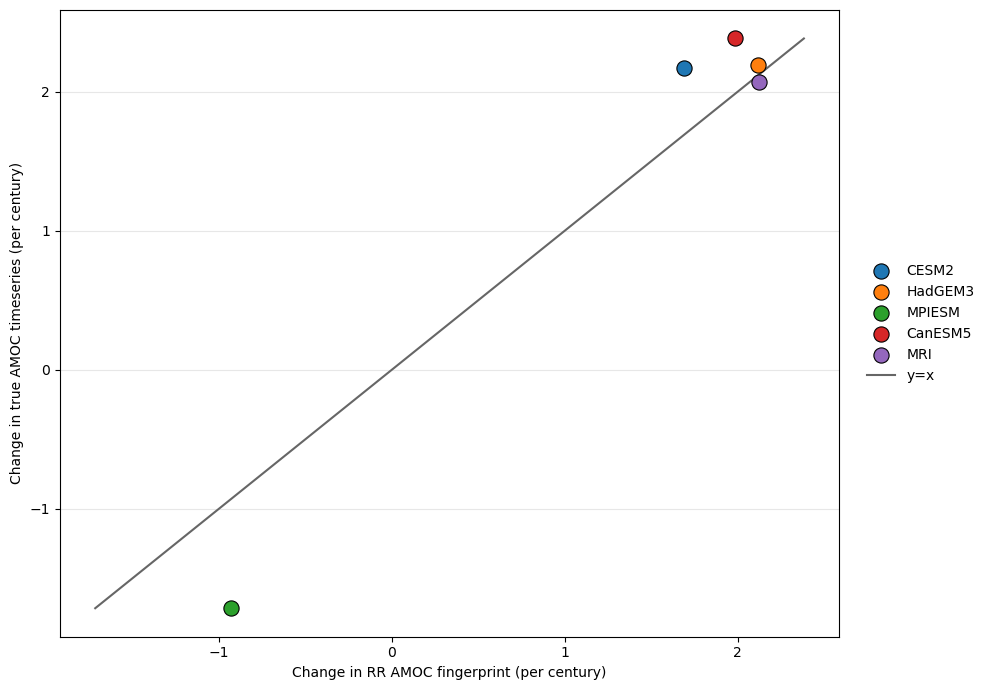

In [53]:
fig, ax = plt.subplots(figsize=(10, 7))

# soft colour cycle (Matplotlib default is already good)
for _, row in trend_df.iterrows():
    ax.scatter(
        row["Slope_Predictions"],
        row["Slope_True"],
        s=120,
        edgecolor="black",
        linewidth=0.8,
        zorder=3,
        label=row["Model"]
    )

# 1:1 line (subtle, not dominant)
lims = [
    trend_df[["Slope_Predictions", "Slope_True"]].min().min(),
    trend_df[["Slope_Predictions", "Slope_True"]].max().max()
]
ax.plot(
    lims, lims,
    linestyle="-",
    color="0.4",
    linewidth=1.5,
    zorder=2,
    label="y=x"
)

# labels
ax.set_xlabel("Change in RR AMOC fingerprint (per century)")
ax.set_ylabel("Change in true AMOC timeseries (per century)")

# light grid only on y (very paper-like)
ax.grid(axis="y", alpha=0.3)
ax.grid(axis="x", alpha=0.0)

# legend outside (prevents clutter)
ax.legend(
    frameon=False,
    loc="center left",
    bbox_to_anchor=(1.02, 0.5)
)

plt.tight_layout()
plt.savefig(
    "AMOC_trend_scatter_30.pdf",
    format="pdf",
    bbox_inches="tight"
)
plt.show()

In [54]:
trend_results = []
for model in all_models:

    # --- extract data ---
    test_preds = np.asarray(
        MOC_hist_model_results[5][model]["Historical_Predictions"]
    )
    true_values = np.asarray(
        MOC_hist_model_results[5][model]["True_Values"]).ravel()
    

    # --- time axis ---
    n = min(len(test_preds), len(true_values))
    time = np.arange(n)

    test_preds = test_preds[:n]
    true_values = true_values[:n]

    # --- linear fits ---
    slope_preds, intercept_preds = np.polyfit(time, test_preds, 1)
    slope_true, intercept_true   = np.polyfit(time, true_values, 1)

    # --- store ---
    trend_results.append({
        "Model": model,
        "Slope_Predictions": slope_preds*100,
        "Slope_True": slope_true*100
    })
trend_df = pd.DataFrame(trend_results)

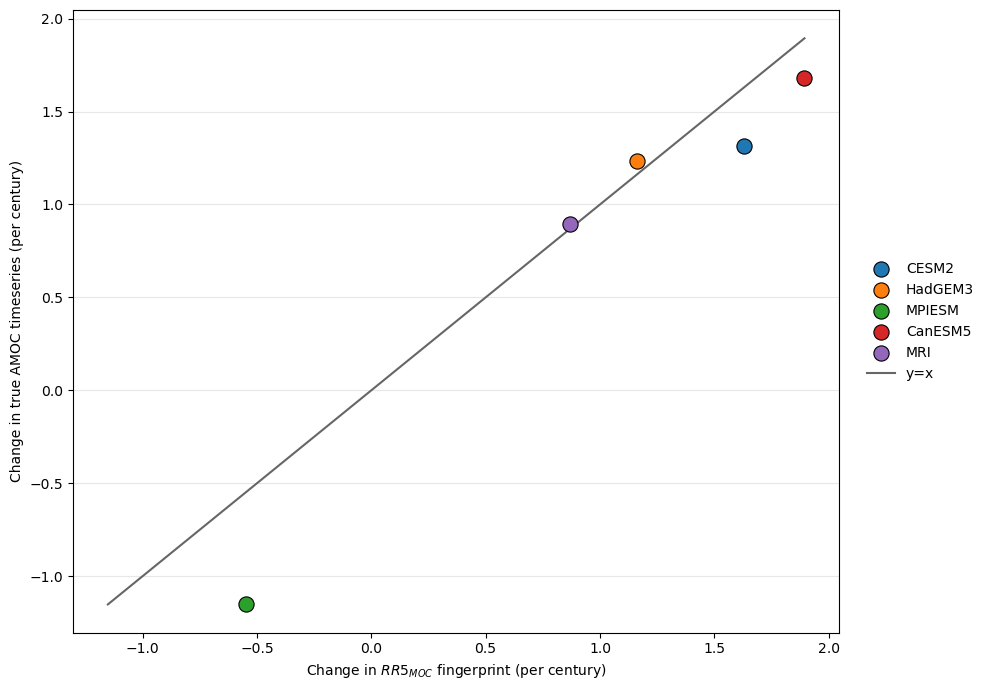

In [55]:
fig, ax = plt.subplots(figsize=(10, 7))

# soft colour cycle (Matplotlib default is already good)
for _, row in trend_df.iterrows():
    ax.scatter(
        row["Slope_Predictions"],
        row["Slope_True"],
        s=120,
        edgecolor="black",
        linewidth=0.8,
        zorder=3,
        label=row["Model"]
    )

# 1:1 line (subtle, not dominant)
lims = [
    trend_df[["Slope_Predictions", "Slope_True"]].min().min(),
    trend_df[["Slope_Predictions", "Slope_True"]].max().max()
]
ax.plot(
    lims, lims,
    linestyle="-",
    color="0.4",
    linewidth=1.5,
    zorder=2,
    label="y=x"
)

# labels
ax.set_xlabel(r"Change in $RR5_{MOC}$ fingerprint (per century)")
ax.set_ylabel("Change in true AMOC timeseries (per century)")

# light grid only on y (very paper-like)
ax.grid(axis="y", alpha=0.3)
ax.grid(axis="x", alpha=0.0)

# legend outside (prevents clutter)
ax.legend(
    frameon=False,
    loc="center left",
    bbox_to_anchor=(1.02, 0.5)
)

plt.tight_layout()
plt.savefig(
    "AMOC_trend_scatter.pdf",
    format="pdf",
    bbox_inches="tight"
)
#plt.show()


In [56]:
# test_preds=MOC_hist_model_results[5]["CESM2"]["Historical_Predictions"]
# true_values=MOC_hist_model_results[5]["CESM2"]["True_Values"]
# time=np.arange(0, len(true_values), 1)

# slope_preds, intercept_preds = np.polyfit(time, test_preds, 1)
# slope_true, intercept_true   = np.polyfit(time, true_values, 1)
# print(f"Slope (ridge predictions): {slope_preds}")
# print(f"Slope (true values):       {slope_true}")

# plt.figure(figsize=(7, 4))

# plt.plot(time, test_preds, label="Ridge predictions", alpha=0.6)
# plt.plot(time, true_values, label="True values", alpha=0.6)

# plt.plot(time, slope_preds * time + intercept_preds,
#          linestyle="--", label="Fit: ridge")

# plt.plot(time, slope_true * time + intercept_true,
#          linestyle="--", label="Fit: true")

# plt.xlabel("Time")
# plt.ylabel("AMOC (units or nondimensional)")
# plt.title("CESM2 Historical")
# plt.legend()
# plt.tight_layout()
# plt.show()




# Correlation between AMOC and SPG in true and RR

In [57]:
SPG_MOC_corrs=[]

for model in all_models:
    # Extract predictions and true values for SPG and MOC

    
    spg_fingerprint_picontrol = SPG_pi_model_results[5][model]["Test_Predictions"].iloc[0]
    moc_fingerprint_picontrol = MOC_pi_model_results[5][model]["Test_Predictions"].iloc[0]
    spg_real_picontrol= SPG_pi_model_results[5][model]["True_Values"].iloc[0]
    moc_real_picontrol= MOC_pi_model_results[5][model]["True_Values"].iloc[0]

    spg_fingerprint_historical = SPG_hist_model_results[5][model]["Historical_Predictions"]
    moc_fingerprint_historical = MOC_hist_model_results[5][model]["Historical_Predictions"]
    spg_real_historical = SPG_hist_model_results[5][model]["True_Values"].values.ravel()
    moc_real_historical = MOC_hist_model_results[5][model]["True_Values"].values.ravel()
    
    # Calculate correlations
    fingerprint_corr_historical = np.corrcoef(spg_fingerprint_historical, moc_fingerprint_historical)[0, 1]
    true_corr_historical = np.corrcoef(spg_real_historical, moc_real_historical)[0, 1]
    # Calculate correlations
    fingerprint_corr_piControl = np.corrcoef(spg_fingerprint_picontrol, moc_fingerprint_picontrol)[0, 1]
    true_corr_piControl = np.corrcoef(spg_real_picontrol, moc_real_picontrol)[0, 1]
    
    # Append results to the list
    SPG_MOC_corrs.append({"Model": model, 
                       "Fingerprint_Corr_Historical": fingerprint_corr_historical, 
                       "True_Corr_Historical": true_corr_historical, 
                       "Fingerprint_corr_piControl": fingerprint_corr_piControl, 
                       "true_corr_picontrol": true_corr_piControl})

# Convert the list of dictionaries to a dataframe
SPG_MOC_corrs_df = pd.DataFrame(SPG_MOC_corrs)
SPG_MOC_corrs_df

,Model,Fingerprint_Corr_Historical,True_Corr_Historical,Fingerprint_corr_piControl,true_corr_picontrol
0,CESM2,0.736156,0.754132,0.528924,0.584938
1,HadGEM3,0.372014,0.147212,0.108812,0.240022
2,MPIESM,0.103464,0.254160,0.282566,0.417096
3,CanESM5,-0.001486,-0.116216,0.141352,-0.066119
4,MRI,-0.162350,-0.093947,0.146885,-0.308096


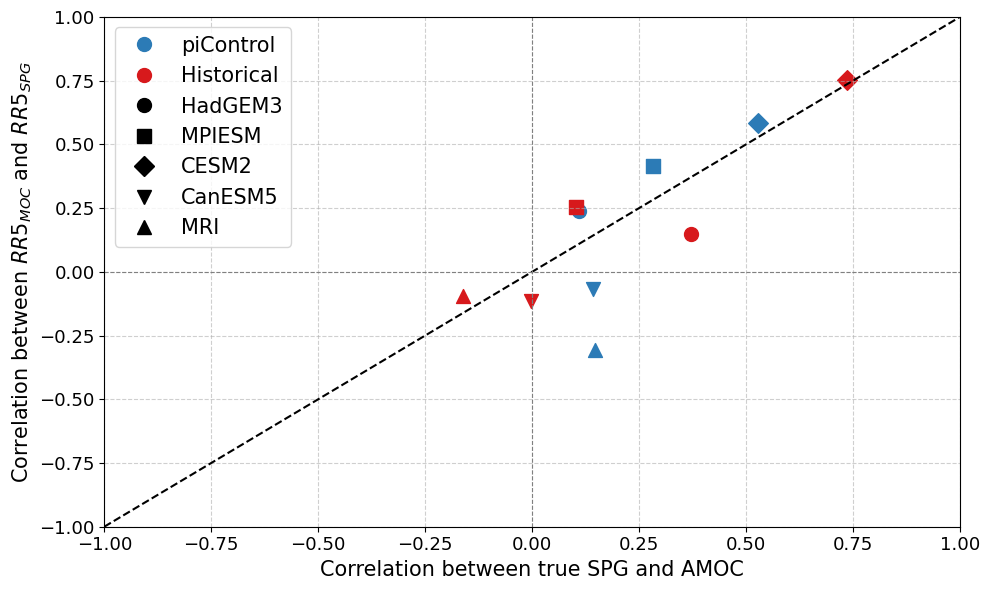

In [58]:
# Define markers for each model
markers = {
    "HadGEM3": "o",  # Circle
    "MPIESM": "s",      # Square
    "CESM2": "D",    # Diamond
    "CanESM5": "v",  # Downward triangle
    "MRI": "^"       # Upward triangle
}

# Define colors for datasets
dataset_colors = {
    "piControl": "#2c7bb6",
    "historical": "#d7191c"
}

# Plot
plt.figure(figsize=(10, 6))
for model in all_models:
    pi_fingerprint = SPG_MOC_corrs_df[SPG_MOC_corrs_df["Model"] == model]["Fingerprint_corr_piControl"]
    pi_true = SPG_MOC_corrs_df[SPG_MOC_corrs_df["Model"] == model]["true_corr_picontrol"]
    hist_fingerprint = SPG_MOC_corrs_df[SPG_MOC_corrs_df["Model"] == model]["Fingerprint_Corr_Historical"]
    hist_true = SPG_MOC_corrs_df[SPG_MOC_corrs_df["Model"] == model]["True_Corr_Historical"]
    
    # Plot piControl in blue
    plt.scatter(pi_fingerprint, pi_true, 
                color=dataset_colors["piControl"], 
                marker=markers[model], s=100)
    # Plot historical in red
    plt.scatter(hist_fingerprint, hist_true, 
                color=dataset_colors["historical"], 
                marker=markers[model], s=100)

# Add a 1:1 line
x_vals = np.linspace(-1, 1, 500)  # Adjust range if needed
plt.plot(x_vals, x_vals, color="black", linestyle="--")

# Create a custom legend
legend_elements = [
    plt.Line2D([0], [0], color=dataset_colors["piControl"], marker='o', linestyle='', markersize=10, label="piControl"),
    plt.Line2D([0], [0], color=dataset_colors["historical"], marker='o', linestyle='', markersize=10, label="Historical"),
    plt.Line2D([0], [0], color='black', marker="o", linestyle='', markersize=10, label="HadGEM3"),
    plt.Line2D([0], [0], color='black', marker="s", linestyle='', markersize=10, label="MPIESM"),
    plt.Line2D([0], [0], color='black', marker="D", linestyle='', markersize=10, label="CESM2"),
    plt.Line2D([0], [0], color='black', marker="v", linestyle='', markersize=10, label="CanESM5"),
    plt.Line2D([0], [0], color='black', marker="^", linestyle='', markersize=10, label="MRI"),
]

plt.legend(handles=legend_elements, loc='upper left', fontsize=15)

# Customize the plot
#plt.title("Ridge Reconstruction vs True Correlation of SPG and AMOC by Model (5 Year Rolling)", loc="center",fontsize=18)
plt.xlabel("Correlation between true SPG and AMOC", fontsize=15)
plt.ylabel(r"Correlation between $RR5_{MOC}$ and $RR5_{SPG}$",  fontsize=15)
plt.axhline(0, color="gray", linestyle="--", linewidth=0.8)
plt.axvline(0, color="gray", linestyle="--", linewidth=0.8)
plt.xticks(fontsize=13)
plt.yticks(fontsize=13)
plt.xlim(-1, 1)
plt.ylim(-1, 1)
#plt.text(0.9, 0.9, "AMOC and SPG strongly correlated", fontsize=13, color="black", ha="right", va="center")
#plt.text(-0.9, -0.9, "AMOC and SPG are not strongly correlated", fontsize=13, color="black", ha="left", va="center")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("Figure4.pdf", format="pdf", bbox_inches="tight")

# Show plot
plt.show()


# Traditional Fingerprints Load and Process

In [59]:
# Load SST fingerprints
dipole_HadGEM3_df=joblib.load( r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Data/clean_dfs/dipole_HadGem3_df_annual")
dipole_CESM2_df=joblib.load( r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Data/clean_dfs/dipole_CESM2_df_annual")
dipole_CanESM5_df= joblib.load(r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Data/clean_dfs/dipole_CanESM5_df_annual")
dipole_MPIESM_df=joblib.load( r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Data/clean_dfs/dipole_MPI_df_annual")
dipole_MRI_df=joblib.load( r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Data/clean_dfs/dipole_MRI_df_annual")

dipole_HadGEM3_df_hist=joblib.load( r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Data/clean_dfs/dipole_HadGem3_df_hist_annual")
dipole_CESM2_df_hist=joblib.load( r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Data/clean_dfs/dipole_CESM2_df_hist_annual")
dipole_CanESM5_df_hist=joblib.load( r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Data/clean_dfs/dipole_CanESM5_df_hist_annual")
dipole_MPIESM_df_hist=joblib.load( r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Data/clean_dfs/dipole_MPI_df_hist_annual")
dipole_MRI_df_hist=joblib.load( r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Data/clean_dfs/dipole_MRI_df_hist_annual")

caesar_HadGEM3_df=joblib.load( r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Data/clean_dfs/ceasar_HadGem3_df_annual")
caesar_CESM2_df=joblib.load( r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Data/clean_dfs/ceasar_CESM2_df_annual")
caesar_CanESM5_df=joblib.load( r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Data/clean_dfs/ceasar_CanESM5_df_annual")
caesar_MPIESM_df=joblib.load(r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Data/clean_dfs/ceasar_MPI_df_annual")
caesar_MRI_df=joblib.load(r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Data/clean_dfs/ceasar_MRI_df_annual")

caesar_HadGEM3_df_hist=joblib.load( r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Data/clean_dfs/ceasar_HadGem3_df_hist_annual")
caesar_CESM2_df_hist=joblib.load( r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Data/clean_dfs/ceasar_CESM2_df_hist_annual")
caesar_CanESM5_df_hist=joblib.load( r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Data/clean_dfs/ceasar_CanESM5_df_hist_annual")
caesar_MPIESM_df_hist=joblib.load(r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Data/clean_dfs/ceasar_MPI_df_hist_annual")
caesar_MRI_df_hist=joblib.load(r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Data/clean_dfs/ceasar_MRI_df_hist_annual")

spg_HadGEM3_df=joblib.load( r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Data/clean_dfs/spg_HadGem3_df_annual")
spg_CESM2_df=joblib.load( r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Data/clean_dfs/spg_CESM2_df_annual")
spg_CanESM5_df=joblib.load( r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Data/clean_dfs/spg_CanESM5_df_annual")
spg_MPIESM_df=joblib.load(r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Data/clean_dfs/spg_MPI_df_annual")
spg_MRI_df=joblib.load( r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Data/clean_dfs/spg_MRI_df_annual")

spg_HadGEM3_df_hist=joblib.load( r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Data/clean_dfs/spg_HadGem3_df_hist_annual")
spg_CESM2_df_hist=joblib.load( r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Data/clean_dfs/spg_CESM2_df_hist_annual")
spg_CanESM5_df_hist=joblib.load( r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Data/clean_dfs/spg_CanESM5_df_hist_annual")
spg_MPIESM_df_hist=joblib.load( r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Data/clean_dfs/spg_MPI_df_hist_annual")
spg_MRI_df_hist=joblib.load( r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Data/clean_dfs/spg_MRI_df_hist_annual")

In [60]:
def process_fingerprints_multiwindow(df, windows=(1, 5,10,15,20, 30)):
    """
    Process fingerprint DataFrame for multiple rolling windows.

    Parameters
    ----------
    df : pd.DataFrame
        Must contain columns ['time', 'lat', 'lon', 'tos', 'year']
    windows : iterable of int
        Rolling window sizes in years (e.g. (1, 5, 30))

    Returns
    -------
    dict
        {window: processed_df}
    """
    # Drop unnecessary columns once
    df = df.drop(columns=['lat', 'lon', 'time'])

    results = {}

    for window in windows:
        rolling_mean = (
            df.groupby('year')['tos']
            .mean()
            .rolling(window=window, center=True)
            .mean()
            .dropna()
        )

        std = rolling_mean.std()
        normalized = (rolling_mean - rolling_mean.mean()) / std

        processed_df = normalized.reset_index()
        processed_df.columns = ['year', f'normalized_tos_{window}yr']

        results[window] = processed_df

    return results

In [61]:
fingerprint_dfs_hist={
    "dipole": {
        "HadGEM3": dipole_HadGEM3_df_hist,
        "CESM2": dipole_CESM2_df_hist,
        "CanESM5": dipole_CanESM5_df_hist,
        "MPIESM": dipole_MPIESM_df_hist,
        "MRI": dipole_MRI_df_hist, 
              },
    "caesar": { 
        "HadGEM3": caesar_HadGEM3_df_hist,
        "CESM2": caesar_CESM2_df_hist,
        "CanESM5": caesar_CanESM5_df_hist,
        "MPIESM": caesar_MPIESM_df_hist,
        "MRI": caesar_MRI_df_hist,
    }, 
    "spg":{        
        "HadGEM3": spg_HadGEM3_df_hist,
        "CESM2": spg_CESM2_df_hist,
        "CanESM5": spg_CanESM5_df_hist,
        "MPIESM": spg_MPIESM_df_hist,
        "MRI": spg_MRI_df_hist,}
}
    

fingerprint_dfs_pi = {
    "dipole": {
        "HadGEM3": dipole_HadGEM3_df,
        "CESM2": dipole_CESM2_df,
        "CanESM5": dipole_CanESM5_df,
        "MPIESM": dipole_MPIESM_df,
        "MRI": dipole_MRI_df,
    },
    "caesar": {
        "HadGEM3": caesar_HadGEM3_df,
        "CESM2": caesar_CESM2_df,
        "CanESM5": caesar_CanESM5_df,
        "MPIESM": caesar_MPIESM_df,
        "MRI": caesar_MRI_df,

    },
    "spg": {
        "HadGEM3": spg_HadGEM3_df,
        "CESM2": spg_CESM2_df,
        "CanESM5": spg_CanESM5_df,
        "MPIESM": spg_MPIESM_df,
        "MRI": spg_MRI_df,

    }
}


In [62]:
processed_fingerprints_pi = {}

for fingerprint, model_dict in fingerprint_dfs_pi.items():
    processed_fingerprints_pi[fingerprint] = {}

    for model, df in model_dict.items():
        processed_fingerprints_pi[fingerprint][model] = (
            process_fingerprints_multiwindow(
                df,
                windows=(1, 5,15,20, 30)
            )
        )


In [63]:
processed_fingerprints_hist = {}

for fingerprint, model_dict in fingerprint_dfs_hist.items():
    processed_fingerprints_hist[fingerprint] = {}

    for model, df in model_dict.items():
        processed_fingerprints_hist[fingerprint][model] = (
            process_fingerprints_multiwindow(
                df,
                windows=(1, 5,15,20, 30)
            )
        )


# Processing RAPID

In [64]:
rapid_moc=xr.open_dataset(r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Data/RAPID_moc.nc")
rapid_moc_yearly=rapid_moc.resample(time="1YE").mean(dim="time")


In [65]:
rapid_moc_yearly=rapid_moc_yearly["moc_mar_hc10"]
rapid_moc_normalised = (rapid_moc_yearly - rapid_moc_yearly.mean()) / rapid_moc_yearly.std()
rapid_moc_normalised = (
    rapid_moc_normalised
    .to_dataframe()
    .reset_index()
)

In [66]:
rapid_moc_normalised=rapid_moc_normalised.rename(columns={"moc_mar_hc10": "AMOC_normalised"})

# CSD 

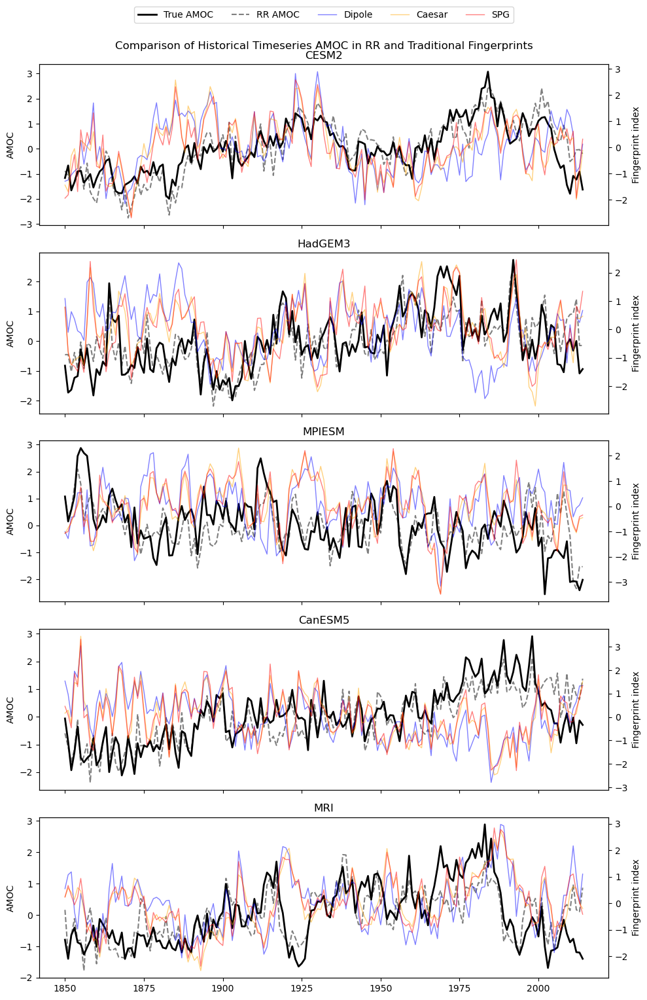

In [67]:
n_models = len(all_models)

fig, axes = plt.subplots(
    n_models, 1,
    figsize=(10, 3*n_models),
    sharex=True
)

fig.suptitle("Comparison of Historical Timeseries AMOC in RR and Traditional Fingerprints")
plt.tight_layout(rect=[0,0,1,0.97])

for i, model in enumerate(all_models):

    ax = axes[i]
    ax2 = ax.twinx()
    years=processed_fingerprints_hist["dipole"]["CESM2"][1]["year"]

    true_moc = MOC_hist_model_results[1][model]["True_Values"]
    RR_moc   = MOC_hist_model_results[1][model]["Historical_Predictions"]

    dipole = processed_fingerprints_hist["dipole"][model][1]["normalized_tos_1yr"]
    caesar = processed_fingerprints_hist["caesar"][model][1]["normalized_tos_1yr"]
    spg    = processed_fingerprints_hist["spg"][model][1]["normalized_tos_1yr"]

    l1 = ax.plot(years,true_moc, label="True AMOC", color="black", linewidth=2, alpha=1)
    l2 = ax.plot(years,RR_moc, label="RR AMOC", color="black", linestyle="--", alpha=0.5)

    l3 = ax2.plot(years,dipole, label="Dipole", color="blue", linewidth=1, alpha=0.5)
    l4 = ax2.plot(years,caesar, label="Caesar", color="orange",linewidth=1, alpha=0.5)
    l5 = ax2.plot(years,spg, label="SPG",color="red", linewidth=1, alpha=0.5)

    ax.set_title(model)
    ax.set_ylabel("AMOC")
    ax2.set_ylabel("Fingerprint index")

    lines = l1 + l2 + l3 + l4 + l5
    # store legend items only once
    if i == 0:
        legend_lines = l1 + l2 + l3 + l4 + l5
        legend_labels = [l.get_label() for l in legend_lines]

fig.legend(
    legend_lines,
    legend_labels,
    loc="upper center",
    ncol=5,
    bbox_to_anchor=(0.5, 1.02)
)

plt.tight_layout()
#plt.show()

In [68]:
dipole_HadISST=xr.open_dataset(r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Output_HadISST_Dipole.nc")
caesar_HadISST=xr.open_dataset(r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Output_HadISST_Caesar.nc")
spg_HadISST=xr.open_dataset(r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Output_HadISST_SPG.nc")
# Already annual


In [69]:
dipole_HadISST_annual=dipole_HadISST["sst"].resample(time="1Y").mean(dim="time")
caesar_HadISST_annual=caesar_HadISST["sst"].resample(time="1Y").mean(dim="time")
spg_HadISST_annual=spg_HadISST["sst"].resample(time="1Y").mean(dim="time")

/home/baharem/.conda/envs/baharenv/lib/python3.12/site-packages/xarray/core/groupby.py:508: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  index_grouper = pd.Grouper(
/home/baharem/.conda/envs/baharenv/lib/python3.12/site-packages/xarray/core/groupby.py:508: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  index_grouper = pd.Grouper(
/home/baharem/.conda/envs/baharenv/lib/python3.12/site-packages/xarray/core/groupby.py:508: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  index_grouper = pd.Grouper(


In [70]:
# def turn_to_df(ds):

#     ds_1yr = ds.copy()
#     ds_1yr=(ds_1yr-ds_1yr.mean())/ds_1yr.std()

#     ds_5yr = ds.copy()
#     ds_5yr = ds.rolling(time=5, center=True).mean()
#     ds_5yr=(ds_5yr-ds_5yr.mean())/ds_5yr.std()
    
#     ds_10yr = ds.copy()
#     ds_10yr = ds.rolling(time=10, center=True).mean()
#     ds_10yr=(ds_10yr-ds_10yr.mean())/ds_10yr.std()
    
    
#     ds_15yr = ds.copy()
#     ds_15yr = ds.rolling(time=15, center=True).mean()
#     ds_15yr=(ds_15yr-ds_15yr.mean())/ds_15yr.std()
    
#     ds_20yr = ds.copy()
#     ds_20yr = ds.rolling(time=20, center=True).mean()
#     ds_20yr=(ds_20yr-ds_20yr.mean())/ds_20yr.std()

#     ds_30yr = ds.copy()
#     ds_30yr = ds.rolling(time=30, center=True).mean()
#     ds_30yr=(ds_30yr-ds_30yr.mean())/ds_30yr.std()

#     def ds_to_df(ds_in):
#         df = ds_in.to_dataframe().reset_index()

#         df["year"] = df["time"].dt.year

#         df = df.drop_duplicates()

#         return df

#     df_1yr = ds_to_df(ds_1yr)
#     df_5yr = ds_to_df(ds_5yr)
#     df_10yr = ds_to_df(ds_10yr)
#     df_15yr = ds_to_df(ds_15yr)
#     df_20yr = ds_to_df(ds_20yr)
#     df_30yr = ds_to_df(ds_30yr)

#     return df_1yr, df_5yr,df_10yr,df_15yr,df_20yr, df_30yr

In [71]:
def turn_to_df(ds):
    windows = [1, 5, 10, 15, 20, 30]
    
    def ds_to_df(ds_in):
        df = ds_in.to_dataframe().reset_index()
        df["year"] = df["time"].dt.year
        df = df.drop_duplicates().set_index("year") 
        return df

    result = {}
    for w in windows:
        ds_w = ds.copy()
        if w > 1:
            ds_w = ds_w.rolling(time=w, center=True).mean()
        ds_w = (ds_w - ds_w.mean()) / ds_w.std()
        result[w] = ds_to_df(ds_w)
        

    return result

In [72]:
HadISST_caesar = turn_to_df(caesar_HadISST_annual)
HadISST_dipole = turn_to_df(dipole_HadISST_annual)
HadISST_spg    = turn_to_df(spg_HadISST_annual)

In [73]:
# columns_to_drop=["lat", "lon", "time"]

# HadISST_caesar_df_1yr, HadISST_caesar_df_5yr,HadISST_caesar_df_10yr, HadISST_caesar_df_15yr,HadISST_caesar_df_20yr,HadISST_caesar_df_30yr = turn_to_df(caesar_HadISST_annual)
# HadISST_spg_df_1yr, HadISST_spg_df_5yr,HadISST_spg_df_10yr,HadISST_spg_df_15yr,HadISST_spg_df_20yr, HadISST_spg_df_30yr = turn_to_df(spg_HadISST_annual)
# HadISST_dipole_df_1yr, HadISST_dipole_df_5yr,HadISST_dipole_df_10yr,HadISST_dipole_df_15yr,HadISST_dipole_df_20yr, HadISST_dipole_df_30yr = turn_to_df(dipole_HadISST_annual)

### HadISST based traditional fingerprints are computed on raw HadISST data - NaNs removed 
(not detrended)

In [74]:
HadISST_SST_yearly=HadISST_SST.resample(time="1YE").mean()
#HadISST_SST_yearly_normalised = (HadISST_SST_yearly - HadISST_SST_yearly.mean()) / HadISST_SST_yearly.std()


HadISST_df=HadISST_SST_yearly.to_dataframe().reset_index()


In [75]:
sst=HadISST_SST_yearly["sst"]


weights = np.cos(np.deg2rad(sst.latitude))

global_mean = (
    sst
    .weighted(weights)
    .mean(dim=("latitude", "longitude"))
)

cov = xr.cov(sst, global_mean, dim="time")
var = global_mean.var(dim="time")

beta = cov / var
sst_detrended = sst - beta * global_mean




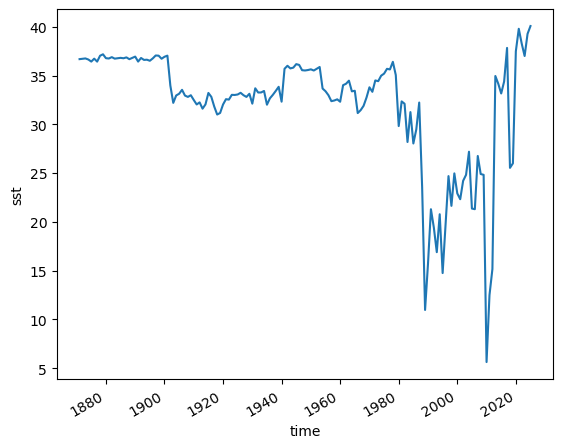

In [76]:
trend=(beta * global_mean)
trend.mean(dim="latitude").mean(dim="longitude").plot()

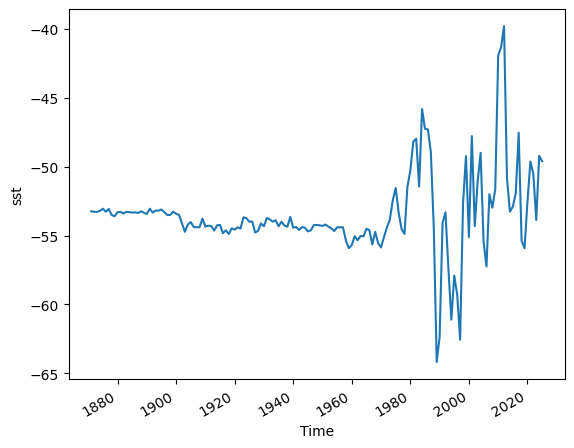

In [77]:
sst_detrended.mean(dim="latitude").mean(dim="longitude").plot()

In [78]:
HadISST_df = HadISST_df[["time", "latitude", "longitude", "sst"]].copy()
HadISST_df = HadISST_df.drop_duplicates(
    subset=["time", "latitude", "longitude"]
)
HadISST_df["gridpoint"] = (
    "SST_"
    + HadISST_df["latitude"].astype(str)
    + "_"
    + HadISST_df["longitude"].astype(str)
)
HadISST_df_clean = HadISST_df.pivot(
    index="time",
    columns="gridpoint",
    values="sst"
)

In [79]:
HadISST_df_detrended = (
    sst_detrended
    .to_dataframe(name="sst")
    .reset_index()
)
HadISST_df_detrended = HadISST_df_detrended.drop_duplicates(
    subset=["time", "latitude", "longitude"]
)
HadISST_df_detrended["gridpoint"] = (
    "SST_"
    + HadISST_df_detrended["latitude"].astype(str)
    + "_"
    + HadISST_df_detrended["longitude"].astype(str)
)
HadISST_df_clean_detrended = HadISST_df_detrended.pivot(
    index="time",
    columns="gridpoint",
    values="sst"
)

In [80]:
# Columns must be aligned with models for RR 

common_columns =processed_features_dict["tos"]["pi"][1]["CESM2"].columns.intersection(HadISST_df_clean.columns)

HadISST_df_clean=HadISST_df_clean[common_columns]


In [81]:
HadISST_clean=HadISST_df_clean.dropna(axis=1)

In [82]:
HadISST_dict = {}

# 1-year
HadISST_dict[1] = normalise(
    HadISST_clean.copy()
)

# 5-year
HadISST_dict[5] = normalise(
    HadISST_clean
    .rolling(window=5, center=True)
    .mean()
    .dropna()
)


HadISST_dict[10] = normalise(
    HadISST_clean
    .rolling(window=10, center=True)
    .mean()
    .dropna()
)


HadISST_dict[15] = normalise(
    HadISST_clean
    .rolling(window=15, center=True)
    .mean()
    .dropna()
)


HadISST_dict[20] = normalise(
    HadISST_clean
    .rolling(window=20, center=True)
    .mean()
    .dropna()
)

# 30-year
HadISST_dict[30] = normalise(
    HadISST_clean
    .rolling(window=30, center=True)
    .mean()
    .dropna()
)

## HadISST Plot

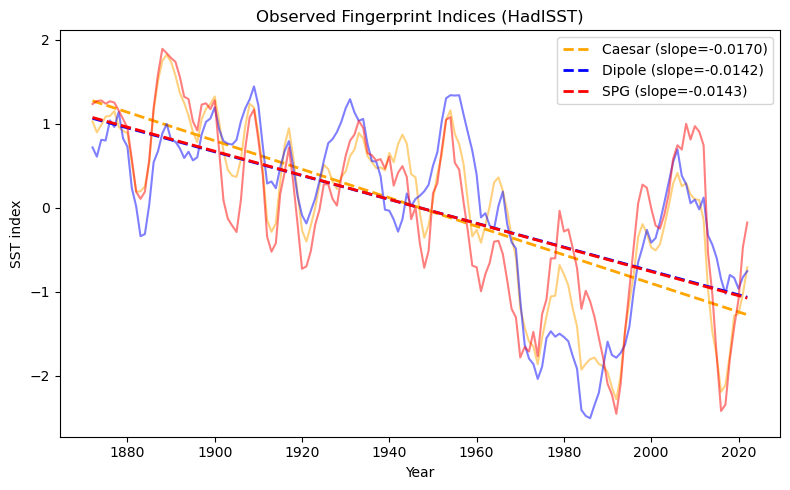

In [83]:
# Creating a plot of HadISST timeseries

caesar_obs =HadISST_caesar[5]["sst"].dropna()
dipole_obs = HadISST_dipole[5]["sst"].dropna()
spg_obs    = HadISST_spg[5]["sst"].dropna()
year       = HadISST_caesar[5].dropna().index




plt.figure(figsize=(8, 5))

for obs, label, color in [
    (caesar_obs, "Caesar", "orange"),
    (dipole_obs, "Dipole", "blue"),
    (spg_obs,    "SPG",    "red"),
]:
    coeffs     = np.polyfit(year, obs, 1)
    slope      = coeffs[0]
    trend_line = np.polyval(coeffs, year)

    plt.plot(year, obs,        color=color, alpha=0.5)
    plt.plot(year, trend_line, color=color, linewidth=2, linestyle="--",
             label=f"{label} (slope={slope:.4f})")

plt.xlabel("Year")
plt.ylabel("SST index")
plt.title("Observed Fingerprint Indices (HadISST)")
plt.legend()
plt.tight_layout()
plt.show()


## Fit HadISST into each ESM's RR for AMOC and the SPG, predict the AMOC and the SPG and then produce the lambda calculation

In [84]:
alpha = 1000

windows = [1,5,15,20,30]

MOC_HadISST_ridge_models = {}
MOC_HadISST_model_results = {}
MOC_HadISST_model_coefs = {}

for model in all_models:

    print(f"Processing model: {model}")

    MOC_HadISST_ridge_models[model] = {}
    MOC_HadISST_model_results[model] = {}
    MOC_HadISST_model_coefs[model] = {}

    for window in windows:

        # ------------------
        # Load features
        # ------------------
        X = processed_features_dict["tos"]["pi"][window][model].reset_index(drop=True)
        

        train_cols = set(X.columns)
        obs_cols = set(HadISST_dict[window].columns)

        common_cols = sorted(
            train_cols.intersection(obs_cols)
        )

        X_aligned = X[common_cols]
        HadISST_aligned = HadISST_dict[window][common_cols]

        y = processed_targets_dict["moc"]["pi"][window][model].squeeze()

        # ------------------
        # Train/test split
        # ------------------
        X_train, X_test, y_train, y_test = train_test_split(
            X_aligned,
            y,
            test_size=0.2,
            shuffle=False,
        )

        # ------------------
        # Fit Ridge
        # ------------------
        ridge = Ridge(alpha=alpha)

        ridge.fit(X_train, y_train)

        preds = ridge.predict(X_test)

        preds_HadISST = ridge.predict(
            HadISST_aligned.dropna()
        )

        mse = mean_squared_error(y_test, preds)

        corr, _ = pearsonr(y_test, preds)

        # ------------------
        # Store by window
        # ------------------
        MOC_HadISST_ridge_models[model][window] = ridge

        MOC_HadISST_model_results[model][window] = pd.DataFrame({
            "Correlation": [corr],
            "MSE": [mse],
            "Test_Predictions": [preds],
            "HadISST_Predictions": [preds_HadISST],
        })

        MOC_HadISST_model_coefs[model][window] = pd.DataFrame(
            ridge.coef_.reshape(1, -1),
            columns=X_aligned.columns,
            index=[alpha],
        )

Processing model: CESM2
Processing model: HadGEM3
Processing model: MPIESM
Processing model: CanESM5


Processing model: MRI


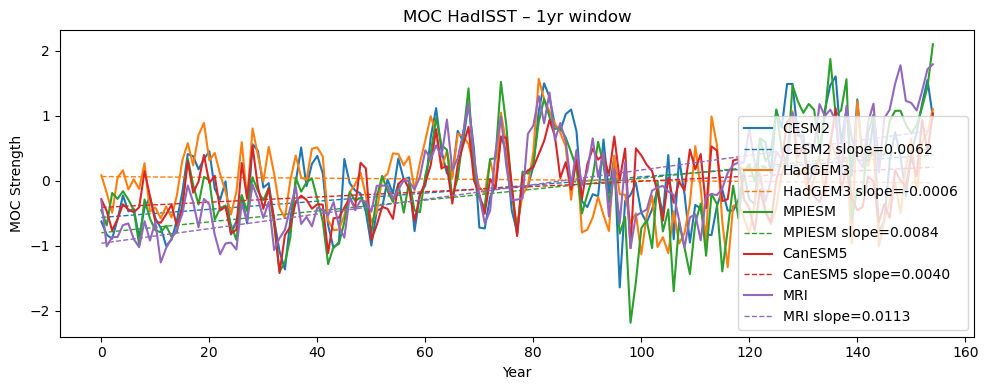

In [85]:
fig, ax = plt.subplots(figsize=(10, 4))

for model in all_models:
    preds = pd.Series(
        np.squeeze(MOC_HadISST_model_results[model][1]["HadISST_Predictions"])
    ).dropna()

    # Plot the time series
    line, = ax.plot(preds.index, preds.values, label=model)

    # Compute Theil-Sen slope via Mann-Kendall
    mk_result = mk.hamed_rao_modification_test(preds.values)
    slope = mk_result.slope
    intercept = np.median(preds.values) - slope * np.median(preds.index)  # Theil-Sen intercept

    trend_line = slope * preds.index + intercept

    # Plot slope in same colour, dashed
    ax.plot(preds.index, trend_line, color=line.get_color(),
            linestyle="--", linewidth=1,
            label=f"{model} slope={slope:.4f} ")

ax.set_xlabel("Year")
ax.set_ylabel("MOC Strength")
ax.set_title("MOC HadISST – 1yr window")
ax.legend()
plt.tight_layout()
plt.show()

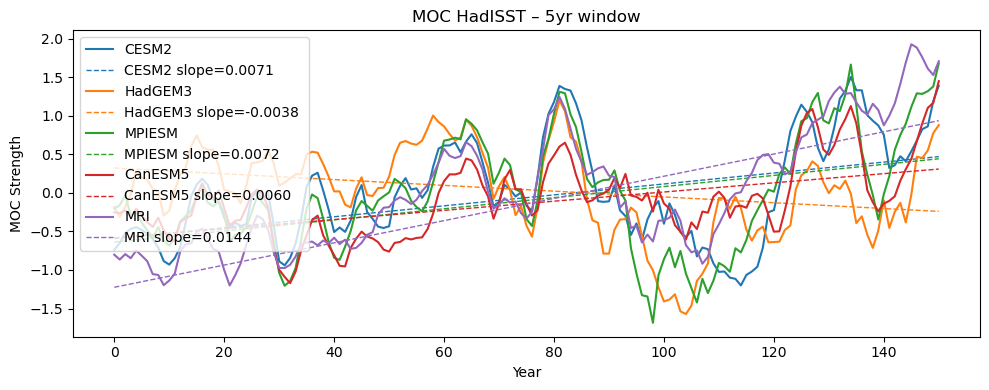

In [86]:
fig, ax = plt.subplots(figsize=(10, 4))

for model in all_models:
    preds = pd.Series(
        np.squeeze(MOC_HadISST_model_results[model][5]["HadISST_Predictions"])
    ).dropna()

    # Plot the time series
    line, = ax.plot(preds.index, preds.values, label=model)

    # Compute Theil-Sen slope via Mann-Kendall
    mk_result = mk.hamed_rao_modification_test(preds.values)
    slope = mk_result.slope
    intercept = np.median(preds.values) - slope * np.median(preds.index)  # Theil-Sen intercept

    trend_line = slope * preds.index + intercept

    # Plot slope in same colour, dashed
    ax.plot(preds.index, trend_line, color=line.get_color(),
            linestyle="--", linewidth=1,
            label=f"{model} slope={slope:.4f} ")

ax.set_xlabel("Year")
ax.set_ylabel("MOC Strength")
ax.set_title("MOC HadISST – 5yr window")
ax.legend()
plt.tight_layout()
plt.show()

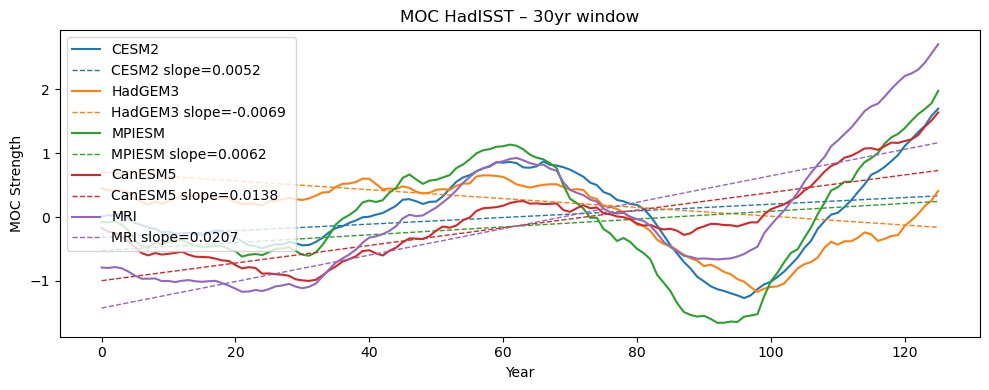

In [87]:
fig, ax = plt.subplots(figsize=(10, 4))

for model in all_models:
    preds = pd.Series(
        np.squeeze(MOC_HadISST_model_results[model][30]["HadISST_Predictions"])
    ).dropna()

    # Plot the time series
    line, = ax.plot(preds.index, preds.values, label=model)

    # Compute Theil-Sen slope via Mann-Kendall
    mk_result = mk.hamed_rao_modification_test(preds.values)
    slope = mk_result.slope
    intercept = np.median(preds.values) - slope * np.median(preds.index)  # Theil-Sen intercept

    trend_line = slope * preds.index + intercept

    # Plot slope in same colour, dashed
    ax.plot(preds.index, trend_line, color=line.get_color(),
            linestyle="--", linewidth=1,
            label=f"{model} slope={slope:.4f} ")

ax.set_xlabel("Year")
ax.set_ylabel("MOC Strength")
ax.set_title("MOC HadISST – 30yr window")
ax.legend()
plt.tight_layout()
plt.show()

In [88]:
alpha = 1000

windows = [1,5,15,20,30]

SPG_HadISST_ridge_models = {}
SPG_HadISST_model_results = {}
SPG_HadISST_model_coefs = {}

for model in all_models:

    print(f"Processing model: {model}")

    SPG_HadISST_ridge_models[model] = {}
    SPG_HadISST_model_results[model] = {}
    SPG_HadISST_model_coefs[model] = {}

    for window in windows:

        # ------------------
        # Load features
        # ------------------
        X = processed_features_dict["tos"]["pi"][window][model].reset_index(drop=True)
        

        train_cols = set(X.columns)
        obs_cols = set(HadISST_dict[window].columns)

        common_cols = sorted(
            train_cols.intersection(obs_cols)
        )

        X_aligned = X[common_cols]
        HadISST_aligned = HadISST_dict[window][common_cols]

        y = processed_targets_dict["msftbarot"]["pi"][window][model].squeeze()

        # ------------------
        # Train/test split
        # ------------------
        X_train, X_test, y_train, y_test = train_test_split(
            X_aligned,
            y,
            test_size=0.2,
            shuffle=False,
        )

        # ------------------
        # Fit Ridge
        # ------------------
        ridge = Ridge(alpha=alpha)

        ridge.fit(X_train, y_train)

        preds = ridge.predict(X_test)

        preds_HadISST = ridge.predict(
            HadISST_aligned.dropna()
        )

        mse = mean_squared_error(y_test, preds)

        corr, _ = pearsonr(y_test, preds)

        # ------------------
        # Store by window
        # ------------------
        SPG_HadISST_ridge_models[model][window] = ridge

        SPG_HadISST_model_results[model][window] = pd.DataFrame({
            "Correlation": [corr],
            "MSE": [mse],
            "Test_Predictions": [preds],
            "HadISST_Predictions": [preds_HadISST],
        })

        SPG_HadISST_model_coefs[model][window] = pd.DataFrame(
            ridge.coef_.reshape(1, -1),
            columns=X_aligned.columns,
            index=[alpha],
        )

Processing model: CESM2


Processing model: HadGEM3
Processing model: MPIESM
Processing model: CanESM5
Processing model: MRI


In [89]:
# alpha = 1000

# windows = ["_1yr", "_5yr", "_30yr"]

# SPG_HadISST_ridge_models = {}
# SPG_HadISST_model_results = {}
# SPG_HadISST_model_coefs = {}

# for model in all_models:

#     print(f"Processing model: {model}")

#     SPG_HadISST_ridge_models[model] = {}
#     SPG_HadISST_model_results[model] = {}
#     SPG_HadISST_model_coefs[model] = {}

#     for window in windows:

#         # ------------------
#         # Load features
#         # ------------------
#         X = (
#             normalise(processed_data_tos[model]["piControl"][window]
#             .reset_index(drop=True))
#         )

#         train_cols = set(X.columns)
#         obs_cols = set(HadISST_dict[window].columns)

#         common_cols = sorted(
#             train_cols.intersection(obs_cols)
#         )

#         X_aligned = X[common_cols]
#         HadISST_aligned = HadISST_dict[window][common_cols]

#         y = processed_targets_pi[window][model]["msftbarot"]

#         # ------------------
#         # Align NaNs
#         # ------------------
#         valid = (
#             X_aligned.notna().all(axis=1)
#             & y.notna()
#         )

#         X_aligned = X_aligned.loc[valid]
#         y = y.loc[valid]

#         # ------------------
#         # Train/test split
#         # ------------------
#         X_train, X_test, y_train, y_test = train_test_split(
#             X_aligned,
#             y,
#             test_size=0.2,
#             shuffle=False,
#         )

#         # ------------------
#         # Fit Ridge
#         # ------------------
#         ridge = Ridge(alpha=alpha)

#         ridge.fit(X_train, y_train)

#         preds = ridge.predict(X_test)

#         preds_HadISST = ridge.predict(
#             HadISST_aligned.dropna()
#         )

#         mse = mean_squared_error(y_test, preds)

#         corr, _ = pearsonr(y_test, preds)

#         # ------------------
#         # Store by window
#         # ------------------
#         SPG_HadISST_ridge_models[model][window] = ridge

#         SPG_HadISST_model_results[model][window] = pd.DataFrame({
#             "Correlation": [corr],
#             "MSE": [mse],
#             "Test_Predictions": [preds],
#             "HadISST_Predictions": [preds_HadISST],
#         })

#         SPG_HadISST_model_coefs[model][window] = pd.DataFrame(
#             ridge.coef_.reshape(1, -1),
#             columns=X_aligned.columns,
#             index=[alpha],
#         )

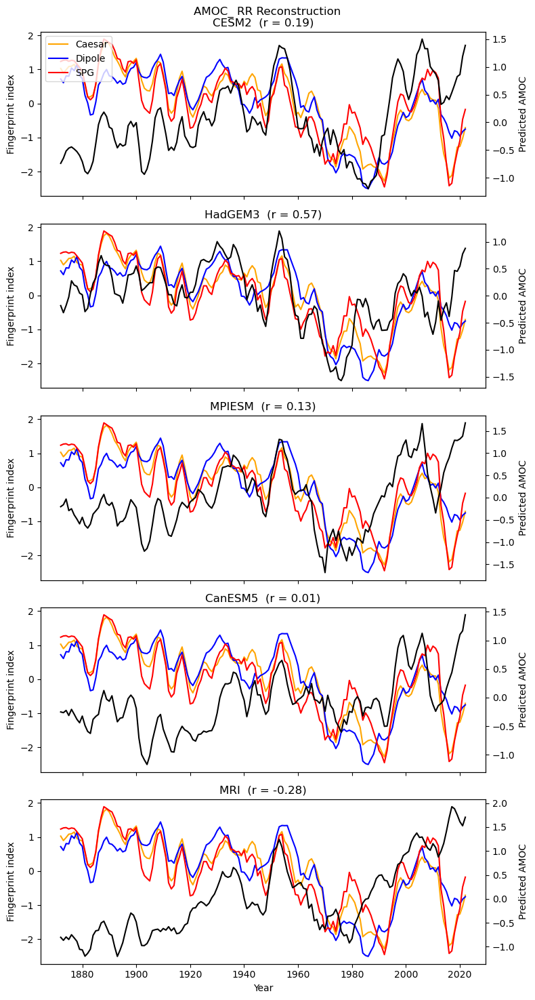

In [90]:
caesar_obs = HadISST_caesar[5]["sst"].dropna()
dipole_obs = HadISST_dipole[5]["sst"].dropna()
spg_obs    = HadISST_spg[5]["sst"].dropna()
year       = HadISST_caesar[5].dropna().index

n_models = len(all_models)

fig, axes = plt.subplots(n_models, 1, figsize=(8, 3*n_models), sharex=True)
plt.suptitle("AMOC_ RR Reconstruction")
for i, model in enumerate(all_models):

    ax = axes[i]

    # fingerprints
    ax.plot(year, caesar_obs, color="orange", label="Caesar")
    ax.plot(year, dipole_obs, color="blue", label="Dipole")
    ax.plot(year, spg_obs, color="red", label="SPG")
    ax.set_ylabel("Fingerprint index")

    # ridge prediction
    preds = np.squeeze(MOC_HadISST_model_results[model][5]["HadISST_Predictions"])
    ax2 = ax.twinx()
    ax2.plot(year, preds, color="black", label="Ridge prediction")
    ax2.set_ylabel("Predicted AMOC")

    # correlation with SPG fingerprint
    r = np.corrcoef(preds, spg_obs)[0,1]

    ax.set_title(f"{model}  (r = {r:.2f})")

axes[-1].set_xlabel("Year")

# legend
axes[0].legend(loc="upper left")

plt.tight_layout()
plt.show()

# Restoring rate Calculations

In [91]:
import statsmodels.api as sm
# Not this 
def restoring_rate(series, w):
    x = series.values
    n = len(x)
    xs = np.full(n, np.nan)

    for i in range(w//2, n-w//2):

        # window
        xw = x[i-w//2:i+w//2+1]

        # remove mean
        xw = xw - np.mean(xw)

        # remove linear tren
        p0, p1 = np.polyfit(np.arange(len(xw)), xw, 1)
        xw = xw - (p0*np.arange(len(xw)) + p1)

        # increments
        dxw = xw[1:] - xw[:-1]

        # regression
        X = sm.add_constant(xw[:-1])
        model = sm.GLSAR(dxw, X, rho=1)
        results = model.iterative_fit(maxiter=10)

        xs[i + w//2] = results.params[1]
        

    return xs

In [92]:
# import statsmodels.api as sm
# # Changing from centered to trailing as seen above 
# def restoring_rate(series, w):
#     x = series.values
#     n = len(x)
#     xs = np.full(n, np.nan)

#     for i in range(w//2, n-w//2):

#         # window
#         xw = x[i-w//2:i+w//2+1]

#         # remove mean
#         xw = xw - np.mean(xw)

#         # remove linear tren
#         p0, p1 = np.polyfit(np.arange(len(xw)), xw, 1)
#         xw = xw - (p0*np.arange(len(xw)) + p1)

#         # increments
#         dxw = xw[1:] - xw[:-1]

#         # regression
#         X = sm.add_constant(xw[:-1])
#         model = sm.GLSAR(dxw, X, rho=1)
#         results = model.iterative_fit(maxiter=10)

#         xs[i] = results.params[1]
        

#     return xs


In [100]:
def detrend_running_mean(ts, window=50):

    trend = ts.rolling(
        window,
        center=True,
        min_periods=1
    ).mean()
# Set center to True 
# Check how many NaNs and why 
# what is min_periods
    detrended = ts - trend

    return detrended, trend

In [101]:
z=HadISST_dipole[5]["sst"]

In [102]:
z

year
1870         NaN
1871         NaN
1872    0.718449
1873    0.608551
1874    0.809288
          ...   
2020   -0.963047
2021   -0.824834
2022   -0.753810
2023         NaN
2024         NaN
Name: sst, Length: 155, dtype: float64

In [103]:
x, trend=detrend_running_mean(z)
x

year
1870         NaN
1871         NaN
1872    0.114662
1873   -0.005559
1874    0.180042
          ...   
2020   -0.619539
2021   -0.520913
2022   -0.476112
2023         NaN
2024         NaN
Name: sst, Length: 155, dtype: float64

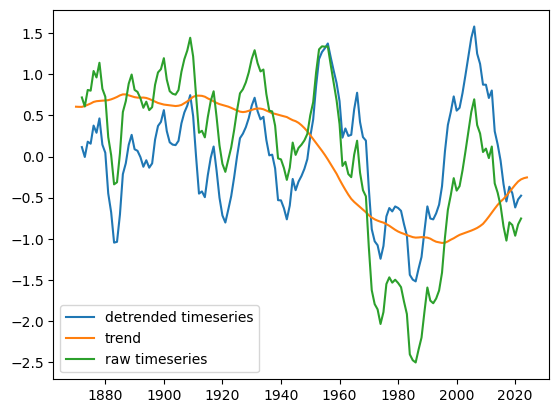

In [104]:
z=HadISST_dipole[5]["sst"]

y=trend
time=z.index
plt.plot(time, x, label="detrended timeseries")
plt.plot(time, y, label="trend")
plt.plot(z.index, z, label="raw timeseries")
plt.legend()

looking into detrending

In [105]:
# from statsmodels.nonparametric.smoothers_lowess import lowess
# def detrend_lowess(ts):
#     trend = lowess(ts.values, np.arange(len(ts)), frac=0.7, return_sorted=False)
#     detrended = ts.values - trend
    
#     trend = pd.Series(trend, index=ts.index, name=ts.name)
#     detrended = pd.Series(detrended, index=ts.index, name=ts.name)
#     return detrended, trend 

stops looking into detrending

In [106]:
HadISST_trad_fingerprints = {
    w: {
        "dipole": HadISST_dipole[w],
        "caesar": HadISST_caesar[w],
        "spg":    HadISST_spg[w],
    }
    for w in [1, 5, 10, 15, 20, 30]
}


In [107]:
detrended_trad_fingerprints = {}
trends_trad_fingerprints = {}
lambdas_trad_fingerprints = {}
slopes_trad_fingerprints = {}  

for window, regions in HadISST_trad_fingerprints.items():

    detrended_trad_fingerprints[window] = {}
    trends_trad_fingerprints[window] = {}
    lambdas_trad_fingerprints[window] = {}
    slopes_trad_fingerprints[window] = {}  


    for region, df in regions.items():
        # Compute the slopes of the non-detrended (raw) SST values
        sst_vals = df["sst"].dropna()
        x = np.arange(0,len(sst_vals.index.values),1)
        res = stats.linregress(x, sst_vals)
        slopes_trad_fingerprints[window][region] = res.slope


        detrended_trad_fingerprints[window][region], \
        trends_trad_fingerprints[window][region] = (
            detrend_running_mean(df["sst"])
        )
        detrended = detrended_trad_fingerprints[window][region].dropna()

        lam = restoring_rate(
            detrended,
            w=70
        )

        lambdas_trad_fingerprints[window][region] = pd.Series(
            lam,
            index=detrended.index
        )


In [108]:
# HadISST_trad_fingerprints = {
#     "_1yr": {
#         "dipole": HadISST_dipole_df_1yr.set_index("year"),
#         "caesar": HadISST_caesar_df_1yr.set_index("year"),
#         "spg": HadISST_spg_df_1yr.set_index("year"),
#     },
#     "_5yr": {
#         "dipole": HadISST_dipole_df_5yr.set_index("year"),
#         "caesar": HadISST_caesar_df_5yr.set_index("year"),
#         "spg": HadISST_spg_df_5yr.set_index("year"),
#     },
#     "_30yr": {
#         "dipole": HadISST_dipole_df_30yr.set_index("year"),
#         "caesar": HadISST_caesar_df_30yr.set_index("year"),
#         "spg": HadISST_spg_df_30yr.set_index("year"),
#     }
# }

# detrended_trad_fingerprints = {}
# trends_trad_fingerprints = {}
# lambdas_trad_fingerprints = {}
# slopes_trad_fingerprints = {}  # initialise alongside the others


# for smoothing, regions in HadISST_trad_fingerprints.items():

#     detrended_trad_fingerprints[smoothing] = {}
#     trends_trad_fingerprints[smoothing] = {}
#     lambdas_trad_fingerprints[smoothing] = {}
#     slopes_trad_fingerprints[smoothing] = {}  # initialise inner dict


#     for region, df in regions.items():
#         # Compute the slopes of the non-detrended (raw) SST values
#         sst_vals = df["sst"].dropna()
#         x = sst_vals.index.values
#         res = stats.linregress(x, sst_vals)
#         slopes_trad_fingerprints[smoothing][region] = res.slope


#         detrended_trad_fingerprints[smoothing][region], \
#         trends_trad_fingerprints[smoothing][region] = (
#             detrend_running_mean(df["sst"])
#         )
#         detrended = detrended_trad_fingerprints[smoothing][region].dropna()

#         lam = restoring_rate(
#             detrended,
#             w=70
#         )

#         lambdas_trad_fingerprints[smoothing][region] = pd.Series(
#             lam,
#             index=detrended.index
#         )


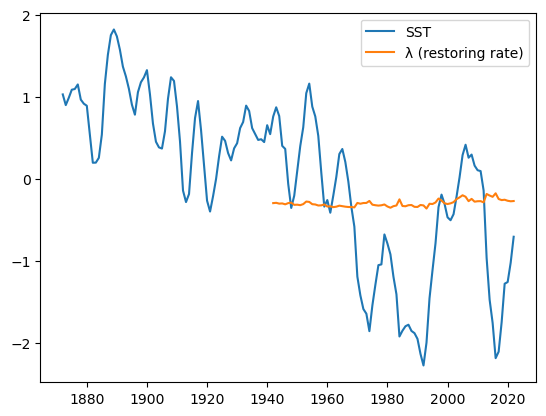

In [109]:
year = HadISST_caesar[5].index
caesar = HadISST_caesar[5]["sst"]
caesar_lambda = lambdas_trad_fingerprints[5]["caesar"]  # year as index

fig, ax = plt.subplots()
ax.plot(year, caesar, label="SST")
ax.plot(caesar_lambda.index, caesar_lambda, label="λ (restoring rate)")
ax.legend()
plt.show()

In [110]:
detrended_RR_MOC = {}
trends_RR_MOC = {}
lambdas_RR_MOC = {}
slopes_RR_MOC = {}  # initialise alongside the others
#pvals_RR_MOC={}

for model in all_models:
    detrended_RR_MOC[model] = {}
    trends_RR_MOC[model] = {}
    lambdas_RR_MOC[model] = {}
    slopes_RR_MOC[model] = {}
    for window in windows:
        years = lambdas_trad_fingerprints[window]["caesar"].index
        preds = pd.Series(
            np.squeeze(
                MOC_HadISST_model_results[model][window]["HadISST_Predictions"]
            ),
            index=years
        )
        detrended_RR_MOC[model][window], trends_RR_MOC[model][window] = (
            detrend_running_mean(preds)
        )

        preds_clean = preds.dropna()

        x = np.arange(len(preds_clean))
        res = stats.linregress(x, preds_clean.values)
        slopes_RR_MOC[model][window] = res.slope

        lambdas_RR_MOC[model][window] = pd.Series(
            restoring_rate(
                detrended_RR_MOC[model][window].dropna(),
                w=70
            ),
            index=detrended_RR_MOC[model][window].dropna().index
        )

In [111]:
detrended_RR_SPG = {}
trends_RR_SPG = {}
lambdas_RR_SPG = {}
slopes_RR_SPG = {}  # initialise alongside the others
#pvals_RR_MOC={}

for model in all_models:
    detrended_RR_SPG[model] = {}
    trends_RR_SPG[model] = {}
    lambdas_RR_SPG[model] = {}
    slopes_RR_SPG[model] = {}
    for window in windows:
        years = lambdas_trad_fingerprints[window]["caesar"].index
        preds = pd.Series(
            np.squeeze(
                SPG_HadISST_model_results[model][window]["HadISST_Predictions"]
            ),
            index=years
        )
        detrended_RR_SPG[model][window], trends_RR_SPG[model][window] = (
            detrend_running_mean(preds)
        )

        preds_clean = preds.dropna()

        x = np.arange(len(preds_clean))
        res = stats.linregress(x, preds_clean.values)
        slopes_RR_SPG[model][window] = res.slope

        lambdas_RR_SPG[model][window] = pd.Series(
            restoring_rate(
                detrended_RR_SPG[model][window].dropna(),
                w=70
            ),
            index=detrended_RR_SPG[model][window].dropna().index
        )

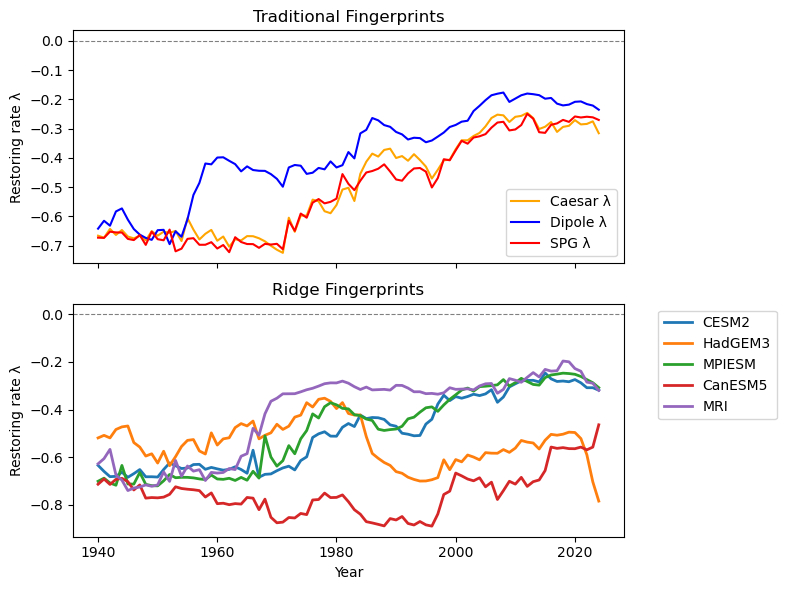

In [112]:
fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
year=lambdas_trad_fingerprints[1]["caesar"].index
# --- Top Panel: Traditional Fingerprints ---
axes[0].plot(year, lambdas_trad_fingerprints[1]["caesar"], color="orange", label="Caesar λ")
axes[0].plot(year, lambdas_trad_fingerprints[1]["dipole"], color="blue", label="Dipole λ")
axes[0].plot(year, lambdas_trad_fingerprints[1]["spg"], color="red", label="SPG λ")

axes[0].axhline(0, color="gray", linestyle="--", linewidth=0.8)
axes[0].set_title("Traditional Fingerprints")
axes[0].set_ylabel("Restoring rate λ")
axes[0].legend()

# --- Bottom Panel: Ridge Fingerprints ---
for model in all_models:
    # Plotted with default colors so they are distinct
    axes[1].plot(year, lambdas_RR_MOC[model][1], linewidth=2, label=model)

axes[1].axhline(0, color="gray", linestyle="--", linewidth=0.8)
axes[1].set_title("Ridge Fingerprints")
axes[1].set_ylabel("Restoring rate λ")
axes[1].set_xlabel("Year")

# Place legend outside the plot area if you have many models
axes[1].legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

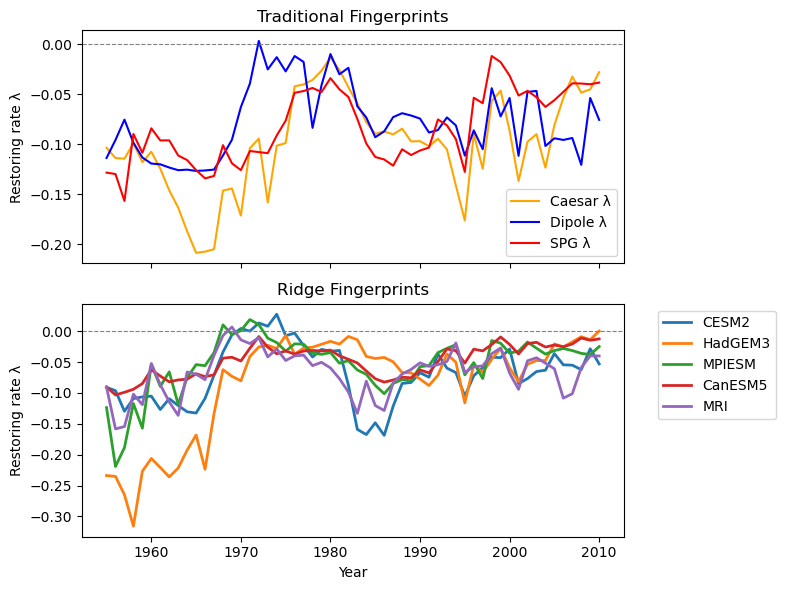

In [113]:
fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
year=lambdas_trad_fingerprints[30]["caesar"].index
# --- Top Panel: Traditional Fingerprints ---
axes[0].plot(year, lambdas_trad_fingerprints[30]["caesar"], color="orange", label="Caesar λ")
axes[0].plot(year, lambdas_trad_fingerprints[30]["dipole"], color="blue", label="Dipole λ")
axes[0].plot(year, lambdas_trad_fingerprints[30]["spg"], color="red", label="SPG λ")

axes[0].axhline(0, color="gray", linestyle="--", linewidth=0.8)
axes[0].set_title("Traditional Fingerprints")
axes[0].set_ylabel("Restoring rate λ")
axes[0].legend()

# --- Bottom Panel: Ridge Fingerprints ---
for model in all_models:
    # Plotted with default colors so they are distinct
    axes[1].plot(year, lambdas_RR_MOC[model][30], linewidth=2, label=model)

axes[1].axhline(0, color="gray", linestyle="--", linewidth=0.8)
axes[1].set_title("Ridge Fingerprints")
axes[1].set_ylabel("Restoring rate λ")
axes[1].set_xlabel("Year")

# Place legend outside the plot area if you have many models
axes[1].legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()
# for 

# Significance Testing

In [114]:
# Fourier surrogates for significance testing of the restoring rate 

def runmean(x, w):
    ## running mean of timeseries x with window size w
    n = x.shape[0]
    xs = np.zeros_like(x)
    for i in range(w // 2):
        xs[i] = np.nanmean(x[: i + w // 2 + 1])
    for i in range(n - w // 2, n):
        xs[i] = np.nanmean(x[i - w // 2 + 1:])

    for i in range(w // 2, n - w // 2):
        xs[i] = np.nanmean(x[i - w // 2 : i + w // 2 + 1])
    return xs

def fourrier_surrogates(ts, ns):
    ## generate ns fourier surrogates from timeseries ts
    ts_fourier  = np.fft.rfft(ts)
    random_phases = np.exp(np.random.uniform(0, 2 * np.pi, (ns, ts.shape[0] // 2 + 1)) * 1.0j)
    ts_fourier_new = ts_fourier * random_phases
    new_ts = np.real(np.fft.irfft(ts_fourier_new, n=len(ts)))
    return new_ts

def fourier_wrapper(ts,nsmp):
    ts = ts - runmean(ts,w=50)
    return np.transpose(fourrier_surrogates(ts,nsmp))

def fourier_wrapper_slopes(ts,nsmp):
    
    return np.transpose(fourrier_surrogates(ts,nsmp))

In [115]:
from scipy.stats import linregress
# Calculating the trend for restoring rates
def lambda_trend(lambda_ts):

    mask = np.isfinite(lambda_ts)

    slope, _, _, _, _ = linregress(
        np.arange(mask.sum()),
        lambda_ts[mask]
    )

    return slope

In [116]:
surr_trad_fingerprints_detrended = {} # for lamdbas calculated on detrended data
surr_trad_fingerprints_wtrend = {} # for slopes
slopes_trad_surrogates = {}  


for smoothing in detrended_trad_fingerprints:

    surr_trad_fingerprints_wtrend[smoothing] = {}
    surr_trad_fingerprints_detrended[smoothing] = {}
    slopes_trad_surrogates[smoothing] = {}  

    for region in detrended_trad_fingerprints[smoothing]:

        ts = detrended_trad_fingerprints[smoothing][region].dropna().values

        surr_trad_fingerprints_detrended[smoothing][region] = fourier_wrapper(
            ts,
            nsmp=1000
        )
        ts_trended = HadISST_trad_fingerprints[smoothing][region]["sst"].dropna().values
       

        surr_trad_fingerprints_wtrend[smoothing][region] = fourier_wrapper_slopes(
            ts_trended,
            nsmp=1000
        )

        # surrogates shape: (nsmp, n_timepoints)
        surrogates = surr_trad_fingerprints_wtrend[smoothing][region]
        x = np.arange(surrogates.shape[0])

        # fit all 1000 surrogates at once, row 0 = slopes
        slopes_trad_surrogates[smoothing][region] = np.polyfit(x, surrogates, 1)[0]


In [117]:
# for smoothing in detrended_trad_fingerprints:

#     fig, axes = plt.subplots(
#         nrows=3,
#         ncols=2,
#         figsize=(12, 10)
#     )

#     for row, region in enumerate(["caesar", "dipole", "spg"]):

#         # --- Detrended surrogates (used for lambda calc) ---
#         detrended_surr = surr_trad_fingerprints_detrended[smoothing][region]
#         axes[row, 0].hist(detrended_surr.flatten(), bins=50)
#         axes[row, 0].set_title(f"{region} — detrended surrogates ({smoothing})")
#         axes[row, 0].set_xlabel("Value")
#         axes[row, 0].set_ylabel("Count")

#         # --- Slopes from surrogates with trend ---
#         slopes = slopes_trad_surrogates[smoothing][region]
#         axes[row, 1].hist(slopes, bins=50)
#         axes[row, 1].set_title(f"{region} — surrogate slopes ({smoothing})")
#         axes[row, 1].set_xlabel("Slope")
#         axes[row, 1].set_ylabel("Count")

#     plt.tight_layout()
#     plt.show()

In [118]:
# fig, axes = plt.subplots(
#     nrows=3,
#     ncols=3,
#     figsize=(12,10)
# )

# for row, smoothing in enumerate(["_1yr", "_5yr", "_30yr"]):

#     for col, region in enumerate(["dipole", "caesar", "spg"]):

#         ax = axes[row, col]

#         obs = detrended_trad_fingerprints[smoothing][region].dropna().values
#         surr = trad_surrogates[smoothing][region]
        
#         idx = np.random.choice(
#             surr.shape[1],
#             20,
#             replace=False
#         )

#         for i in idx:
#             ax.plot(
#                 surr[:, i],
#                 color="lightgray",
#                 alpha=0.3
#             )

#         ax.plot(
#             obs,
#             color="black",
#             lw=2
#         )

#         ax.set_title(f"{region} {smoothing}")

# plt.tight_layout()
# plt.show()


In [119]:
#Generate RR_moc surrogates

surr_RR_moc_wtrend = {}
surr_RR_moc_detrended = {}
slopes_RR_moc_surrogates = {}  # initialise alongside
for model in all_models:

    surr_RR_moc_wtrend[model] = {}
    surr_RR_moc_detrended[model] = {}
    slopes_RR_moc_surrogates[model] = {}

    for window in windows:

        surr_RR_moc_detrended[model][window] = fourier_wrapper(
            detrended_RR_MOC[model][window].dropna().values,  # pandas Series — .dropna() is fine
            nsmp=1000
        )

        preds = np.squeeze(MOC_HadISST_model_results[model][window]["HadISST_Predictions"])
        preds_clean = preds[~np.isnan(preds)]  # numpy array — use masking
        surr_RR_moc_wtrend[model][window] = fourier_wrapper_slopes(preds_clean, nsmp=1000)

        # Fit slopes across all 1000 surrogates at once
        surrogates = surr_RR_moc_wtrend[model][window]  # shape: (1000, n_timepoints)
        x = np.arange(surrogates.shape[0])
        slopes_RR_moc_surrogates[model][window] = np.polyfit(x, surrogates, 1)[0]  # shape: (1000,)


In [120]:
#Generate RR_spg surrogates

surr_RR_spg_wtrend = {}
surr_RR_spg_detrended = {}
slopes_RR_spg_surrogates = {}  # initialise alongside
for model in all_models:

    surr_RR_spg_wtrend[model] = {}
    surr_RR_spg_detrended[model] = {}
    slopes_RR_spg_surrogates[model] = {}

    for window in windows:

        surr_RR_spg_detrended[model][window] = fourier_wrapper(
            detrended_RR_SPG[model][window].dropna().values,  # pandas Series — .dropna() is fine
            nsmp=1000
        )

        preds = np.squeeze(SPG_HadISST_model_results[model][window]["HadISST_Predictions"])
        preds_clean = preds[~np.isnan(preds)]  # numpy array — use masking
        surr_RR_spg_wtrend[model][window] = fourier_wrapper_slopes(preds_clean, nsmp=1000)

        # Fit slopes across all 1000 surrogates at once
        surrogates = surr_RR_spg_wtrend[model][window]  # shape: (1000, n_timepoints)
        x = np.arange(surrogates.shape[0])
        slopes_RR_spg_surrogates[model][window] = np.polyfit(x, surrogates, 1)[0]  # shape: (1000,)

In [121]:
# # Generate the restoring rates for the surrogates

# trad_lambda_surr = {}

# for smoothing in surr_trad_fingerprints_detrended:

#     trad_lambda_surr[smoothing] = {}

#     for region in surr_trad_fingerprints_detrended[smoothing]:

#         surr = surr_trad_fingerprints_detrended[smoothing][region]

#         nsurr = surr.shape[1]

#         lambdas = []

#         for i in range(nsurr):

#             lambdas.append(
#                 restoring_rate(
#                     pd.Series(surr[:, i]),
#                     w=70
#                 )
#             )

#         trad_lambda_surr[smoothing][region] = np.column_stack(lambdas)

In [122]:
# with open("trad_lambda_surr.pkl", "wb") as f:
#     pickle.dump(trad_lambda_surr, f)

In [123]:
with open("RR_moc_lambda_surr.pkl", "rb") as f:
    RR_moc_lambda_surr = pickle.load(f)

In [124]:
with open("RR_spg_lambda_surr.pkl", "rb") as f:
    RR_spg_lambda_surr = pickle.load(f)

In [125]:
with open("trad_lambda_surr.pkl", "rb") as f:
    trad_lambda_surr = pickle.load(f)

In [126]:
# RR_moc_lambda_surr = {}

# for model in all_models:

#     RR_moc_lambda_surr[model]={}

#     for window in windows:

#         surr = surr_RR_moc_detrended[model][window]

#         nsurr = surr.shape[1]

#         lambdas = []

#         for i in range(nsurr):

#             lambdas.append(
#                 restoring_rate(
#                     pd.Series(surr[:, i]),
#                     w=70
#                 )
#             )

#         RR_moc_lambda_surr[model][window] = np.column_stack(lambdas)

In [127]:
# RR_spg_lambda_surr = {}

# for model in all_models:

#     RR_spg_lambda_surr[model]={}

#     for window in windows:

#         surr = surr_RR_spg_detrended[model][window]

#         nsurr = surr.shape[1]

#         lambdas = []

#         for i in range(nsurr):

#             lambdas.append(
#                 restoring_rate(
#                     pd.Series(surr[:, i]),
#                     w=70
#                 )
#             )

#         RR_spg_lambda_surr[model][window] = np.column_stack(lambdas)

In [128]:
# with open("RR_spg_lambda_surr.pkl", "wb") as f:
#     pickle.dump(RR_spg_lambda_surr, f)

In [129]:
# with open("RR_moc_lambda_surr.pkl", "wb") as f:
#     pickle.dump(RR_moc_lambda_surr, f)

In [130]:
# Find the linear trend between the surrogate and the original restoring rates
def linear_trend(x):

    x = np.asarray(x)

    if x.ndim == 1:

        valid = np.isfinite(x)

        if valid.sum() < 3:
            return np.nan

        t = np.where(valid)[0]  # preserves original positions

        return np.polyfit(t, x[valid], 1)[0]

    elif x.ndim == 2:

        trends = np.full(x.shape[1], np.nan)

        for i in range(x.shape[1]):

            xi = x[:, i]

            valid = np.isfinite(xi)

            if valid.sum() < 3:
                continue

            t = np.where(valid)[0]  # preserves original positions

            trends[i] = np.polyfit(t, xi[valid], 1)[0]

        return trends

In [131]:

trends_lambda_trad_fingerprints = {}

for smoothing in lambdas_trad_fingerprints:

    trends_lambda_trad_fingerprints[smoothing] = {}
    

    for region in lambdas_trad_fingerprints[smoothing]:

        trends_lambda_trad_fingerprints[smoothing][region] = linear_trend(
            lambdas_trad_fingerprints[smoothing][region]
        )


In [132]:
trends_lambda_RR_moc = {}

for model in all_models:
    trends_lambda_RR_moc[model] = {}
    for window in windows:
        trends_lambda_RR_moc[model][window]={}
        
        trends_lambda_RR_moc[model][window] = linear_trend(
            lambdas_RR_MOC[model][window]
        )

In [133]:
trends_lambda_RR_spg = {}

for model in all_models:
    trends_lambda_RR_spg[model] = {}
    for window in windows:
        trends_lambda_RR_spg[model][window]={}
        
        trends_lambda_RR_spg[model][window] = linear_trend(
            lambdas_RR_SPG[model][window]
        )

In [134]:
trends_lambda_RR_spg_surr = {}

for model in all_models:
    trends_lambda_RR_spg_surr[model] = {}
    for window in windows:
        trends_lambda_RR_spg_surr[model][window]={}
        
        trends_lambda_RR_spg_surr[model][window] = linear_trend(
            RR_spg_lambda_surr[model][window]
        )

In [135]:
trends_lambda_RR_moc_surr = {}

for model in all_models:
    trends_lambda_RR_moc_surr[model] = {}
    for window in windows:
        trends_lambda_RR_moc_surr[model][window]={}
        
        trends_lambda_RR_moc_surr[model][window] = linear_trend(
            RR_moc_lambda_surr[model][window]
        )

In [136]:
trends_lambda_trad_surr = {}

for smoothing in trad_lambda_surr:

    trends_lambda_trad_surr[smoothing] = {}

    for region in trad_lambda_surr[smoothing]:

        lambdas = trad_lambda_surr[smoothing][region]

        trends = np.array([
            linear_trend(lambdas[:, i])
            for i in range(lambdas.shape[1])
        ])

        trends_lambda_trad_surr[smoothing][region] = trends

In [137]:
pvals_trad_lambdas = {}
pvals_trad_slopes = {}
for smoothing in slopes_trad_fingerprints:
    pvals_trad_lambdas[smoothing] = {}
    pvals_trad_slopes[smoothing] = {}
    for region in slopes_trad_fingerprints[smoothing]:
        obs_lambda = trends_lambda_trad_fingerprints[smoothing][region]
        surr_lambda = trends_lambda_trad_surr[smoothing][region]
        obs_trend = slopes_trad_fingerprints[smoothing][region]
        surr_trend = slopes_trad_surrogates[smoothing][region]

        # One-tailed: significant if obs is unusually HIGH
        pvals_trad_lambdas[smoothing][region] = 1 - percentileofscore(surr_lambda, obs_lambda) / 100

        # Two-tailed: significant if obs is unusually HIGH or LOW
        p = percentileofscore(surr_trend, obs_trend) / 100
        pvals_trad_slopes[smoothing][region] = 2 * min(p, 1 - p)

In [138]:
# pvals_trad_lambdas = {}
# pvals_trad_slopes={}

# for smoothing in slopes_trad_fingerprints:

#     pvals_trad_lambdas[smoothing] = {}
#     pvals_trad_slopes[smoothing] = {}

#     for region in slopes_trad_fingerprints[smoothing]:

#         obs_lambda = trends_lambda_trad_fingerprints[smoothing][region]

#         surr_lambda = trends_lambda_trad_surr[smoothing][region]

#         obs_trend=slopes_trad_fingerprints[smoothing][region]
#         surr_trend= slopes_trad_surrogates[smoothing][region]
        
        

#         # One-tailed: significant if obs is unusually HIGH
#         pvals_trad_lambdas[smoothing][region] = 1 - percentileofscore(surr_lambda, obs_lambda) / 100
#         pvals_trad_slopes[smoothing][region] =  percentileofscore(surr_trend, obs_trend)/100


In [139]:
pd.DataFrame(pvals_trad_lambdas)

,1,5,10,15,20,30
dipole,0.054,0.079,0.113,0.104,0.403,0.330
caesar,0.017,0.138,0.142,0.040,0.089,0.137
spg,0.014,0.049,0.202,0.175,0.310,0.086


In [140]:
pd.DataFrame(pvals_trad_slopes)

,1,5,10,15,20,30
dipole,0.112,0.110,0.128,0.142,0.130,0.024
caesar,0.006,0.006,0.006,0.008,0.002,0.000
spg,0.028,0.020,0.016,0.062,0.030,0.000


In [141]:
# region_cols = {"dipole": 0, "caesar": 1, "spg": 2}

# fig, axes = plt.subplots(
#     nrows=len(windows),
#     ncols=3,
#     figsize=(14, 4 * len(windows)),
#     sharex=False
# )

# for row, window in enumerate(windows):                    # fix 2: use enumerate

#     for region in ["dipole", "caesar", "spg"]:

#         col = region_cols[region]                         # fix 1: map string → int
#         ax = axes[row, col]

#         lam = np.asarray(
#             lambdas_trad_fingerprints[window][region]
#         )

#         valid = np.isfinite(lam)
#         t = np.arange(valid.sum())

#         surr_lambdas = trad_lambda_surr[window][region]

#         idx = np.random.choice(
#             surr_lambdas.shape[1],
#             size=min(20, surr_lambdas.shape[1]),
#             replace=False
#         )

#         for i in idx:

#             surr = surr_lambdas[:, i]
#             valid_s = np.isfinite(surr)
#             tt = np.arange(valid_s.sum())                 # fix 3: tt derived from valid_s

#             slope_s, intercept_s = np.polyfit(
#                 tt,
#                 surr[valid_s],                            # now tt and surr[valid_s] match
#                 1
#             )

#             ax.plot(
#                 tt,
#                 slope_s * tt + intercept_s,
#                 color="lightgray",
#                 alpha=0.5
#             )

#         ax.plot(
#             t,
#             lam[valid],
#             color="black",
#             lw=2,
#             label="Observed λ"
#         )

#         slope, intercept = np.polyfit(t, lam[valid], 1)

#         ax.plot(
#             t,
#             slope * t + intercept,
#             "r--",
#             lw=2,
#             label="Trend"
#         )

#         ax.set_title(
#             f"{region} | window={window}\n"
#             f"p={pvals_trad_lambdas[window][region]:.3f}"
#         )

# axes[0, 0].legend()
# plt.tight_layout()
# plt.show()

In [142]:
# fig, axes = plt.subplots(
#     nrows=len(windows),
#     ncols=3,
#     figsize=(14, 4 * len(windows)),
#     sharex=False
# )

# for row, window in enumerate(windows):

#     for region in ["dipole", "caesar", "spg"]:

#         col = region_cols[region]
#         ax = axes[row, col]

#         surr_vals = slopes_trad_surrogates[window][region]
#         obs_val = slopes_trad_fingerprints[window][region]

#         ax.hist(
#             surr_vals,
#             bins=30
#         )

#         ax.axvline(
#             obs_val,
#             color="red",
#             lw=2
#         )

#         ax.set_title(f"{region} | window={window}")

# axes[0, 0].set_ylabel("Count")
# plt.tight_layout()
# plt.show()

In [143]:
# fig, axes = plt.subplots(
#     nrows=len(windows),
#     ncols=3,
#     figsize=(14, 4 * len(windows)),
#     sharex=False
# )

# for row, window in enumerate(windows):

#     for region in ["dipole", "caesar", "spg"]:

#         col = region_cols[region]
#         ax = axes[row, col]

#         surr_vals = trends_lambda_trad_surr[window][region]
#         obs_val = trends_lambda_trad_fingerprints[window][region]

#         ax.hist(
#             surr_vals,
#             bins=30
#         )

#         ax.axvline(
#             obs_val,
#             color="red",
#             lw=2
#         )

#         ax.set_title(f"{region} | window={window}")

# axes[0, 0].set_ylabel("Count")
# plt.tight_layout()
# plt.show()

In [144]:
pvals_RR_spg_lambda = {}
pvals_RR_spg_trend = {}

for model in all_models:

    pvals_RR_spg_lambda[model] = {}
    pvals_RR_spg_trend[model] = {}

    for window in windows:

        obs_trend = slopes_RR_SPG[model][window]

        surr_trend = slopes_RR_spg_surrogates[model][window]
        # Two-tailed: significant if obs is unusually HIGH or LOW
        p = percentileofscore(surr_trend, obs_trend) / 100
        pvals_RR_spg_trend[model][window] = 2 * min(p, 1 - p)
    

        obs_lambda = trends_lambda_RR_spg[model][window]

        surr_lambda = trends_lambda_RR_spg_surr[model][window]
        

        pvals_RR_spg_lambda[model][window] =1- percentileofscore(surr_lambda, obs_lambda)/100

In [145]:
pvals_RR_moc_lambda = {}
pvals_RR_moc_trend = {}

for model in all_models:

    pvals_RR_moc_lambda[model] = {}
    pvals_RR_moc_trend[model] = {}

    for window in windows:

        obs_trend = slopes_RR_MOC[model][window]

        surr_trend = slopes_RR_moc_surrogates[model][window]
        p = percentileofscore(surr_trend, obs_trend) / 100
        pvals_RR_moc_trend[model][window] = 2 * min(p, 1 - p)
        
        #p_one_tail = 1 - percentileofscore(surr_trend, obs_trend) / 100
        #p_two_tailed = 2 * min(p_one_tail, 1 - p_one_tail)
        

        obs_lambda = trends_lambda_RR_moc[model][window]

        surr_lambda = trends_lambda_RR_moc_surr[model][window]
        

        pvals_RR_moc_lambda[model][window] =1- percentileofscore(surr_lambda, obs_lambda)/100

In [146]:
pd.DataFrame(pvals_RR_moc_lambda)

,CESM2,HadGEM3,MPIESM,CanESM5,MRI
1,0.043,0.622,0.072,0.354,0.017
5,0.022,0.356,0.084,0.525,0.113
15,0.014,0.046,0.053,0.151,0.388
20,0.355,0.282,0.055,0.248,0.432
30,0.265,0.053,0.085,0.053,0.232


In [147]:
pd.DataFrame(pvals_RR_moc_trend)

,CESM2,HadGEM3,MPIESM,CanESM5,MRI
1,0.006,0.736,0.014,0.038,0.0
5,0.008,0.404,0.064,0.018,0.0
15,0.504,0.504,0.406,0.044,0.0
20,0.634,0.172,0.054,0.004,0.0
30,0.584,0.192,0.600,0.002,0.0


In [148]:
# fig, axes = plt.subplots(
#     nrows=len(windows),
#     ncols=len(all_models),
#     figsize=(4 * len(all_models), 4 * len(windows)),
#     sharex=False
# )

# for row, window in enumerate(windows):

#     for col, model in enumerate(all_models):

#         ax = axes[row, col]

#         surr_vals = slopes_RR_moc_surrogates[model][window]
#         obs_val = slopes_RR_MOC[model][window]   # <- confirm this variable name

#         ax.hist(
#             surr_vals,
#             bins=100
#         )

#         ax.axvline(
#             obs_val,
#             color="red",
#             lw=2
#         )

#         ax.set_title(f"{model} | window={window}")

# for row in range(len(windows)):
#     axes[row, 0].set_ylabel("Count")

# plt.tight_layout()
# plt.show()

In [149]:
# def make_fig5(window):

#     years = HadISST_trad_fingerprints[window]["caesar"].dropna().index.values

#     fig = plt.figure(figsize=(22, 14))
#     gs = GridSpec(2, 6, figure=fig)

#     ax1 = fig.add_subplot(gs[0, 0:2])
#     ax2 = fig.add_subplot(gs[0, 2:4], sharex=ax1)
#     ax3 = fig.add_subplot(gs[0, 4:6], sharex=ax1)
#     ax4 = fig.add_subplot(gs[1, 0:2], sharex=ax1)
#     ax5 = fig.add_subplot(gs[1, 2:4], sharex=ax1)
#     ax6 = fig.add_subplot(gs[1, 4:6], sharex=ax1)

#     TITLE_FS  = 16
#     LABEL_FS  = 16
#     TICK_FS   = 14
#     LEGEND_FS = 12
#     PANEL_FS  = 18

#     # =============================================================
#     # PANEL A
#     # =============================================================

#     ax1.set_ylim(-3, 2)

#     for obs, region, label, color in [
#         (caesar_obs, "caesar", r"$\mathrm{SST}_{\mathrm{SG-G}}$",  "#fd8d3c"),
#         (dipole_obs, "dipole", r"$\mathrm{SST}_{\mathrm{DP}}$",    "#f03b20"),
#         (spg_obs,    "spg",    r"$\mathrm{SST}_{\mathrm{SG-NH}}$", "#bd0026"),
#     ]:
#         obs=HadISST_trad_fingerprints[window][region]["sst"].dropna()
#         obs_np = obs.values

#         coeffs = np.polyfit(years, obs_np, 1)
#         trend  = np.polyval(coeffs, years)

#         ax1.plot(years, obs_np, color=color, alpha=0.5)
#         ax1.plot(years, trend,  color=color, linewidth=3,label=f"{label} (m={slopes_trad_fingerprints[window][region]:.3f})")

#     ax1.set_ylabel("Normalized SST index", fontsize=LABEL_FS)
#     ax1.set_title("a)", loc="left", fontsize=PANEL_FS, fontweight="bold")
#     ax1.set_title(f"Traditional Fingerprints on HadISST {window} Year", fontsize=TITLE_FS)
#     ax1.grid(alpha=0.5)
#     ax1.legend(loc="lower left", fontsize=LEGEND_FS)

#     # =============================================================
#     # PANEL B
#     # =============================================================

#     ax2.set_ylim(-3, 2)

#     for model in all_models:
        
#         preds = MOC_HadISST_model_results[model][window]["HadISST_Predictions"][0]
#         mc    = get_model_color(model)

#         coeffs = np.polyfit(years, preds, 1)
#         trend  = np.polyval(coeffs, years)

#         ax2.plot(years, preds, color=mc, alpha=0.5)
#         ax2.plot(years, trend, color=mc, linewidth=3,label=f"{model} (m={slopes_RR_MOC[model][window]:.3f})")


#     ax2.set_ylabel("Normalized AMOC index", fontsize=LABEL_FS)
#     ax2.set_title("b)", loc="left", fontsize=PANEL_FS, fontweight="bold")
#     ax2.set_title(rf"$RR{window}_{{\mathrm{{AMOC}}}}$ on HadISST", fontsize=TITLE_FS)
#     ax2.grid(alpha=0.5)
#     ax2.legend(loc="lower left", fontsize=LEGEND_FS)

#     # =============================================================
#     # PANEL C
#     # =============================================================

#     ax3.set_ylim(-3, 2)

#     for model in all_models:
#         preds = SPG_HadISST_model_results[model][window]["HadISST_Predictions"][0]
#         mc    = get_model_color(model)

#         coeffs = np.polyfit(years, preds, 1)
#         trend  = np.polyval(coeffs, years)

#         ax3.plot(years, preds, color=mc, alpha=0.5)
#         ax3.plot(years, trend, color=mc, linewidth=3,label=f"{model} (m={slopes_RR_SPG[model][window]:.3f})")


#     ax3.set_ylabel("Normalized SPG index", fontsize=LABEL_FS)
#     ax3.set_title("c)", loc="left", fontsize=PANEL_FS, fontweight="bold")
#     ax3.set_title(rf"$RR{window}_{{\mathrm{{SPG}}}}$ on HadISST", fontsize=TITLE_FS)
#     ax3.grid(alpha=0.5)
#     ax3.legend(loc="lower left", fontsize=LEGEND_FS)

#     # =============================================================
#     # PANEL D
#     # =============================================================
#     ax4.set_ylim(-0.7, 0)
#     for obs, region, label, color in [
#         (lambdas_trad_fingerprints[window]["caesar"], "caesar", r"$\mathrm{SST}_{\mathrm{SG-G}}$",  "#fd8d3c"),
#         (lambdas_trad_fingerprints[window]["dipole"], "dipole", r"$\mathrm{SST}_{\mathrm{DP}}$",    "#f03b20"),
#         (lambdas_trad_fingerprints[window]["spg"],    "spg",    r"$\mathrm{SST}_{\mathrm{SG-NH}}$", "#bd0026"),
#     ]:
#         obs_valid = obs.dropna()
#         y = np.asarray(obs_valid.values, dtype=float)
#         years_valid = obs_valid.index.values   # actual years corresponding to y

#         time_len = np.arange(len(y))
#         coeffs = np.polyfit(time_len, y, 1)
#         trend = np.polyval(coeffs, time_len)

#         ax4.plot(years, obs,        color=color, alpha=0.5)
#         ax4.plot(years_valid, trend, color=color, linewidth=3,
#                 label=f"{label} (p={pvals_trad_lambdas[window][region]:.3f})")

#     ax4.set_ylabel(r"$\lambda$", fontsize=LABEL_FS)
#     ax4.set_title("d)", loc="left", fontsize=PANEL_FS, fontweight="bold")
#     ax4.set_title(rf"$\mathrm{{\lambda}}$ Traditional Fingerprints {window}-Year", fontsize=TITLE_FS)
#     ax4.grid(alpha=0.5)
#     ax4.legend(loc="upper left", fontsize=LEGEND_FS)

#     # =============================================================
#     # PANEL E
#     # =============================================================

#     ax5.set_ylim(-0.7, 0)
#     for model in all_models:
#         mc = get_model_color(model)

#         y_valid = lambdas_RR_MOC[model][window].dropna()
#         y = np.asarray(y_valid.values, dtype=float)
#         years_valid = y_valid.index.values

#         time_len = np.arange(len(y))
#         coeffs = np.polyfit(time_len, y, 1)
#         trend = np.polyval(coeffs, time_len)

#         ax5.plot(years_valid, y,     color=mc, alpha=0.5)
#         ax5.plot(years_valid, trend, color=mc, linewidth=3,
#                 label=f"{model} (p={pvals_RR_moc_lambda[model][window]:.3f})")

#     ax5.set_ylabel(" ", fontsize=LABEL_FS)
#     ax5.set_title("e)", loc="left", fontsize=PANEL_FS, fontweight="bold")
#     ax5.set_title(rf"$\mathrm{{\lambda}}$ $RR{window}_{{\mathrm{{AMOC}}}}$", fontsize=TITLE_FS)
#     ax5.grid(alpha=0.5)
#     ax5.legend(loc="upper left", fontsize=LEGEND_FS)

#     # =============================================================
#     # PANEL F
#     # =============================================================

#     ax6.set_ylim(-0.7, 0)
#     for model in all_models:
#         mc = get_model_color(model)

#         y_valid = lambdas_RR_SPG[model][window].dropna()
#         y = np.asarray(y_valid.values, dtype=float)
#         years_valid = y_valid.index.values

#         time_len = np.arange(len(y))
#         coeffs = np.polyfit(time_len, y, 1)
#         trend = np.polyval(coeffs, time_len)

#         ax6.plot(years_valid, y,     color=mc, alpha=0.5)
#         ax6.plot(years_valid, trend, color=mc, linewidth=3,
#                 label=f"{model} (p={pvals_RR_spg_lambda[model][window]:.3f})")

#     ax6.set_ylabel(" ", fontsize=LABEL_FS)
#     ax6.set_title("f)", loc="left", fontsize=PANEL_FS, fontweight="bold")
#     ax6.set_title(rf"$\mathrm{{\lambda}}$ $RR{window}_{{\mathrm{{SPG}}}}$", fontsize=TITLE_FS)
#     ax6.grid(alpha=0.5)
#     ax6.legend(loc="upper left", fontsize=LEGEND_FS)

#     # =============================================================
#     # Shared formatting
#     # =============================================================
#     for ax in [ax1, ax2, ax3]:
#         ax.tick_params(labelbottom=False)

#     for ax in [ax1, ax2, ax3, ax4, ax5, ax6]:
#         ax.tick_params(axis="both", labelsize=TICK_FS)
#     for ax in [ax2, ax3, ax5, ax6]:
#         ax.tick_params(axis='y', labelleft=False)
#     for ax in [ax4, ax5, ax6]:
#         ax.set_xlabel("Year", fontsize=LABEL_FS)

#     plt.tight_layout()
#     plt.savefig(f"Fig5_{window}yr.pdf", format="pdf", bbox_inches="tight")
#     #plt.show()


# for window in windows:
#     make_fig5(window)

In [150]:
def get_model_color(model_name):
    name = str(model_name).upper()
    if 'HADGEM' in name: return '#0571b0'
    if 'MPIESM' in name: return '#e66101'
    if 'CESM' in name: return '#33a02c'
    if 'CANESM' in name: return '#fb9a99'
    if 'MRI' in name: return '#7b3294'
    return 'gray'

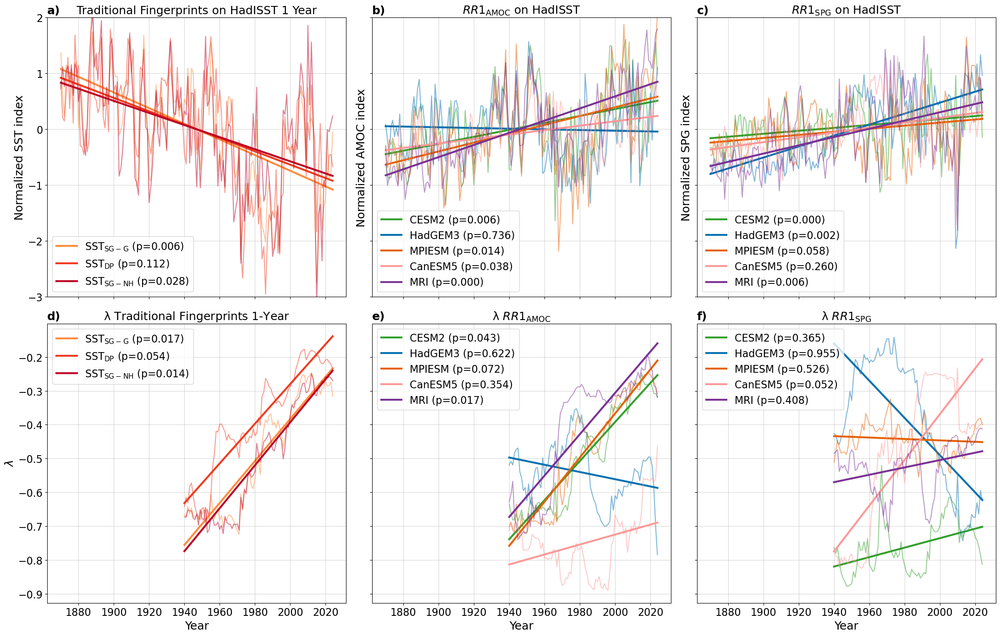

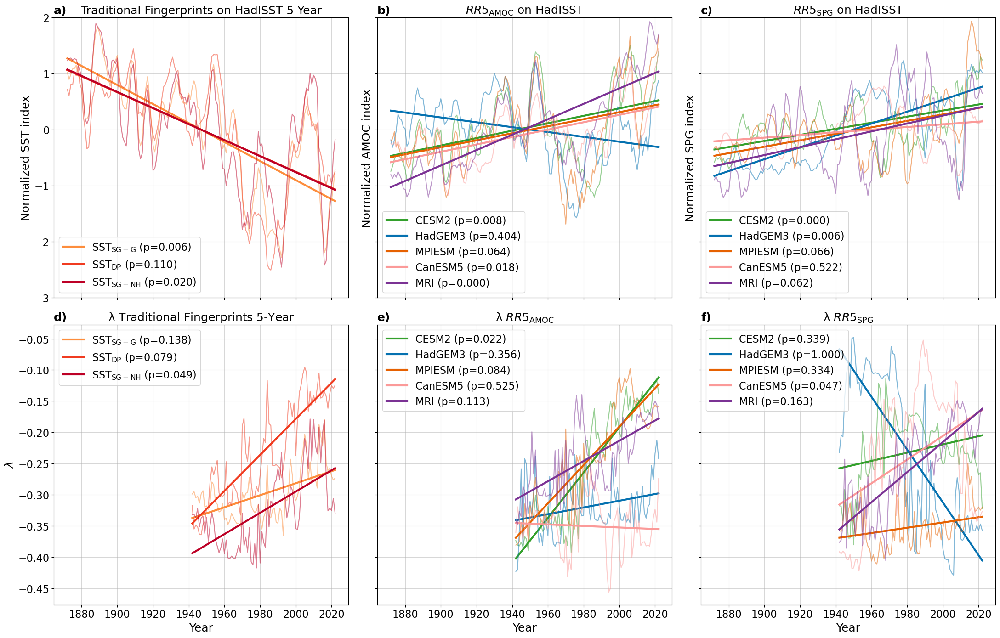

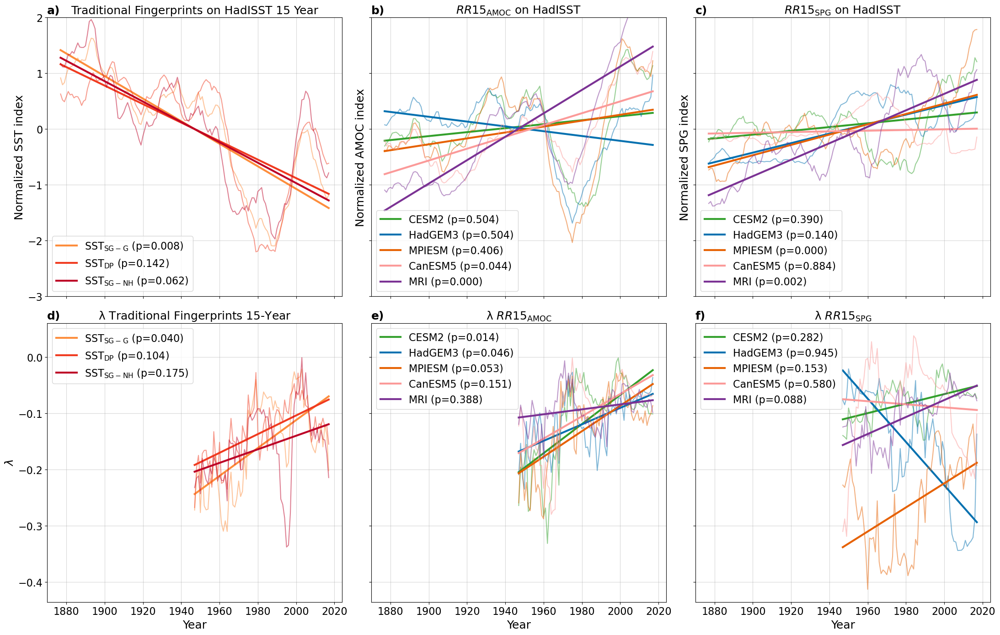

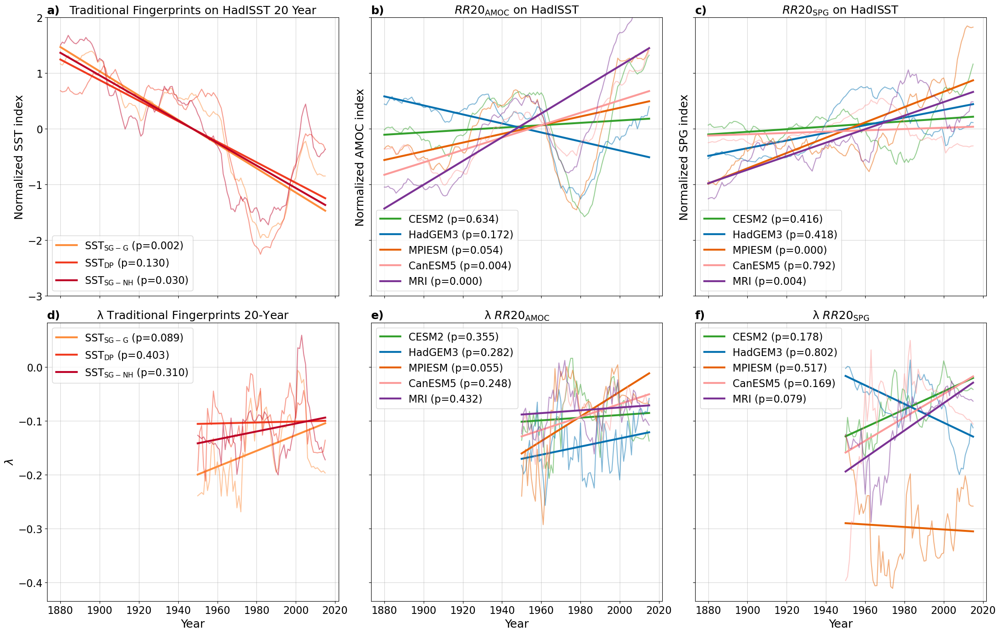

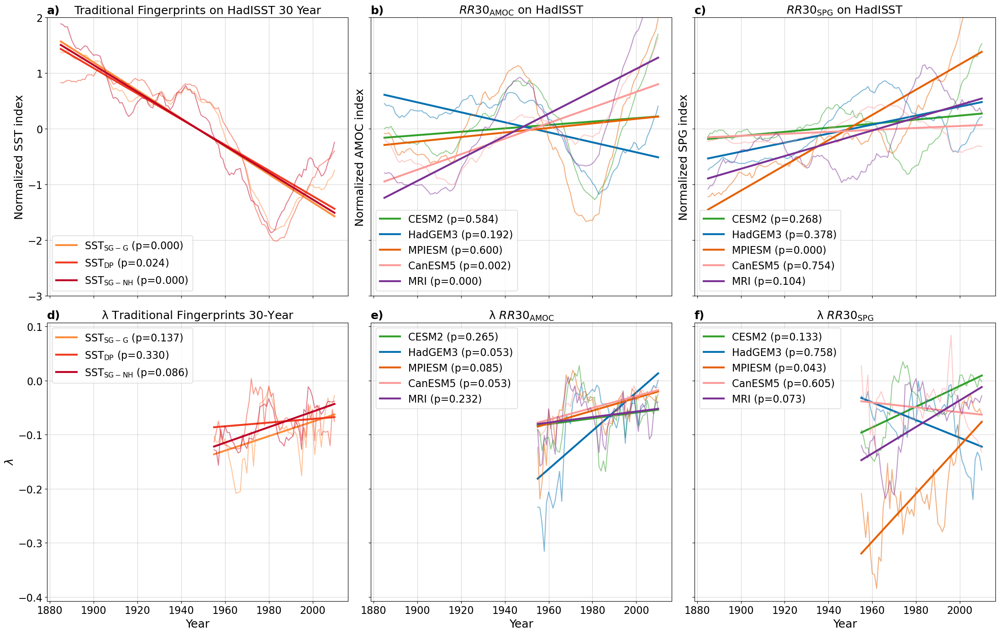

In [151]:
def make_fig5(window):

    years = HadISST_trad_fingerprints[window]["caesar"].dropna().index.values

    fig = plt.figure(figsize=(22, 14))
    gs = GridSpec(2, 6, figure=fig)

    ax1 = fig.add_subplot(gs[0, 0:2])
    ax2 = fig.add_subplot(gs[0, 2:4], sharex=ax1)
    ax3 = fig.add_subplot(gs[0, 4:6], sharex=ax1)
    ax4 = fig.add_subplot(gs[1, 0:2], sharex=ax1)
    ax5 = fig.add_subplot(gs[1, 2:4], sharex=ax1)
    ax6 = fig.add_subplot(gs[1, 4:6], sharex=ax1)

    TITLE_FS  = 18
    LABEL_FS  = 18
    TICK_FS   = 16
    LEGEND_FS = 16
    PANEL_FS  = 18

    # =============================================================
    # PANEL A
    # =============================================================

    ax1.set_ylim(-3, 2)

    for obs, region, label, color in [
        (caesar_obs, "caesar", r"$\mathrm{SST}_{\mathrm{SG-G}}$",  "#fd8d3c"),
        (dipole_obs, "dipole", r"$\mathrm{SST}_{\mathrm{DP}}$",    "#f03b20"),
        (spg_obs,    "spg",    r"$\mathrm{SST}_{\mathrm{SG-NH}}$", "#bd0026"),
    ]:
        obs=HadISST_trad_fingerprints[window][region]["sst"].dropna()
        obs_np = obs.values

        coeffs = np.polyfit(years, obs_np, 1)
        trend  = np.polyval(coeffs, years)

        ax1.plot(years, obs_np, color=color, alpha=0.5)
        ax1.plot(years, trend,  color=color, linewidth=3,label=f"{label} (p={pvals_trad_slopes[window][region]:.3f})")

    ax1.set_ylabel("Normalized SST index", fontsize=LABEL_FS)
    ax1.set_title("a)", loc="left", fontsize=PANEL_FS, fontweight="bold")
    ax1.set_title(f"Traditional Fingerprints on HadISST {window} Year", fontsize=TITLE_FS)
    ax1.grid(alpha=0.5)
    ax1.legend(loc="lower left", fontsize=LEGEND_FS)

    # =============================================================
    # PANEL B
    # =============================================================

    ax2.set_ylim(-3, 2)

    for model in all_models:
        
        preds = MOC_HadISST_model_results[model][window]["HadISST_Predictions"][0]
        mc    = get_model_color(model)

        coeffs = np.polyfit(years, preds, 1)
        trend  = np.polyval(coeffs, years)

        ax2.plot(years, preds, color=mc, alpha=0.5)
        ax2.plot(years, trend, color=mc, linewidth=3,label=f"{model} (p={pvals_RR_moc_trend[model][window]:.3f})")


    ax2.set_ylabel("Normalized AMOC index", fontsize=LABEL_FS)
    ax2.set_title("b)", loc="left", fontsize=PANEL_FS, fontweight="bold")
    ax2.set_title(rf"$RR{window}_{{\mathrm{{AMOC}}}}$ on HadISST", fontsize=TITLE_FS)
    ax2.grid(alpha=0.5)
    ax2.legend(loc="lower left", fontsize=LEGEND_FS)

    # =============================================================
    # PANEL C
    # =============================================================

    ax3.set_ylim(-3, 2)

    for model in all_models:
        preds = SPG_HadISST_model_results[model][window]["HadISST_Predictions"][0]
        mc    = get_model_color(model)

        coeffs = np.polyfit(years, preds, 1)
        trend  = np.polyval(coeffs, years)

        ax3.plot(years, preds, color=mc, alpha=0.5)
        ax3.plot(years, trend, color=mc, linewidth=3,label=f"{model} (p={pvals_RR_spg_trend[model][window]:.3f})")


    ax3.set_ylabel("Normalized SPG index", fontsize=LABEL_FS)
    ax3.set_title("c)", loc="left", fontsize=PANEL_FS, fontweight="bold")
    ax3.set_title(rf"$RR{window}_{{\mathrm{{SPG}}}}$ on HadISST", fontsize=TITLE_FS)
    ax3.grid(alpha=0.5)
    ax3.legend(loc="lower left", fontsize=LEGEND_FS)

    # =============================================================
    # PANELS D, E, F — collect data first to get shared ylim
    # =============================================================

    panel_data = {"D": [], "E": [], "F": []}

    # --- Panel D data ---
    d_entries = []
    for obs, region, label, color in [
        (lambdas_trad_fingerprints[window]["caesar"], "caesar", r"$\mathrm{SST}_{\mathrm{SG-G}}$",  "#fd8d3c"),
        (lambdas_trad_fingerprints[window]["dipole"], "dipole", r"$\mathrm{SST}_{\mathrm{DP}}$",    "#f03b20"),
        (lambdas_trad_fingerprints[window]["spg"],    "spg",    r"$\mathrm{SST}_{\mathrm{SG-NH}}$", "#bd0026"),
    ]:
        obs_valid = obs.dropna()
        y = np.asarray(obs_valid.values, dtype=float)
        years_valid = obs_valid.index.values

        time_len = np.arange(len(y))
        coeffs = np.polyfit(time_len, y, 1)
        trend = np.polyval(coeffs, time_len)

        d_entries.append((obs, region, label, color, years_valid, trend))
        panel_data["D"].append(y)
        panel_data["D"].append(trend)

    # --- Panel E data ---
    e_entries = []
    for model in all_models:
        mc = get_model_color(model)
        y_valid = lambdas_RR_MOC[model][window].dropna()
        y = np.asarray(y_valid.values, dtype=float)
        years_valid = y_valid.index.values

        time_len = np.arange(len(y))
        coeffs = np.polyfit(time_len, y, 1)
        trend = np.polyval(coeffs, time_len)

        e_entries.append((model, mc, years_valid, y, trend))
        panel_data["E"].append(y)
        panel_data["E"].append(trend)

    # --- Panel F data ---
    f_entries = []
    for model in all_models:
        mc = get_model_color(model)
        y_valid = lambdas_RR_SPG[model][window].dropna()
        y = np.asarray(y_valid.values, dtype=float)
        years_valid = y_valid.index.values

        time_len = np.arange(len(y))
        coeffs = np.polyfit(time_len, y, 1)
        trend = np.polyval(coeffs, time_len)

        f_entries.append((model, mc, years_valid, y, trend))
        panel_data["F"].append(y)
        panel_data["F"].append(trend)

    # --- Compute shared ylim across D, E, F ---
    all_vals = np.concatenate(
        [arr for arrs in panel_data.values() for arr in arrs]
    )
    ymin, ymax = np.nanmin(all_vals), np.nanmax(all_vals)
    pad = 0.05 * (ymax - ymin)
    shared_ylim = (ymin - pad, ymax + pad)

    # =============================================================
    # PANEL D
    # =============================================================
    ax4.set_ylim(shared_ylim)
    for obs, region, label, color, years_valid, trend in d_entries:
        ax4.plot(years, obs,        color=color, alpha=0.5)
        ax4.plot(years_valid, trend, color=color, linewidth=3,
                 label=f"{label} (p={pvals_trad_lambdas[window][region]:.3f})")

    ax4.set_ylabel(r"$\lambda$", fontsize=LABEL_FS)
    ax4.set_title("d)", loc="left", fontsize=PANEL_FS, fontweight="bold")
    ax4.set_title(rf"$\mathrm{{\lambda}}$ Traditional Fingerprints {window}-Year", fontsize=TITLE_FS)
    ax4.grid(alpha=0.5)
    ax4.legend(loc="upper left", fontsize=LEGEND_FS)

    # =============================================================
    # PANEL E
    # =============================================================
    ax5.set_ylim(shared_ylim)
    for model, mc, years_valid, y, trend in e_entries:
        ax5.plot(years_valid, y,     color=mc, alpha=0.5)
        ax5.plot(years_valid, trend, color=mc, linewidth=3,
                 label=f"{model} (p={pvals_RR_moc_lambda[model][window]:.3f})")

    ax5.set_ylabel(" ", fontsize=LABEL_FS)
    ax5.set_title("e)", loc="left", fontsize=PANEL_FS, fontweight="bold")
    ax5.set_title(rf"$\mathrm{{\lambda}}$ $RR{window}_{{\mathrm{{AMOC}}}}$", fontsize=TITLE_FS)
    ax5.grid(alpha=0.5)
    ax5.legend(loc="upper left", fontsize=LEGEND_FS)

    # =============================================================
    # PANEL F
    # =============================================================
    ax6.set_ylim(shared_ylim)
    for model, mc, years_valid, y, trend in f_entries:
        ax6.plot(years_valid, y,     color=mc, alpha=0.5)
        ax6.plot(years_valid, trend, color=mc, linewidth=3,
                 label=f"{model} (p={pvals_RR_spg_lambda[model][window]:.3f})")

    ax6.set_ylabel(" ", fontsize=LABEL_FS)
    ax6.set_title("f)", loc="left", fontsize=PANEL_FS, fontweight="bold")
    ax6.set_title(rf"$\mathrm{{\lambda}}$ $RR{window}_{{\mathrm{{SPG}}}}$", fontsize=TITLE_FS)
    ax6.grid(alpha=0.5)
    ax6.legend(loc="upper left", fontsize=LEGEND_FS)
    # =============================================================
    # Shared formatting
    # =============================================================
    for ax in [ax1, ax2, ax3]:
        ax.tick_params(labelbottom=False)

    for ax in [ax1, ax2, ax3, ax4, ax5, ax6]:
        ax.tick_params(axis="both", labelsize=TICK_FS)
    for ax in [ax2, ax3, ax5, ax6]:
        ax.tick_params(axis='y', labelleft=False)
    for ax in [ax4, ax5, ax6]:
        ax.set_xlabel("Year", fontsize=LABEL_FS)

    plt.tight_layout()
    plt.savefig(f"Fig5_{window}yr.pdf", format="pdf", bbox_inches="tight")
    #plt.show()


for window in windows:
    make_fig5(window)

## Fig 2

In [152]:
restoring_rates = {}
detrended_series = {}
trends = {}

for window in windows:

    restoring_rates[window] = {}
    detrended_series[window] = {}
    trends[window] = {}

    for model in all_models:

        # ------------------------
        # Load data
        # ------------------------
        data = {
            "true_moc": MOC_hist_model_results[window][model]["True_Values"],
            "RR_moc":   MOC_hist_model_results[window][model]["Historical_Predictions"],
            "true_spg": SPG_hist_model_results[window][model]["True_Values"],
            "RR_spg":   SPG_hist_model_results[window][model]["Historical_Predictions"],
            "dipole":   processed_fingerprints_hist["dipole"][model][window][f"normalized_tos_{window}yr"],
            "caesar":   processed_fingerprints_hist["caesar"][model][window][f"normalized_tos_{window}yr"],
            "spg":      processed_fingerprints_hist["spg"][model][window][f"normalized_tos_{window}yr"],
        }

        detrended_series[window][model] = {}
        trends[window][model] = {}
        restoring_rates[window][model] = {}

        # ------------------------
        # Detrend + restoring rate
        # ------------------------
        for name, ts in data.items():

            ts = pd.Series(np.squeeze(ts))

            detrended, trend = detrend_running_mean(ts)

            detrended_series[window][model][name] = detrended
            trends[window][model][name] = trend

            restoring_rates[window][model][name] = restoring_rate(
                detrended,
                w=70
            )

In [153]:
def safe_corr(true, pred):
    true = np.asarray(true, dtype=float)
    pred = np.asarray(pred, dtype=float)

    # drop any NaNs
    mask = ~np.isnan(true) & ~np.isnan(pred)

    return np.corrcoef(true[mask], pred[mask])[0, 1]

In [154]:
windows = [1, 5, 15, 20, 30]

corrs = {
    "a": {}, "b": {}, "c": {}, "d": {},
    "e": {}, "f": {}, "g": {}, "h": {},
}

for w in windows:
    for key in corrs:
        corrs[key][w] = {}

    for model in all_models:
        # --- MOC side ---
        true_moc = MOC_hist_model_results[w][model]["True_Values"]["MOC"]
        hist_preds_moc = MOC_hist_model_results[w][model]["Historical_Predictions"]
        corrs["a"][w][model] = safe_corr(true_moc, hist_preds_moc)

        rr_moc = restoring_rates[w][model]["RR_moc"]
        true_moc_rr = restoring_rates[w][model]["true_moc"]
        corrs["b"][w][model] = safe_corr(true_moc_rr, rr_moc)

        corrs["c"][w][model] = {}
        for f in ["dipole", "caesar", "spg"]:
            fp = processed_fingerprints_hist[f][model][w][f"normalized_tos_{w}yr"]
            corrs["c"][w][model][f] = safe_corr(true_moc, fp)

        caesar_rr = restoring_rates[w][model]["caesar"]
        corrs["d"][w][model] = safe_corr(true_moc_rr, caesar_rr)

        # --- SPG side ---
        true_spg = SPG_hist_model_results[w][model]["True_Values"]["min_value"]
        hist_preds_spg = SPG_hist_model_results[w][model]["Historical_Predictions"]
        corrs["e"][w][model] = safe_corr(true_spg, hist_preds_spg)

        rr_spg = restoring_rates[w][model]["RR_spg"]
        true_spg_rr = restoring_rates[w][model]["true_spg"]
        corrs["f"][w][model] = safe_corr(true_spg_rr, rr_spg)

        corrs["g"][w][model] = {}
        for f in ["dipole", "caesar", "spg"]:
            fp = processed_fingerprints_hist[f][model][w][f"normalized_tos_{w}yr"]
            corrs["g"][w][model][f] = safe_corr(true_spg, fp)

        corrs["h"][w][model] = safe_corr(true_spg_rr, caesar_rr)

corr_a, corr_b, corr_c, corr_d = corrs["a"], corrs["b"], corrs["c"], corrs["d"]
corr_e, corr_f, corr_g, corr_h = corrs["e"], corrs["f"], corrs["g"], corrs["h"]

<>:90: SyntaxWarning: invalid escape sequence '\m'
<>:90: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_3764962/1183014138.py:90: SyntaxWarning: invalid escape sequence '\m'
  linewidth=2, linestyle="--", label=f"$RR{W}_{{\mathrm{{MOC}}}}$ {model}")


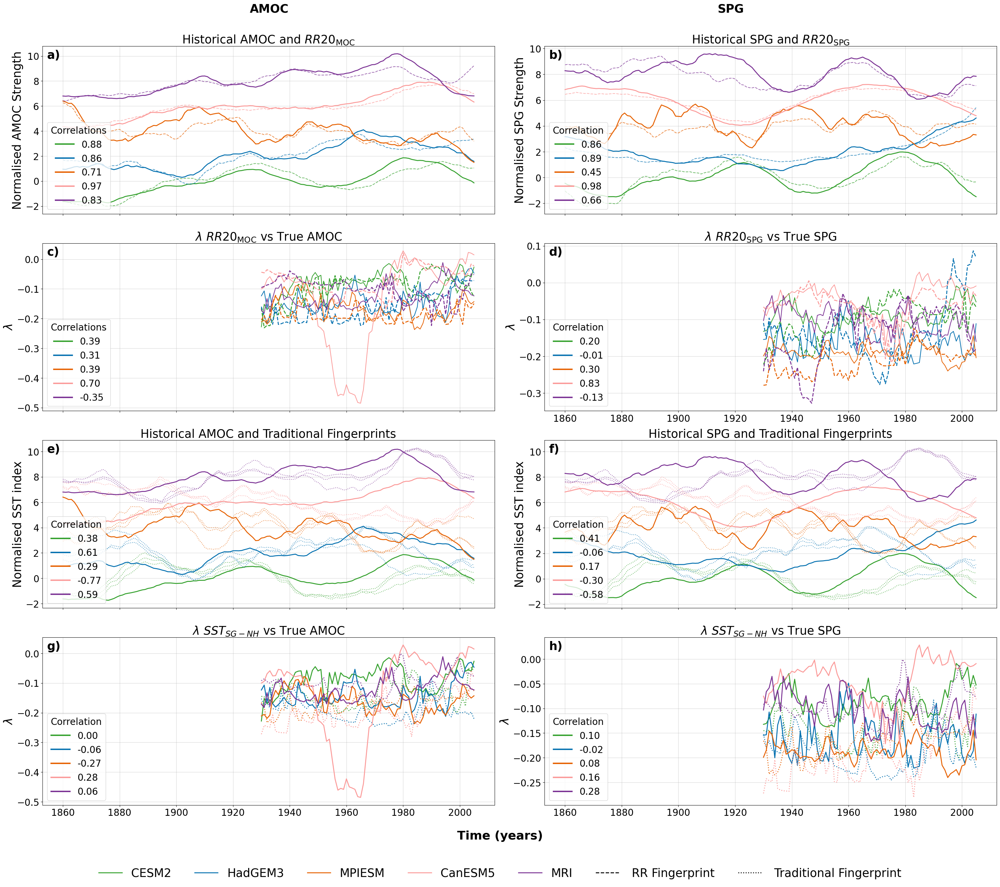

In [165]:
W = 20  # <-- change this to plot a different window
idx = MOC_hist_model_results[W]["CESM2"]["True_Values"].index
years = np.array([t.year for t in idx])
#mask = np.isnan(restoring_rates[W]["CESM2"]["caesar"])

# -------------------------------------------------------------
# Create figure
# -------------------------------------------------------------

fig = plt.figure(figsize=(30, 25))
gs = GridSpec(4, 2, figure=fig)

# --- Top row
ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])

ax3 = fig.add_subplot(gs[1, 0])
ax4 = fig.add_subplot(gs[1, 1])

ax5 = fig.add_subplot(gs[2, 0])
ax6 = fig.add_subplot(gs[2, 1])
ax7 = fig.add_subplot(gs[3, 0])
ax8 = fig.add_subplot(gs[3, 1])

TITLE_FS = 25
LABEL_FS = 25
TICK_FS = 20
LEGEND_FS = 20
PANEL_FS = 25

fig.text(0.27, 0.97, "AMOC", ha='center', fontsize=25, fontweight='bold')
fig.text(0.73, 0.97, "SPG", ha='center', fontsize=25, fontweight='bold')

# -------------------------------------------------------------
# Panel 1 (a): AMOC timeseries in each model + RR
# -------------------------------------------------------------

offset = 2  # spacing between models
legend_handles = []
for i, model in enumerate(all_models):

    hist_preds = MOC_hist_model_results[W][model]["Historical_Predictions"]
    true_moc = MOC_hist_model_results[W][model]["True_Values"]["MOC"]
    

    mc = get_model_color(model)
    y_offset = i * offset

    ax1.plot(years,
              hist_preds + y_offset,
              color=mc,
              alpha=0.7, linestyle="--",
              label=f"{model} $RR{W}_{{\\mathrm{{AMOC}}}}$")

    ax1.plot(years,
              true_moc + y_offset,
              color=mc,
              linewidth=2,
              label=f"{model} True AMOC")

    legend_handles.append(
        Line2D([], [], color=mc, lw=3, label=f"{corr_a[W][model]:.2f}")
    )

ax1.set_ylabel("Normalised AMOC Strength", fontsize=LABEL_FS)
ax1.text(0.01, 0.98, "a)", transform=ax1.transAxes, fontsize=PANEL_FS,
          fontweight='bold', va='top', ha='left')
ax1.set_title(rf"Historical AMOC and $RR{W}_{{\mathrm{{MOC}}}}$", fontsize=TITLE_FS)
ax1.tick_params(labelbottom=False, labelsize=TICK_FS)
ax1.grid(True, linestyle='-', alpha=0.5)
ax1.legend(handles=legend_handles, loc='lower left', title="Correlations",
            fontsize=LEGEND_FS, title_fontsize=LEGEND_FS)

# -------------------------------------------------------------
# Panel 3 (c): Restoring Rate of RR vs True AMOC
# -------------------------------------------------------------

legend_handles = []
for i, model in enumerate(all_models):

    restoring_rate_true = restoring_rates[W][model]["true_moc"]
    restoring_rate_RR = restoring_rates[W][model]["RR_moc"]
 
    mc = get_model_color(model)

    ax3.plot(years, restoring_rate_true, color=mc,
              label=f"{model} True MOC")

    ax3.plot(years, restoring_rate_RR, color=mc,
              linewidth=2, linestyle="--", label=f"$RR{W}_{{\mathrm{{MOC}}}}$ {model}")

    legend_handles.append(
        Line2D([], [], color=mc, lw=3, label=f"{corr_b[W][model]:.2f}")
    )

ax3.sharex(ax1)
ax3.set_ylabel(r"$\lambda$", fontsize=LABEL_FS)
ax3.text(0.01, 0.98, "c)", transform=ax3.transAxes, fontsize=PANEL_FS,
          fontweight='bold', va='top', ha='left')
ax3.set_title(fr"$\lambda$ $RR{W}_{{\mathrm{{MOC}}}}$ vs True AMOC", fontsize=TITLE_FS)
ax3.tick_params(labelbottom=False, labelsize=TICK_FS)
ax3.grid(True, linestyle='-', alpha=0.5)
ax3.legend(handles=legend_handles, loc="lower left", fontsize=LEGEND_FS,
            title="Correlations", title_fontsize=LEGEND_FS)

# -------------------------------------------------------------
# Panel 5 (e): Traditional fingerprints vs True AMOC
# -------------------------------------------------------------

fingerprints = ["dipole", "caesar", "spg"]
legend_handles = []
for i, model in enumerate(all_models):

    true_moc = MOC_hist_model_results[W][model]["True_Values"]["MOC"]
    mc = get_model_color(model)
  
    y_offset = i * offset

    for f in fingerprints:
        trad_fingerprint = processed_fingerprints_hist[f][model][W][f"normalized_tos_{W}yr"]
        ax5.plot(years, trad_fingerprint + y_offset, color=mc,
                  linestyle=":", alpha=0.7, label=f"{model} {f}")

    ax5.plot(years, true_moc + y_offset, color=mc,
              linewidth=2, label=f"{model} True MOC")

    legend_handles.append(
        Line2D([], [], color=mc, lw=3, label=f"{corr_c[W][model]['caesar']:.2f}")
    )

ax5.set_ylabel("Normalised SST index", fontsize=LABEL_FS)
ax5.text(0.01, 0.98, "e)", transform=ax5.transAxes, fontsize=PANEL_FS,
          fontweight='bold', va='top', ha='left')
ax5.set_title("Historical AMOC and Traditional Fingerprints", fontsize=TITLE_FS)
ax5.tick_params(labelbottom=False, labelsize=TICK_FS)
ax5.grid(True, linestyle='-', alpha=0.5)
ax5.legend(handles=legend_handles, loc="lower left", fontsize=LEGEND_FS,
            title="Correlation", title_fontsize=LEGEND_FS)

# -------------------------------------------------------------
# Panel 6 (f): Traditional fingerprints vs True SPG
# -------------------------------------------------------------

legend_handles = []
for i, model in enumerate(all_models):

    true_spg = SPG_hist_model_results[W][model]["True_Values"]["min_value"]
    mc = get_model_color(model)
   
    y_offset = i * offset

    for f in fingerprints:
        trad_fingerprint = processed_fingerprints_hist[f][model][W][f"normalized_tos_{W}yr"]
        ax6.plot(years, trad_fingerprint + y_offset, color=mc,
                  linestyle=":", alpha=0.7, label=f"{model} {f}")

    ax6.plot(years, true_spg + y_offset, color=mc,
              linewidth=2, label=f"{model} True SPG")

    legend_handles.append(
        Line2D([], [], color=mc, lw=3, label=f"{corr_g[W][model]['caesar']:.2f}")
    )

ax6.set_ylabel("Normalised SST index", fontsize=LABEL_FS)
ax6.text(0.01, 0.98, "f)", transform=ax6.transAxes, fontsize=PANEL_FS,
          fontweight='bold', va='top', ha='left')
ax6.set_title("Historical SPG and Traditional Fingerprints", fontsize=TITLE_FS)
ax6.tick_params(labelbottom=False, labelsize=TICK_FS)
ax6.grid(True, linestyle='-', alpha=0.5)
ax6.legend(handles=legend_handles, loc="lower left", fontsize=LEGEND_FS,
            title="Correlation", title_fontsize=LEGEND_FS)

# -------------------------------------------------------------
# Panel 7 (g): Restoring Rate of traditional fingerprint vs True AMOC
# -------------------------------------------------------------

legend_handles = []
for i, model in enumerate(all_models):

    restoring_rate_true = restoring_rates[W][model]["true_moc"]

    mc = get_model_color(model)

    ax7.plot(years, restoring_rate_true, color=mc,
              linewidth=2, label=f"{model} True MOC")

    restoring_rate_trad = restoring_rates[W][model]["caesar"]

    ax7.plot(years, restoring_rate_trad, color=mc,
              linewidth=2, linestyle=":", alpha=0.9, label=f"{model} Traditional Mean")

    legend_handles.append(
        Line2D([], [], color=mc, lw=3, label=f"{corr_d[W][model]:.2f}")
    )

ax7.sharex(ax1)
ax7.set_ylabel(r"$\lambda$", fontsize=LABEL_FS)
ax7.text(0.01, 0.98, "g)", transform=ax7.transAxes, fontsize=PANEL_FS,
          fontweight='bold', va='top', ha='left')
ax7.set_title(r"$\lambda$ $SST_{SG-NH}$ vs True AMOC", fontsize=TITLE_FS)
ax7.tick_params(axis='both', labelsize=TICK_FS)
ax7.grid(True, linestyle='-', alpha=0.5)
ax7.legend(handles=legend_handles, loc="lower left", fontsize=LEGEND_FS,
            title="Correlation", title_fontsize=LEGEND_FS)

# -------------------------------------------------------------
# Panel 8 (h): Restoring Rate of traditional fingerprint vs True SPG
# -------------------------------------------------------------

legend_handles = []
for i, model in enumerate(all_models):

    restoring_rate_true = restoring_rates[W][model]["true_spg"]

    mc = get_model_color(model)

    ax8.plot(years, restoring_rate_true, color=mc,
              linewidth=2, label=f"{model} True SPG")

    restoring_rate_trad = restoring_rates[W][model]["caesar"]

    ax8.plot(years, restoring_rate_trad, color=mc,
              linewidth=2, linestyle=":", alpha=0.9, label=f"{model} Traditional Mean")

    legend_handles.append(
        Line2D([], [], color=mc, lw=3, label=f"{corr_h[W][model]:.2f}")
    )

ax8.sharex(ax1)
ax8.set_ylabel(r"$\lambda$", fontsize=LABEL_FS)
ax8.text(0.01, 0.98, "h)", transform=ax8.transAxes, fontsize=PANEL_FS,
          fontweight='bold', va='top', ha='left')
ax8.set_title(r"$\lambda$ $SST_{SG-NH}$ vs True SPG", fontsize=TITLE_FS)
ax8.tick_params(axis='both', labelsize=TICK_FS)
ax8.grid(True, linestyle='-', alpha=0.5)
ax8.legend(handles=legend_handles, loc="lower left", fontsize=LEGEND_FS,
            title="Correlation", title_fontsize=LEGEND_FS)

# -------------------------------------------------------------
# Panel 2 (b): SPG timeseries in each model + RR
# -------------------------------------------------------------

legend_handles = []
for i, model in enumerate(all_models):

    hist_preds = SPG_hist_model_results[W][model]["Historical_Predictions"]
    true_spg = SPG_hist_model_results[W][model]["True_Values"]["min_value"]
   
    mc = get_model_color(model)
    y_offset = i * offset

    ax2.plot(years, hist_preds + y_offset, color=mc,
              alpha=0.7, linestyle="--", label=f"{model} $RR{W}_{{\\mathrm{{SPG}}}}$")

    ax2.plot(years, true_spg + y_offset, color=mc,
              linewidth=2, label=f"{model} True SPG")

    legend_handles.append(
        Line2D([], [], color=mc, lw=3, label=f"{corr_e[W][model]:.2f}")  # fixed: was corr_g[...]['caesar']
    )

ax2.set_ylabel("Normalised SPG Strength", fontsize=LABEL_FS)
ax2.text(0.01, 0.98, "b)", transform=ax2.transAxes, fontsize=PANEL_FS,
          fontweight='bold', va='top', ha='left')
ax2.set_title(rf"Historical SPG and $RR{W}_{{\mathrm{{SPG}}}}$", fontsize=TITLE_FS)
ax2.tick_params(labelbottom=False, labelsize=TICK_FS)
ax2.grid(True, linestyle='-', alpha=0.5)
ax2.legend(handles=legend_handles, loc="lower left", fontsize=LEGEND_FS,
            title="Correlation", title_fontsize=LEGEND_FS)

# -------------------------------------------------------------
# Panel 4 (d): Restoring Rate of RR vs True SPG
# -------------------------------------------------------------

legend_handles = []
for i, model in enumerate(all_models):

    restoring_rate_true = restoring_rates[W][model]["true_spg"]
    restoring_rate_RR = restoring_rates[W][model]["RR_spg"]
    year = np.arange(1850, 1850 + len(restoring_rate_true))
    mc = get_model_color(model)

    ax4.plot(years, restoring_rate_true, color=mc,
              label=f"{model} True SPG")

    ax4.plot(years, restoring_rate_RR, color=mc,
              linewidth=2, linestyle="--", label=f"{model} $RR{W}_{{\\mathrm{{SPG}}}}$")

    legend_handles.append(
        Line2D([], [], color=mc, lw=3, label=f"{corr_f[W][model]:.2f}")
    )

ax4.set_ylabel(r"$\lambda$", fontsize=LABEL_FS)
ax4.text(0.01, 0.98, "d)", transform=ax4.transAxes, fontsize=PANEL_FS,
          fontweight='bold', va='top', ha='left')
ax4.set_title(fr"$\lambda$ $RR{W}_{{\mathrm{{SPG}}}}$ vs True SPG", fontsize=TITLE_FS)
ax4.tick_params(axis='both', labelsize=TICK_FS)
ax4.grid(True, linestyle='-', alpha=0.5)
ax4.sharex(ax5)
ax4.legend(handles=legend_handles, loc="lower left", fontsize=LEGEND_FS,
            title="Correlation", title_fontsize=LEGEND_FS)

fig.text(0.5, -0.02, "Time (years)", ha='center', fontsize=26, fontweight="bold")

# =========================
# --- LEGEND --------------
# =========================
legend_handles = []

for model in all_models:
    color = get_model_color(model)
    legend_handles.append(
        Line2D([], [], color=color, lw=2, linestyle='-', label=f'{model}')
    )

legend_handles.append(
    Line2D([], [], color="black", lw=2, linestyle='--', label=" RR Fingerprint")
)
legend_handles.append(
    Line2D([], [], color="black", lw=2, linestyle=':', label=" Traditional Fingerprint")
)

fig.legend(handles=legend_handles, loc='lower center', ncol=7, fontsize=25,
            frameon=False, bbox_to_anchor=(0.5, -0.08))

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("Fig2_new20.pdf", format='pdf', bbox_inches='tight')
plt.show()

# Correlations

In [ ]:
# correlations = []
# mse = []

# for model in all_models:
#     for W in windows:

#         corr_dict = {"Model": model, "window": W}
#         mse_dict = {"Model": model, "window": W}

#         moc_train = pd.Series(MOC_pi_model_results[W][model]["Training_timeseries"].iloc[0])
#         moc_test  = pd.Series(MOC_pi_model_results[W][model]["True_Values"].iloc[0])
#         full_moc  = pd.concat([moc_train, moc_test], ignore_index=True)

#         spg_train = pd.Series(SPG_pi_model_results[W][model]["Training_timeseries"].iloc[0])
#         spg_test  = pd.Series(SPG_pi_model_results[W][model]["True_Values"].iloc[0])
#         full_spg  = pd.concat([spg_train, spg_test], ignore_index=True)

#         for fingerprint in ["dipole", "spg", "caesar"]:

#             fp = np.asarray(processed_fingerprints_pi[fingerprint][model][W][f"normalized_tos_{W}yr"])

#             min_len = min(len(full_moc), len(full_spg), len(fp))

#             moc_vals = full_moc.values[:min_len]
#             spg_vals = full_spg.values[:min_len]
#             fp_vals  = fp[:min_len]

#             corr_moc = pearsonr(moc_vals, fp_vals)[0]
#             corr_spg = pearsonr(spg_vals, fp_vals)[0]

#             corr_dict[f"{fingerprint}_moc_corr"] = corr_moc
#             corr_dict[f"{fingerprint}_spg_corr"] = corr_spg

#             mse_moc = np.mean((moc_vals - fp_vals)**2)
#             mse_spg = np.mean((spg_vals - fp_vals)**2)

#             mse_dict[f"{fingerprint}_moc_mse"] = mse_moc
#             mse_dict[f"{fingerprint}_spg_mse"] = mse_spg

#         correlations.append(corr_dict)
#         mse.append(mse_dict)

# Fingerprint_pi_correlations_df = pd.DataFrame(correlations)
# Fingerprint_pi_mse_df = pd.DataFrame(mse)

In [ ]:
correlations = []
mse = []

for model in all_models:
    for W in windows:

        corr_dict = {"Model": model, "window": W}
        mse_dict = {"Model": model, "window": W}

        moc_train = pd.Series(MOC_pi_model_results[W][model]["Training_timeseries"].iloc[0])
        moc_test  = pd.Series(MOC_pi_model_results[W][model]["True_Values"].iloc[0])
        full_moc  = pd.concat([moc_train, moc_test], ignore_index=True)

        spg_train = pd.Series(SPG_pi_model_results[W][model]["Training_timeseries"].iloc[0])
        spg_test  = pd.Series(SPG_pi_model_results[W][model]["True_Values"].iloc[0])
        full_spg  = pd.concat([spg_train, spg_test], ignore_index=True)

        # --- RR (Test_Predictions) vs held-out True_Values ---
        rr_moc_pred = pd.Series(MOC_pi_model_results[W][model]["Test_Predictions"].iloc[0])
        rr_spg_pred = pd.Series(SPG_pi_model_results[W][model]["Test_Predictions"].iloc[0])

        corr_dict["RR_moc_corr"] = pearsonr(moc_test, rr_moc_pred)[0]
        corr_dict["RR_spg_corr"] = pearsonr(spg_test, rr_spg_pred)[0]

        mse_dict["RR_moc_mse"] = np.mean((moc_test - rr_moc_pred)**2)
        mse_dict["RR_spg_mse"] = np.mean((spg_test- rr_spg_pred)**2)

        # --- loop fingerprints ---
        for fingerprint in ["dipole", "spg", "caesar"]:

            fp = np.asarray(processed_fingerprints_pi[fingerprint][model][W][f"normalized_tos_{W}yr"])

            min_len = min(len(full_moc), len(full_spg), len(fp))

            moc_vals = full_moc.values[:min_len]
            spg_vals = full_spg.values[:min_len]
            fp_vals  = fp[:min_len]

            corr_dict[f"{fingerprint}_moc_corr"] = pearsonr(moc_vals, fp_vals)[0]
            corr_dict[f"{fingerprint}_spg_corr"] = pearsonr(spg_vals, fp_vals)[0]

            mse_dict[f"{fingerprint}_moc_mse"] = np.mean((moc_vals - fp_vals)**2)
            mse_dict[f"{fingerprint}_spg_mse"] = np.mean((spg_vals - fp_vals)**2)

        correlations.append(corr_dict)
        mse.append(mse_dict)

Fingerprint_pi_correlations_df = pd.DataFrame(correlations)
Fingerprint_pi_mse_df = pd.DataFrame(mse)


In [ ]:
correlations = []
mse = []

for model in all_models:
    for W in windows:
        corr_dict = {"Model": model, "window": W}
        mse_dict = {"Model": model, "window": W}

        full_moc = MOC_hist_model_results[W][model]["True_Values"]["MOC"]
        full_spg = SPG_hist_model_results[W][model]["True_Values"]["min_value"]

        moc_vals_full = full_moc.values
        spg_vals_full = full_spg.values

        # --- RR (Historical_Predictions) vs True_Values ---
        rr_moc_pred = np.asarray(MOC_hist_model_results[W][model]["Historical_Predictions"])
        rr_spg_pred = np.asarray(SPG_hist_model_results[W][model]["Historical_Predictions"])

        rr_n_moc = min(len(moc_vals_full), len(rr_moc_pred))
        rr_n_spg = min(len(spg_vals_full), len(rr_spg_pred))

        corr_dict["RR_moc_corr"] = pearsonr(moc_vals_full[:rr_n_moc], rr_moc_pred[:rr_n_moc])[0]
        corr_dict["RR_spg_corr"] = pearsonr(spg_vals_full[:rr_n_spg], rr_spg_pred[:rr_n_spg])[0]

        mse_dict["RR_moc_mse"] = np.mean((moc_vals_full[:rr_n_moc] - rr_moc_pred[:rr_n_moc]) ** 2)
        mse_dict["RR_spg_mse"] = np.mean((spg_vals_full[:rr_n_spg] - rr_spg_pred[:rr_n_spg]) ** 2)

        # --- loop fingerprints ---
        for fingerprint in ["dipole", "spg", "caesar"]:
            fp = np.asarray(processed_fingerprints_hist[fingerprint][model][W][f"normalized_tos_{W}yr"])

            min_len = min(len(moc_vals_full), len(spg_vals_full), len(fp))

            moc_vals = moc_vals_full[:min_len]
            spg_vals = spg_vals_full[:min_len]
            fp_vals = fp[:min_len]

            corr_dict[f"{fingerprint}_moc_corr"] = pearsonr(moc_vals, fp_vals)[0]
            corr_dict[f"{fingerprint}_spg_corr"] = pearsonr(spg_vals, fp_vals)[0]

            mse_dict[f"{fingerprint}_moc_mse"] = np.mean((moc_vals - fp_vals) ** 2)
            mse_dict[f"{fingerprint}_spg_mse"] = np.mean((spg_vals - fp_vals) ** 2)

        correlations.append(corr_dict)
        mse.append(mse_dict)

Fingerprint_hist_correlations_df = pd.DataFrame(correlations)
Fingerprint_hist_mse_df = pd.DataFrame(mse)

In [ ]:
Fingerprint_hist_correlations_df

,Model,window,RR_moc_corr,RR_spg_corr,dipole_moc_corr,dipole_spg_corr,spg_moc_corr,spg_spg_corr,caesar_moc_corr,caesar_spg_corr
0,CESM2,1,0.860622,0.794350,0.150444,0.100074,0.342803,0.319533,0.306926,0.282046
1,CESM2,5,0.888409,0.836685,0.177659,0.093256,0.465734,0.437444,0.381773,0.362021
2,CESM2,15,0.902299,0.838051,0.162997,0.149300,0.543319,0.555309,0.419912,0.438006
3,CESM2,20,0.880298,0.856270,0.115191,0.115156,0.523843,0.538992,0.383307,0.405675
4,CESM2,30,0.861167,0.773012,-0.093837,-0.061962,0.385510,0.429543,0.198462,0.252264
5,HadGEM3,1,0.733731,0.811560,0.027279,-0.017361,0.306550,-0.087659,0.366020,-0.090148
6,HadGEM3,5,0.769617,0.852967,-0.009901,-0.004603,0.412674,-0.115566,0.463202,-0.104565
7,HadGEM3,15,0.856284,0.879337,-0.151737,-0.108128,0.574939,-0.131745,0.604690,-0.102792
8,HadGEM3,20,0.862093,0.894742,-0.238078,-0.167123,0.577939,-0.087797,0.610090,-0.058093
9,HadGEM3,30,0.893718,0.884808,-0.351367,-0.281125,0.627052,0.055557,0.648667,0.083448


# CESM2 Plot

In [ ]:
# CESM2_results = {}

# for fingerprint in ["dipole", "spg", "caesar"]:
#     CESM2_results[fingerprint] = {
#         'corr_pi': Fingerprint_pi_correlations_df[Fingerprint_pi_correlations_df['Model'] == 'CESM2'][f"{fingerprint}_moc_corr"].values[0],
#         'mse_pi': Fingerprint_pi_mse_df[Fingerprint_pi_mse_df['Model'] == 'CESM2'][f"{fingerprint}_moc_mse"].values[0],
        
#         'corr_hist': Fingerprint_hist_correlations_df[Fingerprint_hist_correlations_df['Model'] == 'CESM2'][f"{fingerprint}_moc_corr"].values[0],
#         'mse_hist': Fingerprint_hist_mse_df[Fingerprint_hist_mse_df['Model'] == 'CESM2'][f"{fingerprint}_moc_mse"].values[0]
#     }


In [ ]:
# =========================
# --- DATA EXTRACTION -----
# =========================

# piControl
df_5yr  = MOC_pi_model_results[5]["CESM2"]
df_30yr = MOC_pi_model_results[30]["CESM2"]

row_5yr  = df_5yr[df_5yr["Alpha"] == 1000.0].iloc[0]
row_30yr = df_30yr[df_30yr["Alpha"] == 1000.0].iloc[0]

training_ts_5yr      = row_5yr["Training_timeseries"]
true_values_ts_5yr   = row_5yr["True_Values"]
test_predictions_5yr = row_5yr["Test_Predictions"]

training_ts_30yr      = row_30yr["Training_timeseries"]
true_values_ts_30yr   = row_30yr["True_Values"]
test_predictions_30yr = row_30yr["Test_Predictions"]

merged_5yr  = np.array(list(training_ts_5yr) + list(true_values_ts_5yr))
merged_30yr = np.array(list(training_ts_30yr) + list(true_values_ts_30yr))


# Historical
df_5yr_hist  = MOC_hist_model_results[5]["CESM2"]
df_30yr_hist = MOC_hist_model_results[30]["CESM2"]

hist_true_5yr  = df_5yr_hist["True_Values"]
hist_pred_5yr  = df_5yr_hist["Historical_Predictions"]

hist_true_30yr = df_30yr_hist["True_Values"]
hist_pred_30yr = df_30yr_hist["Historical_Predictions"]


# =========================
# --- TIME AXES ----------
# =========================

# piControl
years_5yr  = processed_fingerprints_pi["spg"]["CESM2"][5]["year"].values
years_30yr = processed_fingerprints_pi["spg"]["CESM2"][5]["year"].values

train_len_5yr = len(training_ts_5yr)
test_len_5yr  = len(true_values_ts_5yr)

train_len_30yr = len(training_ts_30yr)
test_len_30yr  = len(true_values_ts_30yr)

pi_time_train_5yr = years_5yr[:train_len_5yr]
pi_time_test_5yr  = years_5yr[train_len_5yr:train_len_5yr + test_len_5yr]
pi_time_tot_5yr   = years_5yr[:train_len_5yr + test_len_5yr]

pi_time_train_30yr = years_30yr[:train_len_30yr]
pi_time_test_30yr  = years_30yr[train_len_30yr:train_len_30yr + test_len_30yr]
pi_time_tot_30yr   = years_30yr[:train_len_30yr + test_len_30yr]


# Historical time
hist_time_5yr  = processed_fingerprints_hist["spg"]["CESM2"][5]["year"].values
hist_time_30yr = processed_fingerprints_hist["spg"]["CESM2"][30]["year"].values

In [ ]:
# =========================
# --- COLOR DEFINITIONS ---
# =========================

COL_AMOC   = "#0571b0"   # blue (HadGEM-style)
COL_RIDGE  = "#000000"   # black

COL_SPG    = "#bd0026"   # SG-NH
COL_DIPOLE = "#f03b20"   # DP
COL_CAESAR = "#fd8d3c"   # SG-G

# Mapping for consistency
SST_COLORS = {
    "caesar": COL_CAESAR,
    "dipole": COL_DIPOLE,
    "spg": COL_SPG
}


# =========================
# --- DATA EXTRACTION -----
# =========================
# (unchanged)
df_5yr  = MOC_pi_model_results[5]["CESM2"]
df_30yr = MOC_pi_model_results[30]["CESM2"]

row_5yr  = df_5yr[df_5yr["Alpha"] == 1000.0].iloc[0]
row_30yr = df_30yr[df_30yr["Alpha"] == 1000.0].iloc[0]

training_ts_5yr      = row_5yr["Training_timeseries"]
true_values_ts_5yr   = row_5yr["True_Values"]
test_predictions_5yr = row_5yr["Test_Predictions"]

training_ts_30yr      = row_30yr["Training_timeseries"]
true_values_ts_30yr   = row_30yr["True_Values"]
test_predictions_30yr = row_30yr["Test_Predictions"]

merged_5yr  = np.array(list(training_ts_5yr) + list(true_values_ts_5yr))
merged_30yr = np.array(list(training_ts_30yr) + list(true_values_ts_30yr))

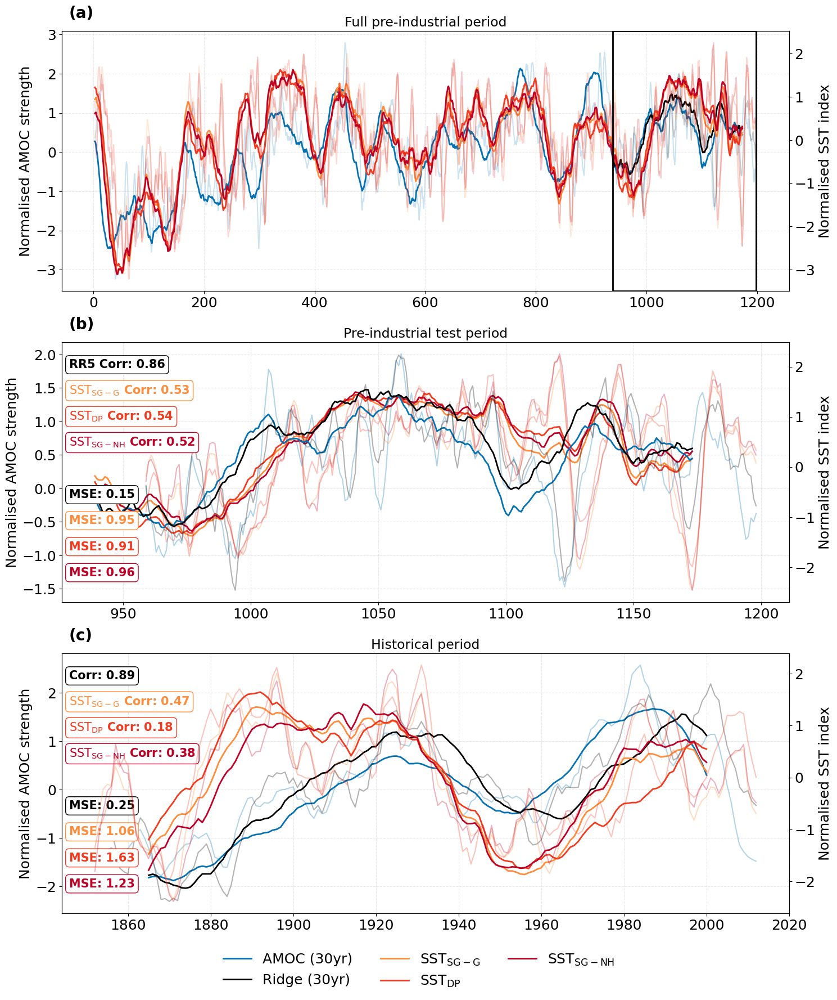

In [ ]:

# =========================
# --- FIGURE SETUP -------
# =========================
fig, axes = plt.subplots(3, 1, figsize=(15, 18))

panel_labels = ['a', 'b', 'c']
for ax, label in zip(axes, panel_labels):
    ax.annotate(f"({label})", xy=(0.01, 1.05), xycoords='axes fraction',
                fontsize=20, fontweight='bold')

font_size = 18
subtitle_size = 17


# =========================
# --- PANEL (a): FULL PI --
# =========================
ax = axes[0]
axes[0].set_title("Full pre-industrial period", fontsize=subtitle_size)
# AMOC
ax.plot(pi_time_tot_5yr, merged_5yr, color=COL_AMOC, alpha=0.2)
ax.plot(pi_time_tot_30yr, merged_30yr, color=COL_AMOC, linewidth=2, label="True AMOC")

# Ridge
ax.plot(pi_time_test_5yr, test_predictions_5yr, color=COL_RIDGE, alpha=0.2,label=r"$RR5_{MOC}$ CESM2")
ax.plot(pi_time_test_30yr, test_predictions_30yr, color=COL_RIDGE, linewidth=2, label=r"$RR30_{MOC}$ CESM2")
ax.tick_params(axis='both', labelsize=font_size)
# SST
ax2 = ax.twinx()
ax2.tick_params(axis='both', labelsize=font_size)

for key in ["caesar", "dipole", "spg"]:
    color = SST_COLORS[key]

    ax2.plot(pi_time_tot_30yr,
             processed_fingerprints_pi[key]["CESM2"][30]["normalized_tos_30yr"],
             color=color, linewidth=2)

    ax2.plot(pi_time_tot_5yr,
             processed_fingerprints_pi[key]["CESM2"][5]["normalized_tos_5yr"],
             color=color, alpha=0.2)

ridge_xmin = min(pi_time_test_5yr.min(), pi_time_test_30yr.min())
ridge_xmax = max(pi_time_test_5yr.max(), pi_time_test_30yr.max())

ax2.axvspan(ridge_xmin, ridge_xmax,
            facecolor="none", edgecolor="black",
            linewidth=2, zorder=10)

ax.set_ylabel("Normalised AMOC strength", fontsize=font_size)
ax2.set_ylabel("Normalised SST index", fontsize=font_size)
ax.grid(True, alpha=0.3, linestyle="--")
ax.set_axisbelow(True)
# =========================
# --- PANEL (b): TEST -----
# =========================
ax = axes[1]
axes[1].set_title("Pre-industrial test period", fontsize=subtitle_size)

ax.plot(pi_time_test_5yr, true_values_ts_5yr, color=COL_AMOC, alpha=0.3)
ax.plot(pi_time_test_30yr, true_values_ts_30yr, color=COL_AMOC, linewidth=2)

ax.plot(pi_time_test_5yr, test_predictions_5yr, color=COL_RIDGE, alpha=0.3)
ax.plot(pi_time_test_30yr, test_predictions_30yr, color=COL_RIDGE, linewidth=2)

ax2 = ax.twinx()
ax.set_zorder(2)
ax.patch.set_visible(False)   # prevents blocking the plot

for key in ["caesar", "dipole", "spg"]:
    color = SST_COLORS[key]

    fp_5yr = processed_fingerprints_pi[key]["CESM2"][5]["normalized_tos_5yr"]
    start_5yr = len(fp_5yr) - len(pi_time_test_5yr)

    ax2.plot(pi_time_test_5yr,
             fp_5yr[start_5yr:],
             color=color,
             alpha=0.3,
             linewidth=1.5)

    fp_30yr = processed_fingerprints_pi[key]["CESM2"][30]["normalized_tos_30yr"]
    start_30yr = len(fp_30yr) - len(pi_time_test_30yr)

    ax2.plot(pi_time_test_30yr,
             fp_30yr[start_30yr:],
             color=color,
             linewidth=2)
ax.tick_params(axis='both', labelsize=font_size)
ax2.tick_params(axis='both', labelsize=font_size)
ax.set_ylabel("Normalised AMOC strength", fontsize=font_size)
ax2.set_ylabel("Normalised SST index", fontsize=font_size)
ax.grid(True, alpha=0.3, linestyle="--")
ax.set_axisbelow(True)

# --- correlations (left column)
ax.annotate(
    f"RR5 Corr: {Fingerprint_pi_correlations_df["RR_moc_corr"].iloc[1]:.2f}",
    xy=(0.01, 0.9), xycoords='axes fraction',
    color=COL_RIDGE,
    bbox=dict(facecolor="white", alpha=1, edgecolor=COL_RIDGE, boxstyle="round,pad=0.3"),
    fontsize=15, fontweight="bold",zorder=100
)

ax.annotate(
    rf"$\mathrm{{SST}}_{{\mathrm{{SG-G}}}}$ Corr: {Fingerprint_pi_correlations_df["spg_moc_corr"].iloc[1]:.2f}",
    xy=(0.01, 0.8), xycoords='axes fraction',
    color=COL_CAESAR,
    bbox=dict(facecolor="white", alpha=1, edgecolor=COL_CAESAR, boxstyle="round,pad=0.3"),
    fontsize=15, fontweight="bold",zorder=100
)

ax.annotate(
    rf"$\mathrm{{SST}}_{{\mathrm{{DP}}}}$ Corr: {Fingerprint_pi_correlations_df["dipole_moc_corr"].iloc[1]:.2f}",
    xy=(0.01, 0.7), xycoords='axes fraction',
    color=COL_DIPOLE,
    bbox=dict(facecolor="white", alpha=1, edgecolor=COL_DIPOLE, boxstyle="round,pad=0.3"),
    fontsize=15, fontweight="bold",zorder=100
)

ax.annotate(
    rf"$\mathrm{{SST}}_{{\mathrm{{SG-NH}}}}$ Corr: {Fingerprint_pi_correlations_df["caesar_moc_corr"].iloc[1]:.2f}",
    xy=(0.01, 0.6), xycoords='axes fraction',
    color=COL_SPG,
    bbox=dict(facecolor="white", alpha=1, edgecolor=COL_SPG, boxstyle="round,pad=0.3"),
    fontsize=15, fontweight="bold",zorder=100
)

# --- MSE (right column)
ax.annotate(
    f"MSE: {Fingerprint_pi_mse_df["RR_moc_mse"].iloc[1]:.2f}",
    xy=(0.01, 0.4), xycoords='axes fraction',
    color=COL_RIDGE,
    bbox=dict(facecolor="white", alpha=1, edgecolor=COL_RIDGE, boxstyle="round,pad=0.3"),
    fontsize=15, fontweight="bold",zorder=100
)

ax.annotate(
    f"MSE: {Fingerprint_pi_mse_df["spg_moc_mse"].iloc[1]:.2f}",
    xy=(0.01, 0.3), xycoords='axes fraction',
    color=COL_CAESAR,
    bbox=dict(facecolor="white", alpha=1, edgecolor=COL_CAESAR, boxstyle="round,pad=0.3"),
    fontsize=15, fontweight="bold",zorder=100
)

ax.annotate(
    f"MSE: {Fingerprint_pi_mse_df["dipole_moc_mse"].iloc[1]:.2f}",
    xy=(0.01, 0.2), xycoords='axes fraction',
    color=COL_DIPOLE,
    bbox=dict(facecolor="white", alpha=1, edgecolor=COL_DIPOLE, boxstyle="round,pad=0.3"),
    fontsize=15, fontweight="bold",zorder=100
)

ax.annotate(
    f"MSE: {Fingerprint_pi_mse_df["caesar_moc_mse"].iloc[1]:.2f}",
    xy=(0.01, 0.1), xycoords='axes fraction',
    color=COL_SPG,
    bbox=dict(facecolor="white", alpha=1, edgecolor=COL_SPG, boxstyle="round,pad=0.3"),
    fontsize=15, fontweight="bold",zorder=100
)
# =========================
# --- PANEL (c): HIST -----
# =========================
ax = axes[2]
axes[2].set_title("Historical period", fontsize=subtitle_size)
ax.plot(hist_time_5yr, hist_true_5yr, color=COL_AMOC, alpha=0.3)
ax.plot(hist_time_30yr, hist_true_30yr, color=COL_AMOC, linewidth=2)

ax.plot(hist_time_5yr, hist_pred_5yr, color=COL_RIDGE, alpha=0.3)
ax.plot(hist_time_30yr, hist_pred_30yr, color=COL_RIDGE, linewidth=2)
ax.tick_params(axis='both', labelsize=font_size)
ax2 = ax.twinx()
ax2.tick_params(axis='both', labelsize=font_size)
for key in ["caesar", "dipole", "spg"]:
    color = SST_COLORS[key]

    fp_30yr = processed_fingerprints_hist[key]["CESM2"][30]["normalized_tos_30yr"]
    start_30yr = len(fp_30yr) - len(hist_time_30yr)

    ax2.plot(hist_time_30yr,
             fp_30yr[start_30yr:],
             color=color,
             linewidth=2)

    fp_5yr = processed_fingerprints_hist[key]["CESM2"][5]["normalized_tos_5yr"]
    start_5yr = len(fp_5yr) - len(hist_time_5yr)

    ax2.plot(hist_time_5yr,
             fp_5yr[start_5yr:],
             color=color,
             alpha=0.3,
             linewidth=1.5)

ax.set_ylabel("Normalised AMOC strength", fontsize=font_size)
ax2.set_ylabel("Normalised SST index", fontsize=font_size)
ax.grid(True, alpha=0.3, linestyle="--")
ax.set_axisbelow(True)
# --- correlations (left column)
ax.annotate(
    f"Corr: {Fingerprint_hist_correlations_df["RR_moc_corr"].iloc[1]:.2f}",
    xy=(0.01, 0.9), xycoords='axes fraction',
    color=COL_RIDGE,
    bbox=dict(facecolor="white", alpha=1, edgecolor=COL_RIDGE, boxstyle="round,pad=0.3"),
    fontsize=15, fontweight="bold", zorder=100
)

ax.annotate(
    rf"$\mathrm{{SST}}_{{\mathrm{{SG-G}}}}$ Corr: {Fingerprint_hist_correlations_df["spg_moc_corr"].iloc[1]:.2f}",
    xy=(0.01, 0.8), xycoords='axes fraction',
    color=COL_CAESAR,
    bbox=dict(facecolor="white", alpha=1, edgecolor=COL_CAESAR, boxstyle="round,pad=0.3"),
    fontsize=15, fontweight="bold", zorder=100
)

ax.annotate(
    rf"$\mathrm{{SST}}_{{\mathrm{{DP}}}}$ Corr: {Fingerprint_hist_correlations_df["dipole_moc_corr"].iloc[1]:.2f}",
    xy=(0.01, 0.7), xycoords='axes fraction',
    color=COL_DIPOLE,
    bbox=dict(facecolor="white", alpha=1, edgecolor=COL_DIPOLE, boxstyle="round,pad=0.3"),
    fontsize=15, fontweight="bold", zorder=100
)

ax.annotate(
    rf"$\mathrm{{SST}}_{{\mathrm{{SG-NH}}}}$ Corr: {Fingerprint_hist_correlations_df["caesar_moc_corr"].iloc[1]:.2f}",
    xy=(0.01, 0.6), xycoords='axes fraction',
    color=COL_SPG,
    bbox=dict(facecolor="white", alpha=1, edgecolor=COL_SPG, boxstyle="round,pad=0.3"),
    fontsize=15, fontweight="bold", zorder=100
)

# --- MSE (right column)
ax.annotate(
    f"MSE: {Fingerprint_hist_mse_df["RR_moc_mse"].iloc[1]:.2f}",
    xy=(0.01, 0.4), xycoords='axes fraction',
    color=COL_RIDGE,
    bbox=dict(facecolor="white", alpha=1, edgecolor=COL_RIDGE, boxstyle="round,pad=0.3"),
    fontsize=15, fontweight="bold", zorder=100
)

ax.annotate(
    f"MSE: {Fingerprint_hist_mse_df["spg_moc_mse"].iloc[1]:.2f}",
    xy=(0.01, 0.3), xycoords='axes fraction',
    color=COL_CAESAR,
    bbox=dict(facecolor="white", alpha=1, edgecolor=COL_CAESAR, boxstyle="round,pad=0.3"),
    fontsize=15, fontweight="bold", zorder=100
)

ax.annotate(
    f"MSE: {Fingerprint_hist_mse_df["dipole_moc_mse"].iloc[1]:.2f}",
    xy=(0.01, 0.2), xycoords='axes fraction',
    color=COL_DIPOLE,
    bbox=dict(facecolor="white", alpha=1, edgecolor=COL_DIPOLE, boxstyle="round,pad=0.3"),
    fontsize=15, fontweight="bold", zorder=100
)

ax.annotate(
    f"MSE: {Fingerprint_hist_mse_df["caesar_moc_mse"].iloc[1]:.2f}",
    xy=(0.01, 0.1), xycoords='axes fraction',
    color=COL_SPG,
    bbox=dict(facecolor="white", alpha=1, edgecolor=COL_SPG, boxstyle="round,pad=0.3"),
    fontsize=15, fontweight="bold", zorder=100
)

# =========================
# --- LEGEND -------------
# =========================
legend_elements = [
    Line2D([0], [0], color=COL_AMOC, lw=2, label="AMOC (30yr)"),
    Line2D([0], [0], color=COL_RIDGE, lw=2, label="Ridge (30yr)"),
    Line2D([0], [0], color=COL_CAESAR, lw=2, label=r"$\mathrm{SST}_{\mathrm{SG-G}}$"),
    Line2D([0], [0], color=COL_DIPOLE, lw=2, label=r"$\mathrm{SST}_{\mathrm{DP}}$"),
    Line2D([0], [0], color=COL_SPG, lw=2, label=r"$\mathrm{SST}_{\mathrm{SG-NH}}$")
]

fig.legend(handles=legend_elements,
           loc='lower center',
           bbox_to_anchor=(0.5, -0.01),
           ncol=3,
           fontsize=font_size,
           frameon=False)

plt.tight_layout(rect=[0, 0.05, 1, 0.98])
plt.savefig("CESM2.pdf", bbox_inches="tight")
plt.show()

# Figure 4: 2D Plot

In [ ]:
# Ensure the columns exist
for col in ["ridge_SPG_moc_corr", "ridge_MOC_moc_corr", "ridge_SPG_spg_corr", "ridge_MOC_spg_corr"]:
    Fingerprint_hist_correlations_df[col] = np.nan

for col in ["ridge_SPG_moc_mse", "ridge_MOC_moc_mse", "ridge_SPG_spg_mse", "ridge_MOC_spg_mse"]:
    Fingerprint_hist_mse_df[col] = np.nan

windows = [1, 5, 15, 20, 30]  # or: Fingerprint_hist_correlations_df["window"].unique()

for model in all_models:
    for window in windows:


        spg_res = SPG_hist_model_results[window][model]
        moc_res = MOC_hist_model_results[window][model]

        true_spg, true_moc = spg_res["True_Values"]["min_value"].values, moc_res["True_Values"]["MOC"].values
        ridge_SPG, ridge_MOC = spg_res["Historical_Predictions"], moc_res["Historical_Predictions"]

        # Same-fingerprint metrics (already computed upstream)
        ridge_SPG_spg_corr = spg_res["Correlation"]
        ridge_MOC_moc_corr = moc_res["Correlation"]
        ridge_SPG_spg_mse  = spg_res["MSE"]
        ridge_MOC_moc_mse  = moc_res["MSE"]

        # Cross metrics: ridge trained on one target, evaluated against the other's truth
        ridge_MOC_spg_corr = pearsonr(true_spg, ridge_MOC)[0]
        ridge_SPG_moc_corr = pearsonr(true_moc, ridge_SPG)[0]
        ridge_MOC_spg_mse  = mean_squared_error(true_spg, ridge_MOC)
        ridge_SPG_moc_mse  = mean_squared_error(true_moc, ridge_SPG)

        corr_mask = (
            (Fingerprint_hist_correlations_df["Model"] == model) &
            (Fingerprint_hist_correlations_df["window"] == window)
        )
        mse_mask = (
            (Fingerprint_hist_mse_df["Model"] == model) &
            (Fingerprint_hist_mse_df["window"] == window)
        )

        Fingerprint_hist_correlations_df.loc[corr_mask, "ridge_SPG_spg_corr"] = ridge_SPG_spg_corr
        Fingerprint_hist_correlations_df.loc[corr_mask, "ridge_MOC_moc_corr"] = ridge_MOC_moc_corr
        Fingerprint_hist_correlations_df.loc[corr_mask, "ridge_MOC_spg_corr"] = ridge_MOC_spg_corr
        Fingerprint_hist_correlations_df.loc[corr_mask, "ridge_SPG_moc_corr"] = ridge_SPG_moc_corr

        Fingerprint_hist_mse_df.loc[mse_mask, "ridge_SPG_spg_mse"] = ridge_SPG_spg_mse
        Fingerprint_hist_mse_df.loc[mse_mask, "ridge_MOC_moc_mse"] = ridge_MOC_moc_mse
        Fingerprint_hist_mse_df.loc[mse_mask, "ridge_MOC_spg_mse"] = ridge_MOC_spg_mse
        Fingerprint_hist_mse_df.loc[mse_mask, "ridge_SPG_moc_mse"] = ridge_SPG_moc_mse

In [ ]:
window_summary_hist = {}

for window in windows:
    corr_subset = Fingerprint_hist_correlations_df[
        Fingerprint_hist_correlations_df["window"] == window
    ].drop(columns=["Model", "window"])

    mse_subset = Fingerprint_hist_mse_df[
        Fingerprint_hist_mse_df["window"] == window
    ].drop(columns=["Model", "window"])

    window_summary_hist[window] = {
        "corr": corr_subset.mean(numeric_only=True).to_dict(),
        "mse":  mse_subset.mean(numeric_only=True).to_dict(),
    }

In [ ]:
window_summary_hist[1]

{'corr': {'RR_moc_corr': 0.7568931961047534,
  'RR_spg_corr': 0.7475907093747842,
  'dipole_moc_corr': -0.06943989774173644,
  'dipole_spg_corr': -0.10829554410954567,
  'spg_moc_corr': 0.11927937784216076,
  'spg_spg_corr': -0.10357327772044747,
  'caesar_moc_corr': 0.11899131028389673,
  'caesar_spg_corr': -0.11909910260224783,
  'ridge_SPG_moc_corr': 0.12268016897454334,
  'ridge_MOC_moc_corr': 0.7568931961047534,
  'ridge_SPG_spg_corr': 0.7475907093747842,
  'ridge_MOC_spg_corr': 0.11097570459795714},
 'mse': {'RR_moc_mse': 0.4447392831354039,
  'RR_spg_mse': 0.45107613398757895,
  'dipole_moc_mse': 2.1259168876320573,
  'dipole_spg_mse': 2.2031572028359454,
  'spg_moc_mse': 1.750765842834977,
  'spg_spg_mse': 2.1937699096503445,
  'caesar_moc_mse': 1.7513384862235264,
  'caesar_spg_mse': 2.224633367597196,
  'ridge_SPG_moc_mse': 1.501401669430598,
  'ridge_MOC_moc_mse': 0.4447392831354039,
  'ridge_SPG_spg_mse': 0.45107613398757895,
  'ridge_MOC_spg_mse': 1.5711083344723913}}

In [ ]:
# Ensure the columns exist
for col in ["ridge_SPG_moc_corr", "ridge_MOC_moc_corr", "ridge_SPG_spg_corr", "ridge_MOC_spg_corr"]:
    Fingerprint_pi_correlations_df[col] = np.nan

for col in ["ridge_SPG_moc_mse", "ridge_MOC_moc_mse", "ridge_SPG_spg_mse", "ridge_MOC_spg_mse"]:
    Fingerprint_pi_mse_df[col] = np.nan

windows = [1, 5, 15, 20, 30]  # or: Fingerprint_hist_correlations_df["window"].unique()

for model in all_models:
    for window in windows:
        spg_res = SPG_pi_model_results[window][model]
        moc_res = MOC_pi_model_results[window][model]

        true_spg, true_moc = spg_res["True_Values"].iloc[0], moc_res["True_Values"].iloc[0]
        ridge_SPG, ridge_MOC = spg_res["Test_Predictions"].iloc[0], moc_res["Test_Predictions"].iloc[0]

        # Recompute everything directly instead of trusting cached "Correlation"/"MSE" fields
        ridge_SPG_spg_corr = pearsonr(true_spg, ridge_SPG)[0]
        ridge_MOC_moc_corr = pearsonr(true_moc, ridge_MOC)[0]
        ridge_SPG_spg_mse  = mean_squared_error(true_spg, ridge_SPG)
        ridge_MOC_moc_mse  = mean_squared_error(true_moc, ridge_MOC)

        # Cross metrics: ridge trained on one target, evaluated against the other's truth
        ridge_MOC_spg_corr = pearsonr(true_spg, ridge_MOC)[0]
        ridge_SPG_moc_corr = pearsonr(true_moc, ridge_SPG)[0]
        ridge_MOC_spg_mse  = mean_squared_error(true_spg, ridge_MOC)
        ridge_SPG_moc_mse  = mean_squared_error(true_moc, ridge_SPG)

        corr_mask = (
            (Fingerprint_pi_correlations_df["Model"] == model) &
            (Fingerprint_pi_correlations_df["window"] == window)
        )
        mse_mask = (
            (Fingerprint_pi_mse_df["Model"] == model) &
            (Fingerprint_pi_mse_df["window"] == window)
        )

        Fingerprint_pi_correlations_df.loc[corr_mask, "ridge_SPG_spg_corr"] = ridge_SPG_spg_corr
        Fingerprint_pi_correlations_df.loc[corr_mask, "ridge_MOC_moc_corr"] = ridge_MOC_moc_corr
        Fingerprint_pi_correlations_df.loc[corr_mask, "ridge_MOC_spg_corr"] = ridge_MOC_spg_corr
        Fingerprint_pi_correlations_df.loc[corr_mask, "ridge_SPG_moc_corr"] = ridge_SPG_moc_corr

        Fingerprint_pi_mse_df.loc[mse_mask, "ridge_SPG_spg_mse"] = ridge_SPG_spg_mse
        Fingerprint_pi_mse_df.loc[mse_mask, "ridge_MOC_moc_mse"] = ridge_MOC_moc_mse
        Fingerprint_pi_mse_df.loc[mse_mask, "ridge_MOC_spg_mse"] = ridge_MOC_spg_mse
        Fingerprint_pi_mse_df.loc[mse_mask, "ridge_SPG_moc_mse"] = ridge_SPG_moc_mse

In [ ]:
Fingerprint_hist_correlations_df

,Model,window,RR_moc_corr,RR_spg_corr,dipole_moc_corr,dipole_spg_corr,spg_moc_corr,spg_spg_corr,caesar_moc_corr,caesar_spg_corr,ridge_SPG_moc_corr,ridge_MOC_moc_corr,ridge_SPG_spg_corr,ridge_MOC_spg_corr
0,CESM2,1,0.860622,0.794350,0.150444,0.100074,0.342803,0.319533,0.306926,0.282046,0.614069,0.860622,0.794350,0.468063
1,CESM2,5,0.888409,0.836685,0.177659,0.093256,0.465734,0.437444,0.381773,0.362021,0.758728,0.888409,0.836685,0.547118
2,CESM2,15,0.902299,0.838051,0.162997,0.149300,0.543319,0.555309,0.419912,0.438006,0.867239,0.902299,0.838051,0.570097
3,CESM2,20,0.880298,0.856270,0.115191,0.115156,0.523843,0.538992,0.383307,0.405675,0.872257,0.880298,0.856270,0.570058
4,CESM2,30,0.861167,0.773012,-0.093837,-0.061962,0.385510,0.429543,0.198462,0.252264,0.778318,0.861167,0.773012,0.602403
5,HadGEM3,1,0.733731,0.811560,0.027279,-0.017361,0.306550,-0.087659,0.366020,-0.090148,0.041697,0.733731,0.811560,0.285548
6,HadGEM3,5,0.769617,0.852967,-0.009901,-0.004603,0.412674,-0.115566,0.463202,-0.104565,0.096213,0.769617,0.852967,0.383583
7,HadGEM3,15,0.856284,0.879337,-0.151737,-0.108128,0.574939,-0.131745,0.604690,-0.102792,0.283490,0.856284,0.879337,0.429364
8,HadGEM3,20,0.862093,0.894742,-0.238078,-0.167123,0.577939,-0.087797,0.610090,-0.058093,0.323776,0.862093,0.894742,0.450048
9,HadGEM3,30,0.893718,0.884808,-0.351367,-0.281125,0.627052,0.055557,0.648667,0.083448,0.486778,0.893718,0.884808,0.376962


In [ ]:
window_summary_pi = {}

for window in windows:
    corr_subset = Fingerprint_pi_correlations_df[
        Fingerprint_pi_correlations_df["window"] == window
    ].drop(columns=["Model", "window"])

    mse_subset = Fingerprint_pi_mse_df[
        Fingerprint_pi_mse_df["window"] == window
    ].drop(columns=["Model", "window"])

    window_summary_pi[window] = {
        "corr": corr_subset.mean(numeric_only=True).to_dict(),
        "mse":  mse_subset.mean(numeric_only=True).to_dict(),
    }

In [ ]:
# # Ensure the columns are added to the DataFrame
# Fingerprint_hist_correlations_df["ridge_SPG_moc_corr"] = np.nan
# Fingerprint_hist_correlations_df["ridge_MOC_moc_corr"] = np.nan
# Fingerprint_hist_correlations_df["ridge_SPG_spg_corr"] = np.nan
# Fingerprint_hist_correlations_df["ridge_MOC_spg_corr"] = np.nan

# Fingerprint_hist_mse_df["ridge_SPG_moc_mse"] = np.nan
# Fingerprint_hist_mse_df["ridge_MOC_moc_mse"] = np.nan
# Fingerprint_hist_mse_df["ridge_SPG_spg_mse"] = np.nan
# Fingerprint_hist_mse_df["ridge_MOC_spg_mse"] = np.nan

# # Loop through all models and update the DataFrame
# for model in all_models:
#     # Extract the correlations for the current model
#     ridge_SPG_spg_corr = SPG_hist_model_results[5][model]["Correlation"] # The corr here was the corr of ridge SPG with true SPG
#     ridge_MOC_moc_corr = MOC_hist_model_results[5][model]["Correlation"]
    
#     ridge_SPG_spg_mse = SPG_hist_model_results[5][model]["MSE"] # The corr here was the MSE of ridge SPG with true SPG
#     ridge_MOC_moc_mse = MOC_hist_model_results[5][model]["MSE"]

#     # Update the corresponding row in the DataFrame
#     Fingerprint_hist_correlations_df.loc[
#         Fingerprint_hist_correlations_df["Model"] == model, "ridge_SPG_spg_corr"
#     ] = ridge_SPG_spg_corr
    
#     Fingerprint_hist_correlations_df.loc[
#         Fingerprint_hist_correlations_df["Model"] == model, "ridge_MOC_moc_corr"
#     ] = ridge_MOC_moc_corr

#     true_spg=SPG_hist_model_results[5][model]["True_Values"]
#     ridge_MOC=MOC_hist_model_results[5][model]["Historical_Predictions"]
#     ridge_MOC_spg_corr=pearsonr(true_spg, ridge_MOC)[0]

#     Fingerprint_hist_correlations_df.loc[
#         Fingerprint_hist_correlations_df["Model"] == model, "ridge_MOC_spg_corr"
#     ] = ridge_MOC_spg_corr

#     true_moc=MOC_hist_model_results[5][model]["True_Values"]
#     ridge_SPG=SPG_hist_model_results[5][model]["Historical_Predictions"]
#     ridge_SPG_moc_corr=pearsonr(true_moc, ridge_SPG)[0]


#     Fingerprint_hist_correlations_df.loc[
#         Fingerprint_hist_correlations_df["Model"] == model, "ridge_SPG_moc_corr"
#     ] = ridge_SPG_moc_corr


#     # Also for MSE
#     Fingerprint_hist_mse_df.loc[
#         Fingerprint_hist_mse_df["Model"] == model, "ridge_SPG_spg_mse"
#     ] = ridge_SPG_spg_mse
    
#     Fingerprint_hist_mse_df.loc[
#         Fingerprint_hist_mse_df["Model"] == model, "ridge_MOC_moc_mse"
#     ] = ridge_MOC_moc_mse

#     true_spg=SPG_hist_model_results[5][model]["True_Values"]
#     ridge_MOC=MOC_hist_model_results[5][model]["Historical_Predictions"]
#     ridge_MOC_spg_mse=mean_squared_error(true_spg, ridge_MOC)

#     Fingerprint_hist_mse_df.loc[
#         Fingerprint_hist_mse_df["Model"] == model, "ridge_MOC_spg_mse"
#     ] = ridge_MOC_spg_mse

#     true_moc=MOC_hist_model_results[5][model]["True_Values"]
#     ridge_SPG=SPG_hist_model_results[5][model]["Historical_Predictions"]
#     ridge_SPG_moc_mse=mean_squared_error(true_moc, ridge_SPG)


#     Fingerprint_hist_mse_df.loc[
#         Fingerprint_hist_mse_df["Model"] == model, "ridge_SPG_moc_mse"
#     ] = ridge_SPG_moc_mse


In [ ]:
# # Calculate the mean of each numeric column (ignoring the 'Model' column)
# mean_values = Fingerprint_hist_correlations_df.drop("Model", axis=1).mean()

# # Add "Mean" to the 'Model' column for the new row
# mean_row = pd.Series(["Mean"] + mean_values.tolist(), index=Fingerprint_hist_correlations_df.columns)

# # Append the "Mean" row to the DataFrame
# Fingerprint_hist_correlations_df = pd.concat([Fingerprint_hist_correlations_df, mean_row.to_frame().T], ignore_index=True)

# # Display the updated DataFrame
# Fingerprint_hist_correlations_df
# Fingerprint_hist_correlations_df.to_excel(
#     "Fingerprint_hist_correlations.xlsx",
#     index=False
# )

In [ ]:
# # Calculate the mean of each numeric column (ignoring the 'Model' column)
# mean_values = Fingerprint_hist_mse_df.drop("Model", axis=1).mean()

# # Add "Mean" to the 'Model' column for the new row
# mean_row = pd.Series(["Mean"] + mean_values.tolist(), index=Fingerprint_hist_mse_df.columns)

# # Append the "Mean" row to the DataFrame
# Fingerprint_hist_mse_df = pd.concat([Fingerprint_hist_mse_df, mean_row.to_frame().T], ignore_index=True)

# # Display the updated DataFrame
# Fingerprint_hist_mse_df
# Fingerprint_hist_mse_df.to_excel(
#     "Fingerprint_hist_MSE_df.xlsx",
#     index=False
# )

In [ ]:
Fingerprint_hist_mse_df

,Model,window,RR_moc_mse,RR_spg_mse,dipole_moc_mse,dipole_spg_mse,spg_moc_mse,spg_spg_mse,caesar_moc_mse,caesar_spg_mse,ridge_SPG_moc_mse,ridge_MOC_moc_mse,ridge_SPG_spg_mse,ridge_MOC_spg_mse
0,CESM2,1,0.337284,0.381564,1.688815,1.788943,1.306428,1.352687,1.377747,1.427205,0.708855,0.337284,0.381564,1.226872
1,CESM2,5,0.254498,0.317958,1.634466,1.802224,1.061895,1.118124,1.228775,1.268033,0.468875,0.254498,0.317958,1.000455
2,CESM2,15,0.216900,0.331972,1.662919,1.690132,0.907314,0.883492,1.152492,1.116544,0.272417,0.216900,0.331972,0.929350
3,CESM2,20,0.258392,0.296042,1.757498,1.757567,0.945791,0.915700,1.224939,1.180509,0.263317,0.258392,0.296042,0.914705
4,CESM2,30,0.279070,0.548241,2.171587,2.108307,1.219943,1.132526,1.591288,1.484477,0.536038,0.279070,0.548241,0.797496
5,HadGEM3,1,0.475515,0.359722,1.933652,2.022391,1.378494,2.162134,1.260275,2.167082,1.815082,0.475515,0.359722,1.244615
6,HadGEM3,5,0.419088,0.295352,2.007257,1.996727,1.167356,2.217273,1.066927,2.195408,1.806944,0.419088,0.295352,1.099975
7,HadGEM3,15,0.276067,0.227761,2.288218,2.201578,0.844493,2.248500,0.785383,2.190977,1.273656,0.276067,0.227761,1.091729
8,HadGEM3,20,0.270788,0.200731,2.459195,2.318257,0.838340,2.160693,0.774480,2.101692,1.201332,0.270788,0.200731,1.079391
9,HadGEM3,30,0.224530,0.221412,2.682861,2.543409,0.740412,1.874997,0.697499,1.819626,0.884699,0.224530,0.221412,1.302821


In [ ]:
# # Ensure the columns are added to the DataFrame
# Fingerprint_pi_correlations_df["ridge_SPG_moc_corr"] = np.nan
# Fingerprint_pi_correlations_df["ridge_MOC_moc_corr"] = np.nan
# Fingerprint_pi_correlations_df["ridge_SPG_spg_corr"] = np.nan
# Fingerprint_pi_correlations_df["ridge_MOC_spg_corr"] = np.nan

# Fingerprint_pi_mse_df["ridge_SPG_moc_MSE"] = np.nan
# Fingerprint_pi_mse_df["ridge_MOC_moc_MSE"] = np.nan
# Fingerprint_pi_mse_df["ridge_SPG_spg_MSE"] = np.nan
# Fingerprint_pi_mse_df["ridge_MOC_spg_MSE"] = np.nan

# # Loop through all models and update the DataFrame
# for model in all_models:
#     # Extract the correlations for the current model
#     ridge_SPG_spg_corr = SPG_pi_model_results["5yr"][model]["Correlation"].iloc[0] # The corr here was the corr of ridge SPG with true SPG
#     ridge_MOC_moc_corr = MOC_pi_model_results["5yr"][model]["Correlation"].iloc[0]
    
#     # Update the corresponding row in the DataFrame
#     Fingerprint_pi_correlations_df.loc[
#         Fingerprint_pi_correlations_df["Model"] == model, "ridge_SPG_spg_corr"
#     ] = ridge_SPG_spg_corr
    
#     Fingerprint_pi_correlations_df.loc[
#         Fingerprint_pi_correlations_df["Model"] == model, "ridge_MOC_moc_corr"
#     ] = ridge_MOC_moc_corr

#     true_spg=SPG_pi_model_results["5yr"][model]["True_Values"].iloc[0]
#     ridge_MOC=MOC_pi_model_results["5yr"][model]["Test_Predictions"].iloc[0]
#     ridge_MOC_spg_corr=pearsonr(true_spg, ridge_MOC)[0]

#     Fingerprint_pi_correlations_df.loc[
#         Fingerprint_pi_correlations_df["Model"] == model, "ridge_MOC_spg_corr"
#     ] = ridge_MOC_spg_corr

#     true_moc=MOC_pi_model_results["5yr"][model]["True_Values"].iloc[0]
#     ridge_SPG=SPG_pi_model_results["5yr"][model]["Test_Predictions"].iloc[0]
#     ridge_SPG_moc_corr=pearsonr(true_moc, ridge_SPG)[0]


#     Fingerprint_pi_correlations_df.loc[
#         Fingerprint_pi_correlations_df["Model"] == model, "ridge_SPG_moc_corr"
#     ] = ridge_SPG_moc_corr


#     # Same for MSE
#     ridge_SPG_spg_mse = SPG_pi_model_results["5yr"][model]["MSE"].iloc[0] # The MSE here is the MSE of ridge SPG with true SPG
#     ridge_MOC_moc_mse = MOC_pi_model_results["5yr"][model]["MSE"].iloc[0]
    
#     # Update the corresponding row in the DataFrame
#     Fingerprint_pi_mse_df.loc[
#         Fingerprint_pi_mse_df["Model"] == model, "ridge_SPG_spg_mse"
#     ] = ridge_SPG_spg_mse
    
#     Fingerprint_pi_mse_df.loc[
#         Fingerprint_pi_mse_df["Model"] == model, "ridge_MOC_moc_mse"
#     ] = ridge_MOC_moc_mse

#     true_spg=SPG_pi_model_results["5yr"][model]["True_Values"].iloc[0]
#     ridge_MOC=MOC_pi_model_results["5yr"][model]["Test_Predictions"].iloc[0]
#     ridge_MOC_spg_mse=mean_squared_error(true_spg, ridge_MOC)

#     Fingerprint_pi_mse_df.loc[
#         Fingerprint_pi_mse_df["Model"] == model, "ridge_MOC_spg_mse"
#     ] = ridge_MOC_spg_mse

#     true_moc=MOC_pi_model_results["5yr"][model]["True_Values"].iloc[0]
#     ridge_SPG=SPG_pi_model_results["5yr"][model]["Test_Predictions"].iloc[0]
#     ridge_SPG_moc_mse=mean_squared_error(true_moc, ridge_SPG)


#     Fingerprint_pi_mse_df.loc[
#         Fingerprint_pi_mse_df["Model"] == model, "ridge_SPG_moc_mse"
#     ] = ridge_SPG_moc_mse

In [ ]:
#Fingerprint_pi_mse_df

In [ ]:
# # Calculate the mean of each numeric column (ignoring the 'Model' column)
# mean_values = Fingerprint_pi_correlations_df.drop("Model", axis=1).mean()

# # Add "Mean" to the 'Model' column for the new row
# mean_row = pd.Series(["Mean"] + mean_values.tolist(), index=Fingerprint_pi_correlations_df.columns)

# # Append the "Mean" row to the DataFrame
# Fingerprint_pi_correlations_df = pd.concat([Fingerprint_pi_correlations_df, mean_row.to_frame().T], ignore_index=True)

# # Display the updated DataFrame
# Fingerprint_pi_correlations_df

# Fingerprint_pi_correlations_df.to_excel(
#     "Fingerprint_pi_correlations.xlsx",
#     index=False
# )

In [ ]:
# # Calculate the mean of each numeric column (ignoring the 'Model' column)
# mean_values = Fingerprint_pi_mse_df.drop("Model", axis=1).mean()

# # Add "Mean" to the 'Model' column for the new row
# mean_row = pd.Series(["Mean"] + mean_values.tolist(), index=Fingerprint_pi_mse_df.columns)

# # Append the "Mean" row to the DataFrame
# Fingerprint_pi_mse_df = pd.concat([Fingerprint_pi_mse_df, mean_row.to_frame().T], ignore_index=True)

# # Display the updated DataFrame
# Fingerprint_pi_mse_df

# Fingerprint_pi_mse_df.to_excel(
#     "Fingerprint_pi_MSE_df.xlsx",
#     index=False
# )


In [ ]:
Fingerprint_pi_correlations_df

,Model,window,RR_moc_corr,RR_spg_corr,dipole_moc_corr,dipole_spg_corr,spg_moc_corr,spg_spg_corr,caesar_moc_corr,caesar_spg_corr,ridge_SPG_moc_corr,ridge_MOC_moc_corr,ridge_SPG_spg_corr,ridge_MOC_spg_corr
0,CESM2,1,0.803295,0.778464,0.432978,-0.073166,0.425765,-0.152487,0.425927,-0.158345,0.323931,0.803295,0.778464,0.248887
1,CESM2,5,0.863258,0.800838,0.544538,-0.031911,0.526652,-0.115835,0.519567,-0.118638,0.558266,0.863258,0.800838,0.410403
2,CESM2,15,0.924707,0.761857,0.674111,0.040162,0.685061,0.004288,0.666628,0.002197,0.599728,0.924707,0.761857,0.460013
3,CESM2,20,0.920088,0.813216,0.706162,0.061361,0.722777,0.042417,0.702981,0.040167,0.603790,0.920088,0.813216,0.457520
4,CESM2,30,0.945414,0.721865,0.753510,0.081165,0.769391,0.080788,0.748203,0.080527,0.618714,0.945414,0.721865,0.460093
5,HadGEM3,1,0.753622,0.891343,0.357852,-0.231269,0.279561,-0.061095,0.306919,-0.182406,0.104162,0.753622,0.891343,0.039275
6,HadGEM3,5,0.840617,0.933480,0.491320,-0.254157,0.354947,-0.032843,0.378698,-0.187259,0.148141,0.840617,0.933480,0.100786
7,HadGEM3,15,0.878160,0.934017,0.650007,-0.286158,0.592724,0.015907,0.610698,-0.206114,0.264974,0.878160,0.934017,0.316241
8,HadGEM3,20,0.897274,0.931426,0.667766,-0.300338,0.638223,0.019162,0.649079,-0.221371,0.270014,0.897274,0.931426,0.306809
9,HadGEM3,30,0.950377,0.922941,0.668704,-0.320388,0.664189,0.022423,0.665257,-0.245152,0.398250,0.950377,0.922941,0.508717


In [ ]:
def get_model_color(model_name):
    name = str(model_name).upper()
    if 'HADGEM' in name: return '#0571b0'
    if 'MPIESM' in name: return '#e66101'
    if 'CESM' in name: return '#33a02c'
    if 'CANESM' in name: return '#fb9a99'
    if 'MRI' in name: return '#7b3294'
    return 'gray'

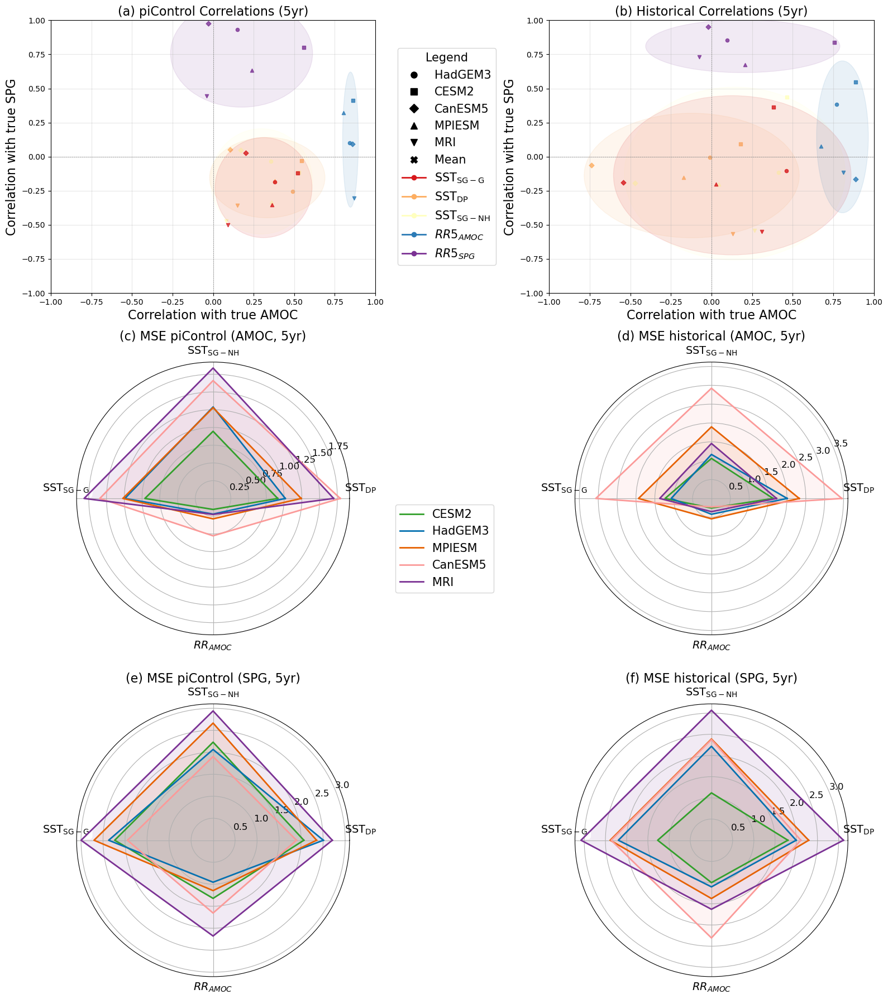

In [ ]:
from matplotlib.patches import Ellipse
import matplotlib.lines as mlines
import matplotlib.transforms as transforms

# === Setup ===
fingerprint_colors = {
    "caesar": "#d7191c",
    "dipole": "#fdae61",
    "spg": "#ffffbf",
    "ridge_MOC": "#2c7bb6",
    "ridge_SPG": "#7b3294"
}

model_markers = {
    "HadGEM3": "o",
    "CESM2": "s",
    "CanESM5": "D",
    "MPIESM": "^",
    "MRI": "v",
    "Mean": "X"
}



fingerprints = ["dipole", "spg", "caesar", "ridge_MOC", "ridge_SPG"]

# MSE categories
radar_categories = ['dipole_moc_mse', 'spg_moc_mse', 'caesar_moc_mse', 'ridge_MOC_moc_mse']
radar_categories_spg = ['dipole_spg_mse', 'spg_spg_mse', 'caesar_spg_mse', 'ridge_MOC_spg_mse']

label_names = [
    "$\\mathrm{SST}_{\\mathrm{DP}}$",
    "$\\mathrm{SST}_{\\mathrm{SG-NH}}$",
    "$\\mathrm{SST}_{\\mathrm{SG-G}}$",
    "$RR_{AMOC}$"
]

angles = np.linspace(0, 2 * np.pi, len(radar_categories), endpoint=False).tolist() + [0]
angles_spg = np.linspace(0, 2 * np.pi, len(radar_categories_spg), endpoint=False).tolist() + [0]

fingerprint_labels = {
    "caesar": "$\\mathrm{SST}_{\\mathrm{SG-G}}$",
    "dipole": "$\\mathrm{SST}_{\\mathrm{DP}}$",
    "spg": "$\\mathrm{SST}_{\\mathrm{SG-NH}}$",
    "ridge_MOC": "$RR5_{AMOC}$",
    "ridge_SPG": "$RR5_{SPG}$"
}

# === Create Figure and Axes ===
fig = plt.figure(figsize=(16, 18))
ax1 = fig.add_subplot(3, 2, 1)
ax2 = fig.add_subplot(3, 2, 2)
ax3 = fig.add_subplot(3, 2, 3, polar=True)
ax4 = fig.add_subplot(3, 2, 4, polar=True)
ax5 = fig.add_subplot(3, 2, 5, polar=True)
ax6 = fig.add_subplot(3, 2, 6, polar=True)


# === Panel (a) piControl correlation scatter ===
# === Panel (a) piControl correlation scatter ===
pi_corr_5yr = Fingerprint_pi_correlations_df[Fingerprint_pi_correlations_df["window"] == 5]

for fp in fingerprints:
    for _, row in pi_corr_5yr.iterrows():
        x = row.get(f"{fp}_moc_corr")
        y = row.get(f"{fp}_spg_corr")
        model = row["Model"]
        if x is None or y is None or pd.isna(x) or pd.isna(y):
            continue
        size = 200 if model == "Mean" else 20
        ax1.scatter(x, y, color=fingerprint_colors[fp], marker=model_markers[model], s=size, alpha=0.8)
    x_data = pi_corr_5yr[f"{fp}_moc_corr"].dropna()
    y_data = pi_corr_5yr[f"{fp}_spg_corr"].dropna()
    if len(x_data) > 0:
        mean_x, mean_y = np.mean(x_data), np.mean(y_data)
        std_x, std_y = np.std(x_data), np.std(y_data)
        ellipse = Ellipse((mean_x, mean_y), 4*std_x, 4*std_y, color=fingerprint_colors[fp], alpha=0.1)
        ax1.add_patch(ellipse)

ax1.axhline(0, color='grey', linestyle='--', linewidth=0.5)
ax1.axvline(0, color='grey', linestyle='--', linewidth=0.5)
ax1.set_xlim(-1, 1)
ax1.set_ylim(-1, 1)
ax1.set_title("(a) piControl Correlations (5yr)", fontsize=16)
ax1.set_xlabel("Correlation with true AMOC", fontsize=16)
ax1.set_ylabel("Correlation with true SPG", fontsize=16)
ax1.grid(alpha=0.3)



handles = [mlines.Line2D([], [], color='black', marker=m, linestyle='None', markersize=8, label=mod)
           for mod, m in model_markers.items()]
color_handles = [mlines.Line2D([], [], color=color, marker='o', linestyle='-', linewidth=2,
                               markersize=6, label=fingerprint_labels[fp])
                 for fp, color in fingerprint_colors.items()]
ax1.legend(handles=handles + color_handles, title="Legend", loc='center left', bbox_to_anchor=(1.05, 0.5),
           fontsize=15, title_fontsize=15)


# === Panel (b) historical correlation scatter ===
# === Panel (b) historical correlation scatter ===
hist_corr_5yr = Fingerprint_hist_correlations_df[Fingerprint_hist_correlations_df["window"] == 5]

for fp in fingerprints:
    for _, row in hist_corr_5yr.iterrows():
        x = row.get(f"{fp}_moc_corr")
        y = row.get(f"{fp}_spg_corr")
        model = row["Model"]
        if x is None or y is None or pd.isna(x) or pd.isna(y):
            continue
        size = 200 if model == "Mean" else 20
        ax2.scatter(x, y, color=fingerprint_colors[fp], marker=model_markers[model], s=size, alpha=0.8)
    x_data = hist_corr_5yr[f"{fp}_moc_corr"].dropna()
    y_data = hist_corr_5yr[f"{fp}_spg_corr"].dropna()
    if len(x_data) > 0:
        mean_x, mean_y = np.mean(x_data), np.mean(y_data)
        std_x, std_y = np.std(x_data), np.std(y_data)
        ellipse = Ellipse((mean_x, mean_y), 4*std_x, 4*std_y, color=fingerprint_colors[fp], alpha=0.1)
        ax2.add_patch(ellipse)

ax2.axhline(0, color='grey', linestyle='--', linewidth=0.5)
ax2.axvline(0, color='grey', linestyle='--', linewidth=0.5)
ax2.set_xlim(-1, 1)
ax2.set_ylim(-1, 1)
ax2.set_title("(b) Historical Correlations (5yr)", fontsize=16)
ax2.set_xlabel("Correlation with true AMOC", fontsize=16)
ax2.set_ylabel("Correlation with true SPG", fontsize=16)
ax2.grid(alpha=0.3)


# === Radar Panels Helper ===
def plot_radar(ax, df, cats, angles, title, window=5):
    df = df[(df['Model'] != 'Mean') & (df['window'] == window)]
    for _, row in df.iterrows():
        values = row[cats].values.flatten().tolist() + [row[cats[0]]]
        color = get_model_color(row['Model'])
        ax.plot(angles, values, label=row['Model'], linewidth=2, color=color)
        ax.fill(angles, values, color=color, alpha=0.1)
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(label_names, fontsize=14)
    ax.tick_params(axis='y', labelsize=12)
    ax.set_title(title, fontsize=16)

    for label, angle in zip(ax.get_xticklabels(), angles):
        angle_deg = np.degrees(angle)
        label.set_rotation_mode('anchor')
        label.set_rotation(angle_deg)
        label.set_horizontalalignment('center')
        if np.isclose(angle % (2 * np.pi), 0, atol=0.01) or np.isclose(angle % (2 * np.pi), np.pi, atol=0.01):
            offset = transforms.ScaledTranslation(0, 13/72, fig.dpi_scale_trans)
            label.set_transform(label.get_transform() + offset)
        label.set_bbox(dict(facecolor='white', edgecolor='none', alpha=1, boxstyle='round,pad=0.3'))

plot_radar(ax3, Fingerprint_pi_mse_df, radar_categories, angles, "(c) MSE piControl (AMOC, 5yr)", window=5)
plot_radar(ax4, Fingerprint_hist_mse_df, radar_categories, angles, "(d) MSE historical (AMOC, 5yr)", window=5)
plot_radar(ax5, Fingerprint_pi_mse_df, radar_categories_spg, angles_spg, "(e) MSE piControl (SPG, 5yr)", window=5)
plot_radar(ax6, Fingerprint_hist_mse_df, radar_categories_spg, angles_spg, "(f) MSE historical (SPG, 5yr)", window=5)

handles, labels = ax3.get_legend_handles_labels()
by_label = dict(zip(labels, handles))  # keeps first occurrence per model
ax3.legend(by_label.values(), by_label.keys(), loc='upper right', bbox_to_anchor=(1.55, 0.5), fontsize=15)

plt.tight_layout()
plt.savefig("fingerprint_panels.pdf")
plt.show()

In [ ]:

# from matplotlib.patches import Ellipse
# import matplotlib.lines as mlines
# import matplotlib.transforms as transforms
# # Setup
# fingerprint_colors = {"caesar": "brown", "dipole": "red", "spg": "orange", "ridge_MOC": "navy", "ridge_SPG": "darkcyan"}
# model_markers = {"HadGEM3": "o", "CESM2": "s", "CanESM5": "D", "MPIESM": "^", "MRI": "v", "Mean": "X"}
# fingerprints = ["dipole", "spg", "caesar", "ridge_MOC", "ridge_SPG"]
# radar_categories = ['dipole_moc_mse', 'spg_moc_mse', 'caesar_moc_mse', 'ridge_MOC_moc_mse']
# label_names = [
#     "$\\mathrm{SST}_{\\mathrm{DP}}$",
#     "$\\mathrm{SST}_{\\mathrm{SG-NH}}$",
#     "$\\mathrm{SST}_{\\mathrm{SG-G}}$",
#     "RR AMOC"
# ]

# angles = np.linspace(0, 2 * np.pi, len(radar_categories), endpoint=False).tolist()
# angles += angles[:1]  # complete the loop



# # Add fingerprint color legend
# fingerprint_labels = {
#     "caesar": "$\\mathrm{{SST}}_{{\\mathrm{{SG-G}}}}$",
#     "dipole": "$\\mathrm{{SST}}_{{\\mathrm{{DP}}}}$",
#     "spg": "$\\mathrm{{SST}}_{{\\mathrm{{SG-NH}}}}$",
#     "ridge_MOC": "RR AMOC",
#     "ridge_SPG": "RR SPG"
# }

# # Create multi-panel layout
# fig, axs = plt.subplots(2, 2, figsize=(16, 12))
# axs = axs.flatten()

# # --- Panel (a) piControl correlation scatter ---
# ax = axs[0]
# for fp in fingerprints:
#     for _, row in Fingerprint_pi_correlations_df.iterrows():
#         x = row.get(f"{fp}_moc_corr", None)
#         y = row.get(f"{fp}_spg_corr", None)
#         model = row["Model"]
#         if x is None or y is None:
#             continue
#         size = 200 if model == "Mean" else 20
#         ax.scatter(x, y, color=fingerprint_colors[fp], marker=model_markers[model], s=size, alpha=0.8)
#     x_data = Fingerprint_pi_correlations_df[f"{fp}_moc_corr"].dropna()
#     y_data = Fingerprint_pi_correlations_df[f"{fp}_spg_corr"].dropna()
#     if len(x_data) > 0:
#         mean_x, mean_y = np.mean(x_data), np.mean(y_data)
#         std_x, std_y = np.std(x_data), np.std(y_data)
#         ellipse = Ellipse((mean_x, mean_y), 4*std_x, 4*std_y, color=fingerprint_colors[fp], alpha=0.1)
#         ax.add_patch(ellipse)

# ax.axhline(0, color='grey', linestyle='--', linewidth=0.5)
# ax.axvline(0, color='grey', linestyle='--', linewidth=0.5)
# ax.set_xlim(-1, 1)
# ax.set_ylim(-1, 1)
# ax.set_title("(a) piControl Correlations", fontsize=16)
# ax.set_xlabel("Correlation with true AMOC", fontsize=16)
# ax.set_ylabel("Correlation with true SPG", fontsize=16)
# ax.grid(alpha=0.3)
# # Add legend to panel (b)
# handles = []
# for model, marker in model_markers.items():
#     h = mlines.Line2D([], [], color='black', marker=marker, linestyle='None',
#                       markersize=8, label=model)
#     handles.append(h)


# color_handles = [
#     mlines.Line2D([], [], color=color, marker='o', linestyle='-', linewidth=2,
#                   markersize=6, label=fingerprint_labels[fp])
#     for fp, color in fingerprint_colors.items()
# ]

# combined_handles = handles + color_handles
# ax.legend(handles=combined_handles, title="Legend", loc='center left', bbox_to_anchor=(1.05, 0.5),fontsize=15,title_fontsize=15 )



# # --- Panel (b) historical correlation scatter ---
# ax = axs[1]
# for fp in fingerprints:
#     for _, row in Fingerprint_hist_correlations_df.iterrows():
#         x = row.get(f"{fp}_moc_corr", None)
#         y = row.get(f"{fp}_spg_corr", None)
#         model = row["Model"]
#         if x is None or y is None:
#             continue
#         size = 200 if model == "Mean" else 20
#         ax.scatter(x, y, color=fingerprint_colors[fp], marker=model_markers[model], s=size, alpha=0.8)
#     x_data = Fingerprint_hist_correlations_df[f"{fp}_moc_corr"].dropna()
#     y_data = Fingerprint_hist_correlations_df[f"{fp}_spg_corr"].dropna()
#     if len(x_data) > 0:
#         mean_x, mean_y = np.mean(x_data), np.mean(y_data)
#         std_x, std_y = np.std(x_data), np.std(y_data)
#         ellipse = Ellipse((mean_x, mean_y), 4*std_x, 4*std_y, color=fingerprint_colors[fp], alpha=0.1)
#         ax.add_patch(ellipse)

# ax.axhline(0, color='grey', linestyle='--', linewidth=0.5)
# ax.axvline(0, color='grey', linestyle='--', linewidth=0.5)
# ax.set_xlim(-1, 1)
# ax.set_ylim(-1, 1)
# ax.set_title("(b) Historical Correlations", fontsize=16)
# ax.set_xlabel("Correlation with true AMOC", fontsize=16)
# ax.set_ylabel("Correlation with true SPG" ,fontsize=16)
# ax.grid(alpha=0.3)

# # --- Panel (c) piControl radar (your original style) ---
# ax = plt.subplot(2, 2, 3, polar=True)
# df = Fingerprint_pi_mse_df.copy()
# df = df[df['Model'] != 'Mean']
# for _, row in df.iterrows():
#     values = row[radar_categories].values.flatten().tolist()
#     values += values[:1]
#     ax.plot(angles, values, label=row['Model'], linewidth=2)
#     ax.fill(angles, values, alpha=0.1)
# ax.tick_params(axis='y', labelsize=12)
# # Adjust radar label positions (push them outward)
# ax.set_xticks(angles[:-1])
# ax.set_xticklabels(label_names, fontsize=14)
# for label, angle in zip(ax.get_xticklabels(), angles):
#     angle_deg = np.degrees(angle)
#     label.set_rotation_mode('anchor')
#     label.set_rotation(angle_deg)
#     label.set_horizontalalignment('center')

#     # Offset only left (180°) and right (0°) labels
#     if np.isclose(angle % (2 * np.pi), 0, atol=0.01) or np.isclose(angle % (2 * np.pi), np.pi, atol=0.01):
#         # Create an offset transform in display coordinates (pixels)
#         offset = transforms.ScaledTranslation(0, 13/72, fig.dpi_scale_trans)  # 10 points = 10/72 inch
#         label.set_transform(label.get_transform() + offset)

#     # Add soft white background
#     label.set_bbox(dict(
#         facecolor='white',
#         edgecolor='none',
#         alpha=1,
#         boxstyle='round,pad=0.3'
#     ))


# ax.set_title("(c) MSE piControl", fontsize=16)
# ax.legend(loc='upper right', bbox_to_anchor=(1.55, 0.5), fontsize=15)
# #ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.0))

# # --- Panel (d) historical radar (your original style) ---
# ax = plt.subplot(2, 2, 4, polar=True)
# df = Fingerprint_hist_mse_df.copy()
# df = df[df['Model'] != 'Mean']
# for _, row in df.iterrows():
#     values = row[radar_categories].values.flatten().tolist()
#     values += values[:1]
#     ax.plot(angles, values, label=row['Model'], linewidth=2)
#     ax.fill(angles, values, alpha=0.1)
# ax.tick_params(axis='y', labelsize=12)
# ax.set_xticks(angles[:-1])
# ax.set_xticklabels(label_names, fontsize=14)


# for label, angle in zip(ax.get_xticklabels(), angles):
#     angle_deg = np.degrees(angle)
#     label.set_rotation_mode('anchor')
#     label.set_rotation(angle_deg)
#     label.set_horizontalalignment('center')

#     # Offset only left (180°) and right (0°) labels
#     if np.isclose(angle % (2 * np.pi), 0, atol=0.01) or np.isclose(angle % (2 * np.pi), np.pi, atol=0.01):
#         # Create an offset transform in display coordinates (pixels)
#         offset = transforms.ScaledTranslation(0, 13/72, fig.dpi_scale_trans)  # 10 points = 10/72 inch
#         label.set_transform(label.get_transform() + offset)

#     # Add soft white background
#     label.set_bbox(dict(
#         facecolor='white',
#         edgecolor='none',
#         alpha=1,
#         boxstyle='round,pad=0.3'
#     ))



# ax.set_title("(d) MSE historical", fontsize=16)


# # --- Save and show ---
# plt.tight_layout()
# plt.savefig("fingerprint_panels.pdf")
# plt.show()





In [ ]:
input("Press Enter to continue...")


'33qdCzMK'

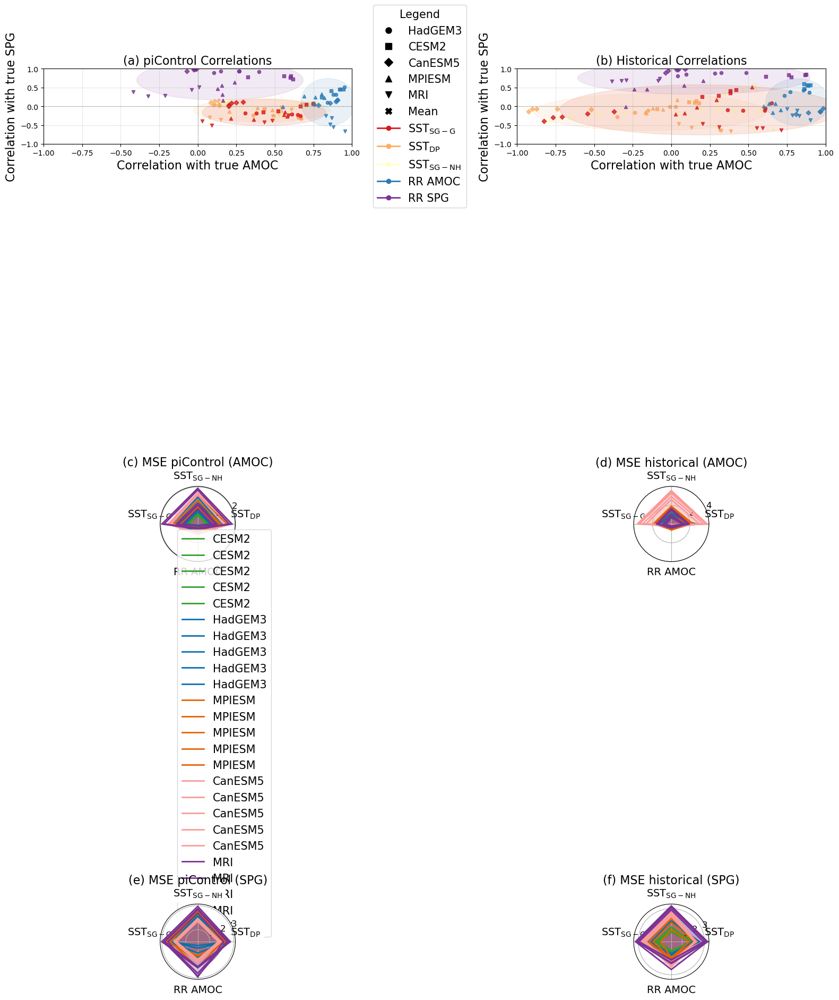

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import matplotlib.lines as mlines
import matplotlib.transforms as transforms

# === Setup ===
fingerprint_colors = {
    "caesar": "#d7191c",
    "dipole": "#fdae61",
    "spg": "#ffffbf",
    "ridge_MOC": "#2c7bb6",
    "ridge_SPG": "#7b3294"
}

model_markers = {
    "HadGEM3": "o",
    "CESM2": "s",
    "CanESM5": "D",
    "MPIESM": "^",
    "MRI": "v",
    "Mean": "X"
}


fingerprints = ["dipole", "spg", "caesar", "ridge_MOC", "ridge_SPG"]

# MSE categories
radar_categories = ['dipole_moc_mse', 'spg_moc_mse', 'caesar_moc_mse', 'ridge_MOC_moc_mse']
radar_categories_spg = ['dipole_spg_mse', 'spg_spg_mse', 'caesar_spg_mse', 'ridge_MOC_spg_mse']

label_names = [
    "$\\mathrm{SST}_{\\mathrm{DP}}$",
    "$\\mathrm{SST}_{\\mathrm{SG-NH}}$",
    "$\\mathrm{SST}_{\\mathrm{SG-G}}$",
    "RR AMOC"
]

angles = np.linspace(0, 2 * np.pi, len(radar_categories), endpoint=False).tolist() + [0]
angles_spg = np.linspace(0, 2 * np.pi, len(radar_categories_spg), endpoint=False).tolist() + [0]

fingerprint_labels = {
    "caesar": "$\\mathrm{SST}_{\\mathrm{SG-G}}$",
    "dipole": "$\\mathrm{SST}_{\\mathrm{DP}}$",
    "spg": "$\\mathrm{SST}_{\\mathrm{SG-NH}}$",
    "ridge_MOC": "RR AMOC",
    "ridge_SPG": "RR SPG"
}

# === Create Figure and Axes ===
fig = plt.figure(figsize=(16, 18))
ax1 = fig.add_subplot(3, 2, 1)
ax2 = fig.add_subplot(3, 2, 2)
ax3 = fig.add_subplot(3, 2, 3, polar=True)
ax4 = fig.add_subplot(3, 2, 4, polar=True)
ax5 = fig.add_subplot(3, 2, 5, polar=True)
ax6 = fig.add_subplot(3, 2, 6, polar=True)


# === Panel (a) piControl correlation scatter ===
for fp in fingerprints:
    for _, row in Fingerprint_pi_correlations_df.iterrows():
        x = row.get(f"{fp}_moc_corr")
        y = row.get(f"{fp}_spg_corr")
        model = row["Model"]
        if x is None or y is None:
            continue
        size = 200 if model == "Mean" else 20
        ax1.scatter(x, y, color=fingerprint_colors[fp], marker=model_markers[model], s=size, alpha=0.8)
    x_data = Fingerprint_pi_correlations_df[f"{fp}_moc_corr"].dropna()
    y_data = Fingerprint_pi_correlations_df[f"{fp}_spg_corr"].dropna()
    if len(x_data) > 0:
        mean_x, mean_y = np.mean(x_data), np.mean(y_data)
        std_x, std_y = np.std(x_data), np.std(y_data)
        ellipse = Ellipse((mean_x, mean_y), 4*std_x, 4*std_y, color=fingerprint_colors[fp], alpha=0.1)
        ax1.add_patch(ellipse)

ax1.axhline(0, color='grey', linestyle='--', linewidth=0.5)
ax1.axvline(0, color='grey', linestyle='--', linewidth=0.5)
ax1.set_xlim(-1, 1)
ax1.set_ylim(-1, 1)
ax1.set_title("(a) piControl Correlations", fontsize=16)
ax1.set_xlabel("Correlation with true AMOC", fontsize=16)
ax1.set_ylabel("Correlation with true SPG", fontsize=16)
ax1.grid(alpha=0.3)

# Add legend to ax1
handles = [mlines.Line2D([], [], color='black', marker=m, linestyle='None', markersize=8, label=mod)
           for mod, m in model_markers.items()]
color_handles = [mlines.Line2D([], [], color=color, marker='o', linestyle='-', linewidth=2,
                               markersize=6, label=fingerprint_labels[fp])
                 for fp, color in fingerprint_colors.items()]
ax1.legend(handles=handles + color_handles, title="Legend", loc='center left', bbox_to_anchor=(1.05, 0.5),
           fontsize=15, title_fontsize=15)


# === Panel (b) historical correlation scatter ===
for fp in fingerprints:
    for _, row in Fingerprint_hist_correlations_df.iterrows():
        x = row.get(f"{fp}_moc_corr")
        y = row.get(f"{fp}_spg_corr")
        model = row["Model"]
        if x is None or y is None:
            continue
        size = 200 if model == "Mean" else 20
        ax2.scatter(x, y, color=fingerprint_colors[fp], marker=model_markers[model], s=size, alpha=0.8)
    x_data = Fingerprint_hist_correlations_df[f"{fp}_moc_corr"].dropna()
    y_data = Fingerprint_hist_correlations_df[f"{fp}_spg_corr"].dropna()
    if len(x_data) > 0:
        mean_x, mean_y = np.mean(x_data), np.mean(y_data)
        std_x, std_y = np.std(x_data), np.std(y_data)
        ellipse = Ellipse((mean_x, mean_y), 4*std_x, 4*std_y, color=fingerprint_colors[fp], alpha=0.1)
        ax2.add_patch(ellipse)

ax2.axhline(0, color='grey', linestyle='--', linewidth=0.5)
ax2.axvline(0, color='grey', linestyle='--', linewidth=0.5)
ax2.set_xlim(-1, 1)
ax2.set_ylim(-1, 1)
ax2.set_title("(b) Historical Correlations", fontsize=16)
ax2.set_xlabel("Correlation with true AMOC", fontsize=16)
ax2.set_ylabel("Correlation with true SPG", fontsize=16)
ax2.grid(alpha=0.3)


# === Radar Panels Helper ===
def plot_radar(ax, df, cats, angles, title):
    df = df[df['Model'] != 'Mean']
    for _, row in df.iterrows():
        values = row[cats].values.flatten().tolist() + [row[cats[0]]]  # close the loop
        color = get_model_color(row['Model'])

        ax.plot(
            angles,
            values,
            label=row['Model'],
            linewidth=2,
            color=color
        )

        ax.fill(
            angles,
            values,
            color=color,
            alpha=0.1
        )
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(label_names, fontsize=14)
    ax.tick_params(axis='y', labelsize=12)
    ax.set_title(title, fontsize=16)

    for label, angle in zip(ax.get_xticklabels(), angles):
        angle_deg = np.degrees(angle)
        label.set_rotation_mode('anchor')
        label.set_rotation(angle_deg)
        label.set_horizontalalignment('center')
        if np.isclose(angle % (2 * np.pi), 0, atol=0.01) or np.isclose(angle % (2 * np.pi), np.pi, atol=0.01):
            offset = transforms.ScaledTranslation(0, 13/72, fig.dpi_scale_trans)
            label.set_transform(label.get_transform() + offset)
        label.set_bbox(dict(facecolor='white', edgecolor='none', alpha=1, boxstyle='round,pad=0.3'))


# === Panel (c) MSE piControl vs AMOC ===
plot_radar(ax3, Fingerprint_pi_mse_df, radar_categories, angles, "(c) MSE piControl (AMOC)")
ax3.legend(loc='upper right', bbox_to_anchor=(1.55, 0.5), fontsize=15)

# === Panel (d) MSE hist vs AMOC ===
plot_radar(ax4, Fingerprint_hist_mse_df, radar_categories, angles, "(d) MSE historical (AMOC)")

# === Panel (e) MSE piControl vs SPG ===
plot_radar(ax5, Fingerprint_pi_mse_df, radar_categories_spg, angles_spg, "(e) MSE piControl (SPG)")

# === Panel (f) MSE hist vs SPG ===
plot_radar(ax6, Fingerprint_hist_mse_df, radar_categories_spg, angles_spg, "(f) MSE historical (SPG)")


# === Finalize and Save ===
plt.tight_layout()
plt.savefig("fingerprint_panels.pdf")
plt.show()
